# Predicción del puntaje global de la prueba Saber 11 a partir de variables socioeconómicas y del colegio

### Andrés Giovanny Rubiano Muñoz "Andy Rubiano"

**Maestría en Inteligencia Artificial**
**Universidad de La Salle**

**Ciencia de Datos** · Docente: Fabián Camilo Castro Riveros

---

**Actividad:** Proyecto Integrador de Ciencia de Datos e Inteligencia Artificial | Fase 1 · Actividad 2: *Planteamiento del problema, objetivos y análisis exploratorio* (**Entregable 1**), según la *Guía técnica detallada* del proyecto.

**Caso de estudio:** *Resultados únicos Saber 11*, publicado por el ICFES en el Portal Nacional de Datos Abiertos de Colombia (datos.gov.co). Periodo **2022-4** (calendario A, segundo semestre de 2022).

**Dataset utilizado:** [`andyrubiano/saber-11-muestra-2022-4`](https://www.kaggle.com/datasets/andyrubiano/saber-11-muestra-2022-4) en Kaggle: muestra estratificada de **1.000 estudiantes** con las 51 columnas originales, extraída de los 532.792 estudiantes únicos del periodo.

**Variable objetivo (regresión):** `punt_global`, puntaje global del estudiante (0 a 500). **Variable de clasificación derivada:** nivel de desempeño (bajo, medio, alto) por terciles del puntaje global. **Variables de segmentación (clustering):** los cinco puntajes por área y la edad.

**Licencia de los datos:** Creative Commons Attribution-ShareAlike 4.0 (CC BY-SA 4.0).

**Contenido:** planteamiento (pregunta principal, tres secundarias, objetivos SMART) · ficha técnica y diccionario de las 51 columnas · calidad de los datos (faltantes y su mecanismo, valores atípicos, duplicados, incoherencias) · análisis univariado, bivariado y multivariado (correlaciones, dispersión, pruebas χ²) · idoneidad del dataset para regresión, clasificación y clustering.

## 1. Planteamiento del problema

La prueba Saber 11 es el examen de Estado que presentan en Colombia todos los estudiantes que terminan la educación media. Su puntaje global decide en buena medida el acceso a la educación superior, a becas como *Generación E* y a los cupos de las universidades públicas, de modo que entender **qué factores, ajenos al esfuerzo individual del estudiante, se asocian con un puntaje alto o bajo** tiene consecuencias directas sobre la equidad del sistema educativo. Una solución analítica que cuantifique esas asociaciones, anticipe el nivel de desempeño y agrupe a los estudiantes por perfil permitiría a un secretario de educación, a un rector o al propio ICFES decidir dónde concentrar jornadas completas, conectividad o programas de nivelación, en lugar de actuar sobre promedios que ocultan la desigualdad.

El ICFES publica, por cada aplicación, un registro anónimo por estudiante con el resultado de la prueba y un cuestionario sociodemográfico sobre su hogar y su colegio. Ese registro permite plantear **tres problemas** sobre los mismos datos: una **regresión** (predecir el puntaje global), una **clasificación** (predecir si el estudiante queda en nivel bajo, medio o alto) y una **segmentación no supervisada** (descubrir perfiles de estudiantes según sus puntajes por área).

### 1.1 Preguntas de investigación

**Pregunta principal.**

> ¿En qué medida las características socioeconómicas del hogar, del colegio y del estudiante permiten predecir el desempeño en la prueba Saber 11, y cuáles de esas características pesan más?

**Preguntas secundarias.**

1. **(Regresión)** ¿Qué variables del hogar, del colegio, del estudiante y de la geografía se asocian más con el puntaje global, y cuánto aporta cada bloque?
2. **(Clasificación)** ¿Pueden esas mismas variables clasificar a un estudiante en nivel de desempeño bajo, medio o alto, y con qué exactitud frente al azar?
3. **(Clustering)** ¿Existen perfiles naturales de estudiantes según sus puntajes por área y su edad, y qué rasgos de contexto distinguen a cada perfil?

### 1.2 Objetivos (formato SMART)

**Objetivo general.** Entre el 20 de octubre y el 28 de noviembre de 2026, desarrollar y desplegar una solución analítica reproducible en Google Colab que prediga el puntaje global y el nivel de desempeño de los estudiantes de Saber 11 a partir de su contexto socioeconómico y escolar, y que los segmente por perfil académico, con un tablero interactivo para explorar los resultados.

**Objetivos específicos.**

1. **Documentar, explorar y preparar los datos** (Entregables 1 y 2, hasta el 15 de noviembre): diccionario del 100 % de las columnas, análisis exploratorio univariado, bivariado y de independencia, tratamiento justificado del 100 % de las variables con faltantes y de los valores atípicos, al menos dos variables derivadas, partición entrenamiento, validación y prueba sin fuga de datos, y un modelo de referencia.
2. **Modelar y evaluar** (Entregable 3, hasta el 22 de noviembre): regresión (un modelo lineal regularizado y un ensamble de árboles), clasificación con dos algoritmos distintos, clustering con K-means (codo y silueta) y un segundo algoritmo (DBSCAN o jerárquico), un perceptrón multicapa en PyTorch con su curva de pérdida, hiperparámetros ajustados con validación cruzada y análisis de interpretabilidad (SHAP e importancia de variables).
3. **Comunicar y entregar** (Entregable 4, hasta el 28 de noviembre): tablero interactivo desplegado con filtros, tarjetas de indicadores, predicción en vivo y mapa de clústeres, repositorio público con `requirements.txt` de versiones exactas y sustentación oral de 12 minutos.

| Objetivo | Específico | Medible | Alcanzable | Relevante | Temporal |
|---|---|---|---|---|---|
| **General** | Predecir, clasificar y segmentar el desempeño en Saber 11 y comunicarlo en un tablero | MAE al menos 15 % menor que el de predecir la media; F1 macro ≥ 0,50 (el azar da 0,33); silueta media ≥ 0,20; tablero con 4 módulos | Muestra de 1.000 estudiantes; modelos que entrenan en segundos en Colab; el ajuste lineal exploratorio (sección 10.4) ya supera la media | Equidad en el acceso a la educación superior | 28 nov. 2026 |
| **E1** | Documentar, explorar y preparar los datos | 51 de 51 columnas documentadas; 100 % de faltantes y atípicos tratados con justificación; ≥ 2 variables derivadas; partición 70/15/15 sin fuga | Datos públicos, sin cuenta, 418 KB | Una preparación sin fuga sostiene todas las métricas posteriores | 15 nov. 2026 |
| **E2** | Modelar y evaluar | 2 modelos de regresión, 2 de clasificación, 2 de clustering y 1 MLP; validación cruzada de 5 pliegues; SHAP | Cada modelo entrena en segundos con 1.000 filas | Responde las preguntas secundarias 1 a 3 | 22 nov. 2026 |
| **E3** | Comunicar y entregar | Tablero en vivo con 4 módulos; repositorio con versiones exactas; 12 minutos de exposición | Streamlit gratuito y repositorio público | El docente y terceros pueden reproducir y explorar el resultado | 28 nov. 2026 |

### 1.3 Hipótesis de trabajo

- **H1.** El nivel socioeconómico del hogar (estrato, educación de los padres, acceso a internet y computador) es el grupo de variables con mayor asociación con el puntaje global.
- **H2.** Las características del colegio (naturaleza oficial o privada, área urbana o rural, jornada, calendario) aportan información adicional a la del hogar.
- **H3.** Existe una brecha regional: el departamento donde se ubica el colegio se asocia con el puntaje incluso después de considerar el hogar y el colegio.
- **H4.** Los puntajes por área y la edad separan perfiles de estudiantes con características de contexto diferenciadas.

### 1.4 Alcance y restricciones

- **Tamaño del conjunto.** El docente fijó un tamaño de entre 600 y 1.000 registros; se trabaja con **1.000 estudiantes** elegidos por muestreo estratificado de los 532.792 estudiantes únicos del periodo (sección 3.1). Los resultados describen a esa muestra y, por haber sido estratificada, se verifica su representatividad frente a la población (sección 3.3).
- **Fuga de información.** Los puntajes por área (`punt_matematicas`, `punt_lectura_critica`, `punt_sociales_ciudadanas`, `punt_c_naturales`, `punt_ingles`) y el nivel de inglés (`desemp_ingles`) **no pueden usarse como variables explicativas** en regresión ni en clasificación, porque el puntaje global se calcula a partir de ellos. Sí se usan, en cambio, como variables de **segmentación** en el clustering, donde no hay variable que predecir. El cuaderno verifica esa relación sobre los datos.
- **Variables geográficas.** Con 1.000 filas no es viable usar el municipio (más de mil niveles); el departamento se analiza con la cautela que impone el tamaño de cada grupo y se propone agruparlo en regiones para el modelado.
- **Alcance inferencial.** El análisis es correlacional: identifica asociaciones útiles para predecir y segmentar, no relaciones causales.

### 1.5 Propuesta de solución analítica

La propuesta responde a las tres preguntas secundarias con una cadena de trabajo única, que parte de este cuaderno y llega al tablero:

| Tarea | Objetivo | Algoritmos propuestos | Métricas | Validación |
|---|---|---|---|---|
| **Referencia** | Fijar el umbral mínimo | Predecir la media (`DummyRegressor`) y regresión lineal regularizada | MAE, RMSE, R² | Partición 70/15/15 |
| **Regresión** | `punt_global` | Ridge, Lasso o ElasticNet; Random Forest y Gradient Boosting; perceptrón multicapa en PyTorch | R², RMSE, MAE | Validación cruzada de 5 pliegues y búsqueda de hiperparámetros |
| **Clasificación** | `nivel_desempeno` (bajo, medio, alto) | Regresión logística como referencia; Random Forest y XGBoost (SVM o KNN como alternativas) | Exactitud, precisión, exhaustividad, F1 macro, AUC-ROC | Validación cruzada estratificada |
| **Clustering** | Perfiles por puntajes por área y edad | K-means con método del codo y silueta; DBSCAN o clustering jerárquico aglomerativo | Silueta, perfiles de cada clúster | Estabilidad frente a la semilla y la escala |
| **Interpretabilidad** | Qué variables pesan y para quién | SHAP, importancia por permutación, dependencia parcial, componentes principales | Estabilidad entre métodos | Muestra de prueba |
| **Producto** | Explorar y usar el resultado | Tablero interactivo desplegado (Streamlit) con filtros, indicadores, predicción en vivo y mapa de clústeres | Funcionamiento en vivo | Demostración |

El análisis de este cuaderno fija las decisiones de preparación que alimentan esa cadena (sección 12): qué variables se excluyen por fuga de información, cómo se tratan los faltantes y los valores atípicos, qué columnas se descartan y qué variables se derivan.

## 2. Preparación del entorno

El cuaderno está diseñado para ejecutarse en **Google Colab** sin instalación adicional, puesto que todas las dependencias (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn` y `kagglehub`) vienen preinstaladas; también corre de forma local sobre el repositorio del proyecto con `pip install -r requirements.txt`.

Se importan las librerías agrupadas por propósito:

*   **Utilidades estándar** (`os`, `sys`, `time`, `warnings`, `pathlib`): rutas, tiempos y silenciamiento de advertencias.
*   **Manipulación de datos** (`numpy`, `pandas`): carga, transformación y agregación del conjunto.
*   **Visualización** (`matplotlib`, `seaborn`): todas las figuras del análisis exploratorio.
*   **Estadística** (`scipy.stats`): correlación de Spearman y pruebas de asociación.
*   **Descarga de datos** (`kagglehub`): se importa dentro de la celda de carga de la sección 3.

Al final se resuelven las rutas del proyecto. Si el cuaderno corre dentro del repositorio, `PROJECT_ROOT` apunta a su raíz y las figuras se guardan en `assets/images/data/`, que es de donde las toma el informe; en Colab se crea la misma estructura bajo `/content/saber11-project`. El conjunto de datos no se guarda en el repositorio: `kagglehub` lo descarga a su propia caché.

In [1]:
import os, sys, time, warnings, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns
import scipy
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__,
      "| seaborn:", sns.__version__, "| scipy:", scipy.__version__)

IN_COLAB = "google.colab" in sys.modules

def find_project_root(start=Path.cwd()):
    """Sube por el árbol de carpetas hasta encontrar la raíz del repositorio (README.md + notebooks/)."""
    for candidate in [start, *start.parents]:
        if (candidate / "README.md").exists() and (candidate / "notebooks").is_dir():
            return candidate
    return start

PROJECT_ROOT = Path("/content/saber11-project") if IN_COLAB else find_project_root()
FIG_DIR = PROJECT_ROOT / "assets" / "images" / "data"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
for carpeta in (FIG_DIR, PROCESSED_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

print(f"Entorno        : {'Google Colab' if IN_COLAB else 'local'}")
print(f"Raíz del proyecto: {PROJECT_ROOT}")

pandas: 3.0.6 | numpy: 2.5.4 | matplotlib: 3.11.2 | seaborn: 0.13.2 | scipy: 1.18.1
Entorno        : local
Raíz del proyecto: D:\Universidad de La Salle\2do semestre\Ciencia de datos\Proyecto final\saber11-project


Luego se define la identidad gráfica de todas las visualizaciones del cuaderno, de modo que compartan paleta, tipografía y estilo:

*   **Paleta de colores**: un azul (`C_BASE`) para la variable objetivo y las series principales, un naranja (`C_ACCENT`) para contrastes, un tono neutro (`C_NEU`) para descripciones del conjunto y tonos de tinta y gris para textos y ejes. Para las variables ordinales (estrato, educación de los padres) se usa una escala secuencial (`CMAP_SEQ`) en la que un tono más oscuro significa un nivel más alto.
*   **Configuración global** (`plt.rcParams` y `seaborn`): cuadrícula sutil, sin bordes superior ni derecho, títulos en negrilla alineados a la izquierda y 110 dpi.
*   **Semilla global** `RANDOM_STATE = 42`, que gobierna cualquier muestreo del cuaderno.
*   **Función `save_fig`**: guarda cada figura en `assets/images/data/` con el nombre que después cita el informe.

In [2]:
C_BASE, C_ACCENT, C_NEU = "#2a78d6", "#eb6834", "#5B7C99"
TINTA, GRIS = "#0b0b0b", "#52514e"
PALETTE = [C_BASE, C_ACCENT, "#2CA02C", "#9467BD", "#8C564B", "#E377C2", "#7F7F7F", "#BCBD22"]
CMAP_SEQ = "Blues"

sns.set_style("whitegrid")
sns.set_palette(PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#d9d8d3", "axes.labelcolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "grid.color": "#eeede9", "grid.linewidth": 0.8,
})

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def save_fig(fig, name):
    """Guarda la figura en assets/images/data/<name>.png (de ahí la toma el informe)."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"Figura guardada: {path.relative_to(PROJECT_ROOT) if path.is_relative_to(PROJECT_ROOT) else path}")

## 3. Carga y descripción del conjunto de datos

### 3.1 Origen, licencia, tamaño y diseño de la muestra

El conjunto **Resultados únicos Saber 11** es publicado por el Instituto Colombiano para la Evaluación de la Educación (ICFES) en el Portal Nacional de Datos Abiertos de Colombia ([datos.gov.co/d/kgxf-xxbe](https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe)) bajo licencia **CC BY-SA 4.0**. Reúne 7,1 millones de registros anónimos de las aplicaciones entre 2010 y 2022, con 51 columnas. El periodo **2022-4** (calendario A del segundo semestre de 2022) es el más reciente y numeroso: el portal lo publica con 1.065.888 filas que corresponden a **532.792 estudiantes únicos**, porque cada registro aparece repetido.

**Diseño de la muestra.** El docente fijó un tamaño de entre 600 y 1.000 registros, así que el proyecto trabaja con **n = 1.000 estudiantes**, el máximo permitido, que da las estimaciones más estables. La muestra se extrajo de los 532.792 estudiantes únicos con estas reglas:

*   **Estratos**: naturaleza del colegio (oficial o no oficial) × área (urbana o rural) × tercil del puntaje global, 12 estratos en total. Se eligieron porque son las variables que más separan el puntaje (fase de exploración) y porque estratificar por el tercil del puntaje reproduce la distribución de la variable objetivo.
*   **Asignación proporcional** al tamaño de cada estrato (método del mayor resto), de modo que el 1.000 se reparte sin sesgo.
*   **Selección aleatoria simple** dentro de cada estrato, con la semilla `42`, sobre los estudiantes ordenados por identificador, lo que la hace reproducible bit a bit.

La muestra se publicó en Kaggle como un dataset propio de 418 KB (**`andyrubiano/saber-11-muestra-2022-4`**), junto con un archivo de referencia con las distribuciones de la población que permite verificar la representatividad sin descargarla. Si ese dataset no estuviera disponible, la celda siguiente reconstruye **exactamente la misma muestra** desde la copia de la población en Kaggle con la función `muestrear_poblacion`.

Una medición previa, hecha con la población completa fuera de este cuaderno, indica qué se pierde al trabajar con 1.000 filas: un modelo de boosting entrenado con 1.000 estudiantes y evaluado sobre 79.919 estudiantes que nunca vio alcanza un R² medio de 0,29 (desviación 0,01 entre 20 muestras), frente a 0,40 con 372.954 estudiantes. Es una pérdida real y conocida, y la contrapartida es un proyecto que corre completo en Colab en minutos.

La descarga de la muestra usa **kagglehub**, que viene preinstalado en Colab y no requiere cuenta para un dataset público. Las columnas categóricas llegan como `category`, los identificadores como texto y los puntajes como numéricos.

In [3]:
import kagglehub

KAGGLE_MUESTRA = "andyrubiano/saber-11-muestra-2022-4"
KAGGLE_POBLACION = "andyrubiano/saber-11-resultados-2022-4"
CSV_MUESTRA, JSON_REF = "saber11_muestra_1000.csv", "poblacion_referencia.json"
N_MUESTRA, SEMILLA_MUESTRA, PERIODO = 1000, 42, "20224"

SCORE_COLS = ["punt_matematicas", "punt_lectura_critica", "punt_sociales_ciudadanas",
              "punt_c_naturales", "punt_ingles", "punt_global"]
ID_COLS = ["estu_consecutivo", "estu_fechanacimiento"]
REF_CAT = ["cole_naturaleza", "cole_area_ubicacion", "cole_jornada", "cole_caracter", "cole_calendario", "estu_genero",
           "fami_estratovivienda", "fami_educacionmadre", "fami_tieneinternet", "fami_tienecomputador", "cole_depto_ubicacion"]
REF_NUM = ["punt_lectura_critica", "punt_matematicas", "punt_sociales_ciudadanas", "punt_c_naturales", "punt_ingles", "punt_global"]

def muestrear_poblacion():
    """Respaldo determinista: reconstruye la muestra y su referencia desde la población completa en Kaggle."""
    pob = pd.read_parquet(kagglehub.dataset_download(KAGGLE_POBLACION, path="saber11_20224.parquet"))
    n_publicadas = len(pob)
    pob = pob.drop_duplicates().sort_values("estu_consecutivo").reset_index(drop=True)
    nat = pob["cole_naturaleza"].astype(object).fillna("NA")
    area = pob["cole_area_ubicacion"].astype(object).fillna("NA")
    tercil = pd.qcut(pob["punt_global"], 3, labels=["T1", "T2", "T3"]).astype(str)
    estrato = (nat + "|" + area + "|" + tercil).to_numpy()
    conteo = pd.Series(estrato).value_counts().sort_index()
    cuota = conteo / conteo.sum() * N_MUESTRA
    base = np.floor(cuota).astype(int)
    base[(cuota - base).sort_values(ascending=False).index[:N_MUESTRA - base.sum()]] += 1
    rs = np.random.RandomState(SEMILLA_MUESTRA)
    elegidos = []
    for clave, k in base.items():
        elegidos.extend(rs.choice(np.flatnonzero(estrato == clave), size=int(k), replace=False))
    muestra = pob.iloc[sorted(elegidos)].reset_index(drop=True)
    ref = {"semilla": SEMILLA_MUESTRA, "n_muestra": N_MUESTRA, "n_publicadas_poblacion": int(n_publicadas),
           "n_unicas_poblacion": int(len(pob)), "marginales": {}, "numericas": {}}
    for c in REF_CAT:
        ref["marginales"][c] = (pob[c].astype(object).fillna("Sin dato").value_counts(normalize=True) * 100).round(4).to_dict()
    for c in REF_NUM:
        s = pob[c].astype(float)
        ref["numericas"][c] = {"media": round(float(s.mean()), 4), "desviacion": round(float(s.std()), 4), "mediana": float(s.median())}
    return muestra, ref

t0 = time.time()
try:
    ruta_csv = kagglehub.dataset_download(KAGGLE_MUESTRA, path=CSV_MUESTRA)
    ruta_ref = kagglehub.dataset_download(KAGGLE_MUESTRA, path=JSON_REF)
    cabecera = pd.read_csv(ruta_csv, nrows=0).columns.tolist()
    dtypes = {c: "category" for c in cabecera if c not in SCORE_COLS + ID_COLS}
    dtypes.update({c: "float32" for c in SCORE_COLS})
    dtypes.update({c: "string" for c in ID_COLS})
    df = pd.read_csv(ruta_csv, dtype=dtypes)
    REF = json.load(open(ruta_ref, encoding="utf-8"))
    FUENTE = f"Kaggle · {KAGGLE_MUESTRA} · {CSV_MUESTRA}"
except Exception as error:
    print(f"Muestra publicada no disponible ({type(error).__name__}); se reconstruye desde la población con la misma semilla.")
    df, REF = muestrear_poblacion()
    FUENTE = f"Kaggle · {KAGGLE_POBLACION} · muestreo determinista (semilla {SEMILLA_MUESTRA})"

assert len(df) == N_MUESTRA and df["estu_consecutivo"].is_unique
print(f"Fuente   : {FUENTE}")
print(f"Origen   : ICFES · datos.gov.co, conjunto kgxf-xxbe, periodo 2022-4 (CC BY-SA 4.0)")
print(f"Población: {REF['n_publicadas_poblacion']:,} filas publicadas · {REF['n_unicas_poblacion']:,} estudiantes únicos")
print(f"Registros: {len(df):,} | Columnas: {df.shape[1]} | Memoria: {df.memory_usage(deep=True).sum() / 1e6:,.1f} MB | Carga: {time.time() - t0:,.1f} s")
df.head(3)

Fuente   : Kaggle · andyrubiano/saber-11-muestra-2022-4 · saber11_muestra_1000.csv
Origen   : ICFES · datos.gov.co, conjunto kgxf-xxbe, periodo 2022-4 (CC BY-SA 4.0)
Población: 1,065,888 filas publicadas · 532,792 estudiantes únicos
Registros: 1,000 | Columnas: 51 | Memoria: 0.5 MB | Carga: 1.0 s


,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,cole_cod_mcpio_ubicacion,cole_codigo_icfes,cole_depto_ubicacion,cole_genero,cole_jornada,cole_mcpio_ubicacion,cole_naturaleza,cole_nombre_establecimiento,cole_nombre_sede,cole_sede_principal,estu_cod_depto_presentacion,estu_cod_mcpio_presentacion,estu_cod_reside_depto,estu_cod_reside_mcpio,estu_depto_presentacion,estu_depto_reside,estu_estadoinvestigacion,estu_estudiante,estu_fechanacimiento,estu_genero,estu_mcpio_presentacion,estu_mcpio_reside,estu_nacionalidad,estu_pais_reside,estu_privado_libertad,fami_cuartoshogar,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_personashogar,fami_tieneautomovil,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20224,CC,SB11202240001009,URBANO,N,A,TÉCNICO/ACADÉMICO,105040000212,105040000212,05,05040,753228,ANTIOQUIA,MIXTO,SABATINA,ANORÍ,OFICIAL,I. E. ANORI,LICEO JESUS MARIA URREA,S,05,05040,05,05031,ANTIOQUIA,ANTIOQUIA,PUBLICAR,ESTUDIANTE,03/01/1980,M,ANORÍ,AMALFI,COLOMBIA,COLOMBIA,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A1,52.00,24.00,40.00,39.00,36.00,180.00
1,20224,CC,SB11202240001762,RURAL,N,A,ACADÉMICO,273616000892,273616000892,73,73616,166389,TOLIMA,MIXTO,MAÑANA,RIOBLANCO,OFICIAL,INSTITUCION EDUCATIVA JESUS ANTONIO AMEZQUITA,I.E. JESUS ANTONIO AMEZQUITA - SEDE PRINCIPAL,S,73,73168,73,73168,TOLIMA,TOLIMA,PUBLICAR,ESTUDIANTE,06/08/1998,F,CHAPARRAL,CHAPARRAL,COLOMBIA,COLOMBIA,N,Tres,Primaria completa,Primaria incompleta,Estrato 1,3 a 4,No,Si,Si,Si,A-,42.00,40.00,43.00,32.00,42.00,197.00
2,20224,TI,SB11202240002799,URBANO,N,A,TÉCNICO/ACADÉMICO,111001024732,111001024732,11,11001,023366,BOGOTÁ,MIXTO,MAÑANA,BOGOTÁ D.C.,OFICIAL,COLEGIO INEM FRANCISCO DE PAULA SANTANDER (IED),INEM FRANCISCO DE PAULA SANTANDER,S,11,11001,11,11001,BOGOTÁ,BOGOTÁ,PUBLICAR,ESTUDIANTE,15/01/2007,F,BOGOTÁ D.C.,BOGOTÁ D.C.,COLOMBIA,COLOMBIA,N,Tres,Secundaria (Bachillerato) completa,Secundaria (Bachillerato) completa,Estrato 2,5 a 6,No,Si,Si,Si,B1,78.00,60.00,58.00,62.00,64.00,312.00


La celda carga **1.000 estudiantes y 51 columnas**, que ocupan 0,5 MB en memoria, descargando de Kaggle el archivo de 418 KB de la muestra publicada y el archivo de referencia de la población; la aserción final detiene el cuaderno si el tamaño o la unicidad del identificador no coinciden con lo documentado. Si el dataset de la muestra no estuviera disponible, la celda usa un **respaldo determinista**: reconstruye la muestra desde la copia de la población en Kaggle con la misma semilla. Se verificó que las dos rutas producen exactamente los mismos 1.000 registros (las 51 columnas coinciden).

Las tres primeras filas muestran la forma de los datos: identificadores y nombres, ubicación del colegio y del estudiante, respuestas del cuestionario del hogar (algunas vacías, como en el primer estudiante) y los seis puntajes. El primer registro, por ejemplo, es un estudiante de 42 años de una jornada sabatina en Antioquia, sin respuestas del cuestionario, con 180 puntos globales: un caso que anticipa los tres temas de calidad de las secciones siguientes (adultos, faltantes y jornadas nocturnas o sabatinas).

### 3.2 Ficha técnica del dataset

| Campo | Valor |
|---|---|
| **Nombre del dataset** | *Resultados únicos Saber 11*, periodo 2022-4, muestra estratificada de 1.000 estudiantes |
| **Repositorio de origen** | Portal Nacional de Datos Abiertos de Colombia (datos.gov.co), publicado por el ICFES; copia de trabajo en Kaggle. Ambos están entre los repositorios permitidos por la guía |
| **URL exacta de la fuente** | https://www.datos.gov.co/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe (identificador `kgxf-xxbe`) |
| **URL de acceso a la muestra** | https://www.kaggle.com/datasets/andyrubiano/saber-11-muestra-2022-4 |
| **URL de la población en Kaggle** | https://www.kaggle.com/datasets/andyrubiano/saber-11-resultados-2022-4 |
| **Fecha de extracción** | 20 de octubre de 2026 (la última actualización del portal es de agosto de 2023) |
| **Tipo de licencia** | Creative Commons Attribution-ShareAlike 4.0 (CC BY-SA 4.0), licencia libre |
| **Periodo** | 2022-4: aplicación del calendario A del segundo semestre de 2022 |
| **Unidad de observación** | Un estudiante que presentó la prueba (registro anónimo) |
| **Registros** | 1.000 en la muestra, de 532.792 estudiantes únicos (1.065.888 filas publicadas) |
| **Variables** | 51 columnas: identificación (5), colegio `cole_*` (17), estudiante `estu_*` (13), hogar `fami_*` (9) y resultados (7) |
| **Tamaño** | 418 KB en CSV |
| **Naturaleza** | Datos administrativos reales de una evaluación de Estado, no un conjunto didáctico de enseñanza |

### 3.3 Representatividad de la muestra

Una muestra de 1.000 estudiantes solo sirve si se parece a la población de la que sale. Como el archivo de referencia trae las distribuciones de los 532.792 estudiantes, se compara cada variable de control con su valor poblacional: para las categóricas, la **diferencia máxima en puntos porcentuales** y una prueba χ² de bondad de ajuste (las categorías con menos de 5 observaciones esperadas se agrupan antes de la prueba); para los puntajes, la diferencia de medias medida en errores estándar, donde un valor absoluto menor que 2 indica que la muestra no se distingue de la población. Con 11 variables categóricas y 6 numéricas, se espera que alguna prueba salga significativa por azar un 5 % de las veces, de modo que lo que importa es que las diferencias sean pequeñas en la práctica.

In [4]:
filas = []
for col, esperado in REF["marginales"].items():
    pob = pd.Series(esperado)
    obs = df[col].astype(object).fillna("Sin dato").value_counts(normalize=True) * 100
    comp = pd.DataFrame({"pob": pob, "mue": obs.reindex(pob.index).fillna(0)})
    dif = (comp["mue"] - comp["pob"]).abs()
    esp = comp["pob"] / 100 * len(df)
    obs_n = comp["mue"] / 100 * len(df)
    pequena = esp < 5
    if pequena.any():
        esp = pd.concat([esp[~pequena], pd.Series({"otras": esp[pequena].sum()})])
        obs_n = pd.concat([obs_n[~pequena], pd.Series({"otras": obs_n[pequena].sum()})])
    chi2, p = stats.chisquare(obs_n.to_numpy(), esp.to_numpy() * obs_n.sum() / esp.sum())
    filas.append({"variable": col, "categorías": len(pob), "dif. máxima (pp)": dif.max(), "categoría": dif.idxmax(),
                  "χ²": chi2, "p-valor": p})
rep_cat = pd.DataFrame(filas).set_index("variable").sort_values("dif. máxima (pp)", ascending=False)
display(rep_cat.round(3))

filas = []
for col, ref_c in REF["numericas"].items():
    s = df[col].dropna().astype(float)
    z = (s.mean() - ref_c["media"]) / (ref_c["desviacion"] / np.sqrt(len(s)))
    filas.append({"variable": col, "media población": ref_c["media"], "media muestra": s.mean(),
                  "desv. población": ref_c["desviacion"], "desv. muestra": s.std(), "diferencia / error estándar": z})
rep_num = pd.DataFrame(filas).set_index("variable")
display(rep_num.round(2))
print(f"Variables categóricas con diferencia máxima > 3 puntos porcentuales: {(rep_cat['dif. máxima (pp)'] > 3).sum()} de {len(rep_cat)}")
print(f"Pruebas χ² con p < 0,05: {(rep_cat['p-valor'] < 0.05).sum()} de {len(rep_cat)} · medias con |diferencia| > 2 errores estándar: {(rep_num['diferencia / error estándar'].abs() > 2).sum()} de {len(rep_num)}")

,categorías,dif. máxima (pp),categoría,χ²,p-valor
variable,,,,,
estu_genero,3,3.01,F,3.65,0.16
fami_tienecomputador,3,2.01,Si,1.68,0.43
cole_jornada,7,1.74,MAÑANA,2.91,0.82
fami_estratovivienda,8,1.67,Estrato 1,8.27,0.31
cole_caracter,5,1.46,ACADÉMICO,1.57,0.81
fami_educacionmadre,13,1.04,Educación profesional incompleta,6.98,0.86
cole_depto_ubicacion,34,0.99,NARIÑO,23.27,0.67
fami_tieneinternet,3,0.97,No,0.92,0.63
cole_calendario,4,0.12,A,0.34,0.56


,media población,media muestra,desv. población,desv. muestra,diferencia / error estándar
variable,,,,,
punt_lectura_critica,52.80,52.95,10.77,10.48,0.45
punt_matematicas,50.59,50.28,12.23,11.91,-0.81
punt_sociales_ciudadanas,47.70,47.38,11.92,11.71,-0.85
punt_c_naturales,49.08,48.81,10.38,10.06,-0.84
punt_ingles,49.86,49.57,13.10,13.05,-0.71
punt_global,250.14,249.16,51.84,50.51,-0.60


Variables categóricas con diferencia máxima > 3 puntos porcentuales: 1 de 11
Pruebas χ² con p < 0,05: 0 de 11 · medias con |diferencia| > 2 errores estándar: 0 de 6


**La muestra es representativa de la población.** En las 11 variables de control la diferencia máxima con la población es de **3,0 puntos porcentuales** (género: 57,3 % de mujeres frente a 54,3 %), seguida de 2,0 en tenencia de computador y 1,7 en jornada; ninguna de las 11 pruebas χ² de bondad de ajuste es significativa (el p-valor más bajo es 0,16). La naturaleza y el área del colegio, que forman parte de los estratos, coinciden con la población hasta la centésima (0,01 y 0,02 puntos). Las diferencias de las variables no estratificadas están dentro del error de muestreo esperado: con n = 1.000 y una proporción cercana a 0,5, el error estándar es de 1,6 puntos, de modo que 3,0 puntos son menos de dos errores estándar.

En los puntajes, la media de cada prueba difiere de la poblacional en menos de un error estándar (el valor absoluto más alto es 0,85): el puntaje global promedia 249,2 en la muestra frente a 250,1 en la población, con desviaciones de 50,5 y 51,8. La estratificación por tercil del puntaje cumplió su función. Las conclusiones de este cuaderno se pueden leer, con la incertidumbre propia de un n = 1.000, como válidas para los estudiantes del periodo 2022-4.

### 3.4 Bloques de variables y verificación de la estructura

Las 51 columnas se agrupan en cinco bloques según su prefijo. La tabla resume su significado; la celda siguiente verifica tipo, cantidad de valores no nulos, porcentaje de faltantes, cardinalidad y un valor de ejemplo por columna.

| Bloque | Variables | Descripción |
|---|---|---|
| **Identificación** | `periodo`, `estu_consecutivo`, `estu_tipodocumento`, `estu_estudiante`, `estu_estadoinvestigacion` | Periodo de aplicación, identificador anónimo del registro, tipo de documento, condición del evaluado y estado del resultado. |
| **Colegio (`cole_*`)** | `cole_cod_dane_establecimiento`, `cole_cod_dane_sede`, `cole_codigo_icfes`, `cole_nombre_establecimiento`, `cole_nombre_sede`, `cole_sede_principal`, `cole_naturaleza`, `cole_area_ubicacion`, `cole_calendario`, `cole_caracter`, `cole_jornada`, `cole_genero`, `cole_bilingue`, `cole_cod_depto_ubicacion`, `cole_depto_ubicacion`, `cole_cod_mcpio_ubicacion`, `cole_mcpio_ubicacion` | Códigos y nombres del establecimiento y su sede; si es oficial o no oficial; urbano o rural; calendario A, B u otro; carácter académico o técnico; jornada; género de la población; si es bilingüe; y ubicación (departamento y municipio). |
| **Estudiante (`estu_*`)** | `estu_genero`, `estu_fechanacimiento`, `estu_nacionalidad`, `estu_pais_reside`, `estu_cod_reside_depto`, `estu_depto_reside`, `estu_cod_reside_mcpio`, `estu_mcpio_reside`, `estu_cod_depto_presentacion`, `estu_depto_presentacion`, `estu_cod_mcpio_presentacion`, `estu_mcpio_presentacion`, `estu_privado_libertad` | Género, fecha de nacimiento (de la que se deriva la edad), nacionalidad, lugar de residencia, lugar de presentación de la prueba y si está privado de la libertad. |
| **Hogar (`fami_*`)** | `fami_estratovivienda`, `fami_educacionmadre`, `fami_educacionpadre`, `fami_personashogar`, `fami_cuartoshogar`, `fami_tieneinternet`, `fami_tienecomputador`, `fami_tieneautomovil`, `fami_tienelavadora` | Estrato de la vivienda, máximo nivel educativo de la madre y del padre, personas y cuartos del hogar y tenencia de bienes y servicios. Provienen del cuestionario sociodemográfico que el estudiante diligencia al inscribirse. |
| **Resultados (`punt_*`, `desemp_*`)** | `punt_lectura_critica`, `punt_matematicas`, `punt_sociales_ciudadanas`, `punt_c_naturales`, `punt_ingles`, `desemp_ingles`, `punt_global` | Puntaje en cada una de las cinco pruebas (0 a 100), nivel de desempeño en inglés (A-, A1, A2, B1, B+) y **puntaje global** (0 a 500), la variable objetivo. |

In [5]:
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "no_nulos": df.notna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(),
    "ejemplo": df.iloc[0].astype(str).str.slice(0, 30),
})
estructura.index.name = "columna"
display(estructura)

,tipo,no_nulos,pct_nulos,valores_unicos,ejemplo
columna,,,,,
periodo,category,1000,0.00,1,20224
estu_tipodocumento,category,1000,0.00,8,CC
estu_consecutivo,string,1000,0.00,1000,SB11202240001009
cole_area_ubicacion,category,1000,0.00,2,URBANO
cole_bilingue,category,827,17.30,2,N
cole_calendario,category,1000,0.00,3,A
cole_caracter,category,962,3.80,4,TÉCNICO/ACADÉMICO
cole_cod_dane_establecimiento,category,1000,0.00,904,105040000212
cole_cod_dane_sede,category,1000,0.00,910,105040000212


La tabla confirma la estructura: 51 columnas, de las cuales solo los seis puntajes son numéricos y las demás son categóricas o texto. Los faltantes están concentrados: `cole_bilingue` (17,3 %), `cole_caracter` (3,8 %) y el bloque del hogar `fami_*` (de 4,2 % en `fami_personashogar` a 8,1 % en `fami_estratovivienda`); el inglés tiene un 0,4 % y las demás columnas están completas. Aparecen además **cuatro columnas con un único valor** (`periodo`, `estu_estadoinvestigacion`, `estu_estudiante` y `estu_privado_libertad`) y varias de cardinalidad altísima: 927 códigos ICFES, 904 establecimientos y 332 municipios para 1.000 estudiantes, es decir, casi cada estudiante pertenece a un colegio distinto. Eso descarta usar el colegio como entidad de agrupación y confirma que los códigos y nombres son identificadores, no variables explicativas.

### 3.5 Diccionario de datos exhaustivo

La guía exige, para cada columna, el nombre, el **tipo de variable** (cuantitativa continua o discreta, cualitativa nominal u ordinal), una descripción funcional y el **rango o los valores permitidos**. La celda siguiente construye el diccionario de las 51 columnas: bloque, tipo y descripción están escritos a mano a partir de la documentación del ICFES, y el rango o la lista de valores, el número de valores distintos y el porcentaje de faltantes se **calculan sobre los datos** para que el diccionario no pueda contradecirlos. En las ordinales se listan todos los niveles permitidos, de menor a mayor, y se indican los que no aparecen en la muestra; en las nominales de pocas categorías, los valores observados; y en las de cardinalidad alta, el número de valores distintos. Las variables derivadas que se crean más adelante en este cuaderno (`edad`, `edad_grupo` y `nivel_desempeno`) se documentan donde se construyen. El diccionario completo se guarda en `data/processed/diccionario_datos.csv`.

In [6]:
CN, CO = "Cualitativa nominal", "Cualitativa ordinal"
CNB, CNI = "Cualitativa nominal (binaria)", "Cualitativa nominal (identificador)"
QD, QC = "Cuantitativa discreta", "Cuantitativa continua (fecha)"

DICCIONARIO = [
    ("periodo", "Identificación", CN, "Código del periodo de aplicación: año seguido del número de periodo (20224 = 2022, calendario A, segundo semestre)."),
    ("estu_tipodocumento", "Identificación", CN, "Tipo de documento de identidad del estudiante (TI tarjeta de identidad, CC cédula de ciudadanía, CE cédula de extranjería, PEP permiso especial de permanencia, entre otros)."),
    ("estu_consecutivo", "Identificación", CNI, "Identificador anónimo y único del registro del estudiante (SB11, periodo y consecutivo)."),
    ("cole_area_ubicacion", "Colegio", CNB, "Zona donde se ubica el colegio: urbana o rural."),
    ("cole_bilingue", "Colegio", CNB, "Indica si el colegio es bilingüe (S) o no (N)."),
    ("cole_calendario", "Colegio", CN, "Calendario académico del colegio: A, B u OTRO."),
    ("cole_caracter", "Colegio", CN, "Carácter o modalidad de la institución: académico, técnico, técnico/académico o no aplica."),
    ("cole_cod_dane_establecimiento", "Colegio", CNI, "Código DANE del establecimiento educativo (12 dígitos)."),
    ("cole_cod_dane_sede", "Colegio", CNI, "Código DANE de la sede del establecimiento donde estudia el evaluado."),
    ("cole_cod_depto_ubicacion", "Colegio", CNI, "Código DIVIPOLA del departamento donde se ubica el colegio."),
    ("cole_cod_mcpio_ubicacion", "Colegio", CNI, "Código DIVIPOLA del municipio donde se ubica el colegio."),
    ("cole_codigo_icfes", "Colegio", CNI, "Código con el que el ICFES identifica al colegio."),
    ("cole_depto_ubicacion", "Colegio", CN, "Nombre del departamento donde se ubica el colegio."),
    ("cole_genero", "Colegio", CN, "Población que atiende el colegio según género: mixto, femenino o masculino."),
    ("cole_jornada", "Colegio", CN, "Jornada en la que el estudiante cursó la media: completa, única, mañana, tarde, noche o sabatina."),
    ("cole_mcpio_ubicacion", "Colegio", CN, "Nombre del municipio donde se ubica el colegio."),
    ("cole_naturaleza", "Colegio", CNB, "Naturaleza jurídica del colegio: oficial (público) o no oficial (privado)."),
    ("cole_nombre_establecimiento", "Colegio", CNI, "Nombre del establecimiento educativo."),
    ("cole_nombre_sede", "Colegio", CNI, "Nombre de la sede del establecimiento."),
    ("cole_sede_principal", "Colegio", CNB, "Indica si la sede es la principal del establecimiento (S) o no (N)."),
    ("estu_cod_depto_presentacion", "Estudiante", CNI, "Código DIVIPOLA del departamento donde el estudiante presentó la prueba."),
    ("estu_cod_mcpio_presentacion", "Estudiante", CNI, "Código DIVIPOLA del municipio donde el estudiante presentó la prueba."),
    ("estu_cod_reside_depto", "Estudiante", CNI, "Código DIVIPOLA del departamento de residencia del estudiante."),
    ("estu_cod_reside_mcpio", "Estudiante", CNI, "Código DIVIPOLA del municipio de residencia del estudiante."),
    ("estu_depto_presentacion", "Estudiante", CN, "Nombre del departamento donde el estudiante presentó la prueba."),
    ("estu_depto_reside", "Estudiante", CN, "Nombre del departamento de residencia del estudiante."),
    ("estu_estadoinvestigacion", "Identificación", CN, "Estado del resultado frente a los procesos de verificación del ICFES: PUBLICAR (válido) o en validación jurídica."),
    ("estu_estudiante", "Identificación", CN, "Condición del evaluado en el examen (en este conjunto, siempre ESTUDIANTE)."),
    ("estu_fechanacimiento", "Estudiante", QC, "Fecha de nacimiento del estudiante (dd/mm/aaaa); de ella se deriva la edad al presentar la prueba."),
    ("estu_genero", "Estudiante", CNB, "Género del estudiante: F (femenino) o M (masculino)."),
    ("estu_mcpio_presentacion", "Estudiante", CN, "Nombre del municipio donde el estudiante presentó la prueba."),
    ("estu_mcpio_reside", "Estudiante", CN, "Nombre del municipio de residencia del estudiante."),
    ("estu_nacionalidad", "Estudiante", CN, "Nacionalidad del estudiante."),
    ("estu_pais_reside", "Estudiante", CN, "País de residencia del estudiante."),
    ("estu_privado_libertad", "Estudiante", CNB, "Indica si el estudiante presentó la prueba privado de la libertad (S) o no (N)."),
    ("fami_cuartoshogar", "Hogar", CO, "Número de cuartos del hogar, de Uno a Seis o más."),
    ("fami_educacionmadre", "Hogar", CO, "Máximo nivel educativo alcanzado por la madre, desde Ninguno hasta Postgrado (incluye No sabe y No Aplica)."),
    ("fami_educacionpadre", "Hogar", CO, "Máximo nivel educativo alcanzado por el padre, desde Ninguno hasta Postgrado (incluye No sabe y No Aplica)."),
    ("fami_estratovivienda", "Hogar", CO, "Estrato socioeconómico de la vivienda: Sin estrato o Estrato 1 a 6."),
    ("fami_personashogar", "Hogar", CO, "Número de personas que conforman el hogar, en tramos (1 a 2, 3 a 4, 5 a 6, 7 a 8, 9 o más)."),
    ("fami_tieneautomovil", "Hogar", CNB, "El hogar tiene automóvil (Si) o no (No)."),
    ("fami_tienecomputador", "Hogar", CNB, "El hogar tiene computador (Si) o no (No)."),
    ("fami_tieneinternet", "Hogar", CNB, "El hogar tiene conexión a internet (Si) o no (No)."),
    ("fami_tienelavadora", "Hogar", CNB, "El hogar tiene lavadora (Si) o no (No)."),
    ("desemp_ingles", "Resultados", CO, "Nivel de desempeño en inglés según el Marco Común Europeo: A-, A1, A2, B1 y B+ (se deriva de punt_ingles)."),
    ("punt_ingles", "Resultados", QD, "Puntaje de la prueba de inglés (0 a 100)."),
    ("punt_matematicas", "Resultados", QD, "Puntaje de la prueba de matemáticas (0 a 100)."),
    ("punt_sociales_ciudadanas", "Resultados", QD, "Puntaje de la prueba de sociales y ciudadanas (0 a 100)."),
    ("punt_c_naturales", "Resultados", QD, "Puntaje de la prueba de ciencias naturales (0 a 100)."),
    ("punt_lectura_critica", "Resultados", QD, "Puntaje de la prueba de lectura crítica (0 a 100)."),
    ("punt_global", "Resultados", QD, "Puntaje global (0 a 500): promedio ponderado de las cinco pruebas. Es la variable objetivo del proyecto."),
]
assert [d[0] for d in DICCIONARIO if d[0] in df.columns] == [d[0] for d in DICCIONARIO] and set(d[0] for d in DICCIONARIO) == set(df.columns)

ORDENES = {
    "fami_estratovivienda": ["Sin Estrato", "Estrato 1", "Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5", "Estrato 6"],
    "fami_educacionmadre": ["Ninguno", "Primaria incompleta", "Primaria completa", "Secundaria (Bachillerato) incompleta",
                            "Secundaria (Bachillerato) completa", "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
                            "Educación profesional incompleta", "Educación profesional completa", "Postgrado", "No sabe", "No Aplica"],
    "fami_personashogar": ["1 a 2", "3 a 4", "5 a 6", "7 a 8", "9 o más"],
    "fami_cuartoshogar": ["Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis o mas"],
    "desemp_ingles": ["A-", "A1", "A2", "B1", "B+"],
}
ORDENES["fami_educacionpadre"] = ORDENES["fami_educacionmadre"]

def rango_o_valores(col, tipo):
    s = df[col]
    if col == "estu_fechanacimiento":
        f = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
        return f"{f.min():%d/%m/%Y} a {f.max():%d/%m/%Y}"
    if tipo.startswith("Cuantitativa"):
        return f"{s.min():g} a {s.max():g}"
    vc = s.astype(object).value_counts()
    if tipo == CNI:
        return f"{len(vc)} valores distintos en la muestra; ejemplo: {sorted(map(str, vc.index))[0]}"
    if col in ORDENES:
        permitidos = ORDENES[col] + [o for o in vc.index if o not in ORDENES[col]]
        texto = " < ".join(map(str, permitidos))
        ausentes = [o for o in permitidos if o not in vc.index]
        return texto + (f" (no observados en la muestra: {', '.join(ausentes)})" if ausentes else "")
    if len(vc) <= 12:
        return " · ".join(map(str, vc.index))
    return f"{len(vc)} valores distintos; más frecuentes: " + ", ".join(map(str, vc.index[:3]))

dicc = pd.DataFrame([{
    "columna": c, "bloque": b, "tipo de variable": t, "descripción": d, "rango o valores permitidos": rango_o_valores(c, t),
    "valores distintos": df[c].nunique(), "% faltantes": round(df[c].isna().mean() * 100, 1)}
    for c, b, t, d in DICCIONARIO]).set_index("columna")
dicc.to_csv(PROCESSED_DIR / "diccionario_datos.csv", encoding="utf-8")

resumen_tipos = dicc["tipo de variable"].value_counts()
print(f"Columnas documentadas: {len(dicc)} de {df.shape[1]}")
display(resumen_tipos.to_frame("columnas").T)
with pd.option_context("display.max_colwidth", 150, "display.max_rows", 60, "display.width", 250):
    display(dicc)

Columnas documentadas: 51 de 51


tipo de variable,Cualitativa nominal,Cualitativa nominal (identificador),Cualitativa nominal (binaria),Cualitativa ordinal,Cuantitativa discreta,Cuantitativa continua (fecha)
columnas,16,12,10,6,6,1


,bloque,tipo de variable,descripción,rango o valores permitidos,valores distintos,% faltantes
columna,,,,,,
periodo,Identificación,Cualitativa nominal,"Código del periodo de aplicación: año seguido del número de periodo (20224 = 2022, calendario A, segundo semestre).",20224,1,0.00
estu_tipodocumento,Identificación,Cualitativa nominal,"Tipo de documento de identidad del estudiante (TI tarjeta de identidad, CC cédula de ciudadanía, CE cédula de extranjería, PEP permiso especial de...",TI · CC · NES · CR · CE · PEP · PPT · RC,8,0.00
estu_consecutivo,Identificación,Cualitativa nominal (identificador),"Identificador anónimo y único del registro del estudiante (SB11, periodo y consecutivo).",1000 valores distintos en la muestra; ejemplo: SB11202240001009,1000,0.00
cole_area_ubicacion,Colegio,Cualitativa nominal (binaria),Zona donde se ubica el colegio: urbana o rural.,URBANO · RURAL,2,0.00
cole_bilingue,Colegio,Cualitativa nominal (binaria),Indica si el colegio es bilingüe (S) o no (N).,N · S,2,17.30
cole_calendario,Colegio,Cualitativa nominal,"Calendario académico del colegio: A, B u OTRO.",A · OTRO · B,3,0.00
cole_caracter,Colegio,Cualitativa nominal,"Carácter o modalidad de la institución: académico, técnico, técnico/académico o no aplica.",ACADÉMICO · TÉCNICO/ACADÉMICO · TÉCNICO · NO APLICA,4,3.80
cole_cod_dane_establecimiento,Colegio,Cualitativa nominal (identificador),Código DANE del establecimiento educativo (12 dígitos).,904 valores distintos en la muestra; ejemplo: 105001000418,904,0.00
cole_cod_dane_sede,Colegio,Cualitativa nominal (identificador),Código DANE de la sede del establecimiento donde estudia el evaluado.,910 valores distintos en la muestra; ejemplo: 105001000418,910,0.00


El diccionario cubre las **51 de 51 columnas** y las clasifica así: 16 cualitativas nominales, 12 identificadores, 10 binarias, 6 ordinales (estrato, educación de la madre y del padre, personas y cuartos del hogar y nivel de inglés), 6 cuantitativas discretas (los puntajes, que son enteros) y 1 cuantitativa continua (la fecha de nacimiento). En total, **7 cuantitativas y 44 cualitativas**, una mezcla de tipos que cumple el requisito de la guía. La columna de rangos permite verificar la plausibilidad de cada variable de un vistazo: los puntajes por área están en [0, 100] y el global en [117, 412] dentro de la escala de 0 a 500; las ordinales se listan de menor a mayor; la fecha de nacimiento va del 17 de febrero de 1950 al 23 de julio de 2007, de modo que el estudiante de mayor edad tenía 72 años al presentar la prueba.

Dos observaciones sobre el diccionario orientan lo que sigue. Primero, los doce identificadores (códigos y nombres de colegio, sede, departamento y municipio, y el consecutivo del estudiante) no son variables explicativas. Segundo, varias columnas son redundantes entre sí: el nombre y el código del departamento, el lugar de residencia, el de presentación y el del colegio coinciden casi siempre, y `desemp_ingles` se deriva de `punt_ingles`. El archivo queda guardado en `data/processed/diccionario_datos.csv`.

## 4. Estructura y calidad de los datos

### 4.1 Duplicados, columnas constantes y cardinalidad

Antes de analizar las variables conviene saber si hay registros repetidos, si existen columnas sin variación (que no aportan nada a un modelo) y cuántas categorías tiene cada variable, porque una variable con cientos de niveles (nombres de colegios o municipios) requiere un tratamiento distinto al de una con dos o tres.

En la población, el portal publica cada registro dos veces (1.065.888 filas para 532.792 estudiantes únicos). Como la muestra se extrajo **después** de eliminar esos duplicados, no debería arrastrarlos; la celda lo verifica contando filas idénticas y comprobando que `estu_consecutivo` sea único. Se mantiene la eliminación de duplicados en el código para que el cuaderno siga siendo correcto si se aplicara sobre otro periodo.

In [7]:
n_inicial = len(df)
duplicados = df.duplicated().sum()
print(f"Registros descargados                : {n_inicial:,}")
print(f"Registros duplicados (fila completa) : {duplicados:,} ({duplicados / n_inicial * 100:.2f} %)")
print(f"Valores distintos de estu_consecutivo: {df['estu_consecutivo'].nunique():,}")
print(f"(En la población el portal publica {REF['n_publicadas_poblacion']:,} filas para {REF['n_unicas_poblacion']:,} estudiantes únicos.)")

df = df.drop_duplicates().reset_index(drop=True)
repetidos = df["estu_consecutivo"].duplicated(keep=False).sum()
print()
print(f"Registros tras eliminar duplicados   : {len(df):,}")
print(f"estu_consecutivo es único            : {df['estu_consecutivo'].is_unique}"
      + ("" if repetidos == 0 else f" ({repetidos:,} filas comparten identificador con contenido distinto)"))

n_unique = df.nunique()
constantes = n_unique[n_unique <= 1].index.tolist()
print(f"\nColumnas constantes (1 valor)        : {constantes}")

print("\nColumnas con muy poca variación (categoría dominante > 99 %):")
for col in df.columns.drop(SCORE_COLS + ID_COLS):
    share = df[col].value_counts(normalize=True, dropna=False).iloc[0]
    if share > 0.99 and col not in constantes:
        top = df[col].value_counts(dropna=False).index[0]
        print(f"  {col:<32} {str(top):<22} {share * 100:6.2f} %")

print("\nCardinalidad de las variables categóricas:")
card = n_unique.drop(SCORE_COLS + ID_COLS).sort_values(ascending=False)
display(card.to_frame("valores_unicos").T)

Registros descargados                : 1,000
Registros duplicados (fila completa) : 0 (0.00 %)
Valores distintos de estu_consecutivo: 1,000
(En la población el portal publica 1,065,888 filas para 532,792 estudiantes únicos.)

Registros tras eliminar duplicados   : 1,000
estu_consecutivo es único            : True

Columnas constantes (1 valor)        : ['periodo', 'estu_estadoinvestigacion', 'estu_estudiante', 'estu_privado_libertad']

Columnas con muy poca variación (categoría dominante > 99 %):
  cole_calendario                  A                       99.70 %

Cardinalidad de las variables categóricas:


,cole_codigo_icfes,cole_cod_dane_sede,cole_cod_dane_establecimiento,cole_nombre_sede,cole_nombre_establecimiento,cole_cod_mcpio_ubicacion,estu_cod_reside_mcpio,cole_mcpio_ubicacion,estu_mcpio_reside,estu_cod_mcpio_presentacion,estu_mcpio_presentacion,estu_depto_presentacion,estu_depto_reside,estu_cod_reside_depto,cole_depto_ubicacion,cole_cod_depto_ubicacion,estu_cod_depto_presentacion,fami_educacionpadre,fami_educacionmadre,estu_tipodocumento,fami_estratovivienda,fami_cuartoshogar,cole_jornada,fami_personashogar,desemp_ingles,cole_caracter,cole_calendario,cole_genero,estu_pais_reside,estu_nacionalidad,cole_area_ubicacion,fami_tieneinternet,cole_bilingue,cole_naturaleza,cole_sede_principal,fami_tienelavadora,fami_tienecomputador,fami_tieneautomovil,estu_genero,periodo,estu_estadoinvestigacion,estu_estudiante,estu_privado_libertad
valores_unicos,927,910,904,899,886,341,340,332,331,265,259,32,32,32,32,32,32,12,12,8,7,6,6,5,5,4,3,3,3,3,2,2,2,2,2,2,2,2,2,1,1,1,1


La muestra **no tiene duplicados**: 0 filas idénticas y 1.000 identificadores distintos. Es el resultado esperado, porque se extrajo después de eliminar los 533.096 duplicados que el portal publica en la población (50 % de las filas). Se detectan **cuatro columnas constantes** y una casi constante, `cole_calendario` (99,7 % calendario A, solo 3 estudiantes de calendario B u otro). La cardinalidad confirma lo visto: los códigos y nombres de colegio tienen entre 886 y 927 valores en 1.000 estudiantes, los municipios entre 259 y 341, los departamentos 32 (falta solo Vichada) y las demás variables entre 2 y 12 niveles. Las variables de uso directo en un modelo son las de cardinalidad baja; el departamento, con 32 niveles y muchos grupos de menos de 15 estudiantes, necesitará agruparse en regiones.

### 4.2 Valores faltantes

Los puntajes y las variables del colegio están casi completos; los faltantes se concentran en el **cuestionario sociodemográfico** (`fami_*`) y en `cole_bilingue`. La gráfica muestra el porcentaje de faltantes de cada columna que tiene al menos uno; la celda también verifica si los faltantes del bloque `fami_*` ocurren juntos (un estudiante que no diligenció el cuestionario) o de manera independiente, lo que determina la estrategia de imputación de la fase 2.

Figura guardada: assets\images\data\missing_values.png


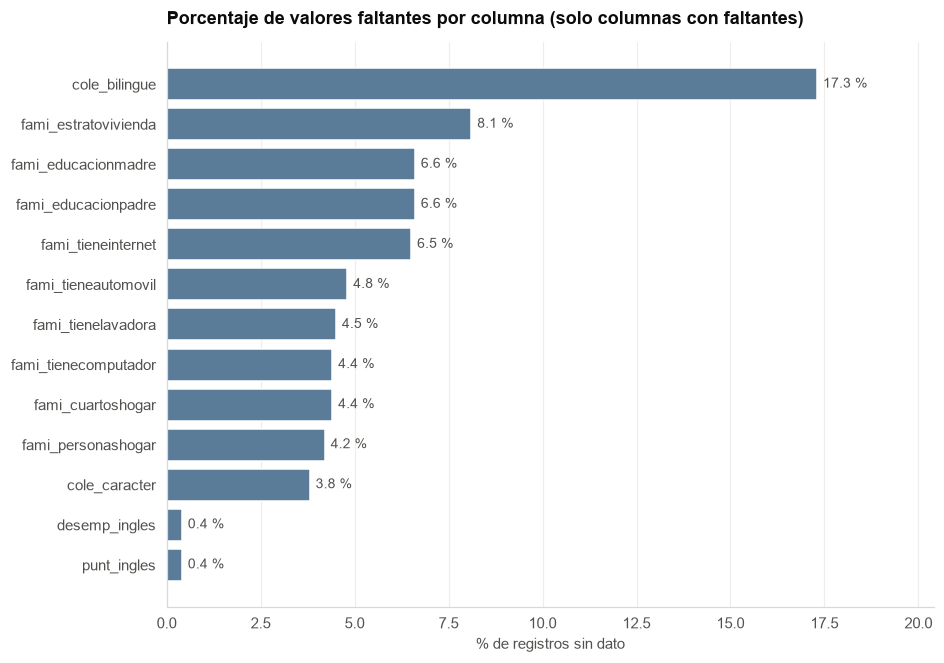

Registros sin ningún dato del cuestionario (fami_* todo nulo): 25 (2.50 %)
Registros con al menos un fami_* faltante                   : 112 (11.20 %)
Registros con cuestionario completo                          : 888 (88.80 %)


,count,mean,std,min,25%,50%,75%,max
sin_cuestionario,25.00,225.20,52.70,117.00,182.00,234.00,260.00,323.00
con_cuestionario,975.00,249.80,50.30,142.00,211.50,245.00,289.00,412.00


In [8]:
faltantes = (df.isna().mean() * 100).round(2)
faltantes = faltantes[faltantes > 0].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 0.42 * len(faltantes) + 1.2))
bars = ax.barh(faltantes.index, faltantes.values, color=C_NEU)
ax.bar_label(bars, labels=[f"{v:.1f} %" for v in faltantes.values], padding=4, fontsize=9, color=GRIS)
ax.set_title("Porcentaje de valores faltantes por columna (solo columnas con faltantes)")
ax.set_xlabel("% de registros sin dato")
ax.set_xlim(0, faltantes.max() * 1.18)
ax.grid(axis="y", visible=False)
save_fig(fig, "missing_values")
plt.show()

fami_cols = [c for c in df.columns if c.startswith("fami_")]
sin_cuestionario = df[fami_cols].isna().all(axis=1)
algun_faltante = df[fami_cols].isna().any(axis=1)
print(f"Registros sin ningún dato del cuestionario (fami_* todo nulo): {sin_cuestionario.sum():,} "
      f"({sin_cuestionario.mean() * 100:.2f} %)")
print(f"Registros con al menos un fami_* faltante                   : {algun_faltante.sum():,} "
      f"({algun_faltante.mean() * 100:.2f} %)")
print(f"Registros con cuestionario completo                          : {(~algun_faltante).sum():,} "
      f"({(~algun_faltante).mean() * 100:.2f} %)")

comparacion = pd.DataFrame({
    "sin_cuestionario": df.loc[sin_cuestionario, "punt_global"].describe(),
    "con_cuestionario": df.loc[~sin_cuestionario, "punt_global"].describe(),
}).round(1)
display(comparacion.T)

Hay faltantes en 13 columnas, con `cole_bilingue` a la cabeza (17,3 %), seguida por los nueve campos del cuestionario del hogar (4,2 % a 8,1 %), `cole_caracter` (3,8 %) y el inglés (0,4 %). Los 25 estudiantes (2,5 %) que no respondieron **ninguna** pregunta del cuestionario y los 112 (11,2 %) que dejaron **al menos una** sin responder suman la mayor parte de los faltantes; 888 estudiantes (88,8 %) tienen el cuestionario completo. La ausencia no es inocua: quienes no tienen ninguna respuesta promedian **225,2 puntos** frente a **249,8** de quienes sí respondieron, 24,6 puntos menos, una diferencia casi idéntica a la de la población (21,5 puntos). Eliminar esas filas sesgaría el modelo hacia los estudiantes de mayor puntaje, y la sección siguiente estudia por qué faltan.

### 4.3 Mecanismo de los faltantes

Antes de decidir si se elimina, se imputa o se conserva un faltante hay que preguntarse **por qué falta**, porque la respuesta determina qué tratamiento es válido. Los tres mecanismos clásicos son:

*   **MCAR** (*missing completely at random*): la probabilidad de que falte un dato no depende de nada; eliminar o imputar con la media no sesga.
*   **MAR** (*missing at random*): depende de otras variables **observadas**; se puede corregir condicionando en ellas (por ejemplo, con imputación basada en modelos).
*   **MNAR** (*missing not at random*): depende del propio valor que falta o de algo no observado; ninguna imputación estándar lo corrige y lo más prudente es conservar el faltante como información.

El diagnóstico se hace con pruebas de asociación sobre dos indicadores de falta: **cuestionario incompleto** (al menos una respuesta del bloque `fami_*` sin dato) y **colegio sin indicador de bilingüismo**. Para cada uno se contrasta el puntaje global con la prueba U de Mann-Whitney (no paramétrica) y se prueba su independencia respecto de variables observadas con χ², agrupando las categorías con menos de 20 observaciones. Si la falta dependiera de las variables observadas, el mecanismo **no sería MCAR**. Como los puntajes y el colegio son variables observadas y el indicador de falta se compara con ellas, la prueba permite descartar MCAR pero no distinguir MAR de MNAR, que requiere conocimiento del proceso de captura de los datos.

In [9]:
def colapsar(s, min_n=20):
    """Agrupa en 'Otras' las categorías con menos de `min_n` observaciones y trata el faltante como categoría."""
    s = s.astype(object).fillna("Sin dato")
    vc = s.value_counts()
    return s.where(~s.isin(vc[vc < min_n].index), "Otras")

def chi2_v(x, y):
    """Prueba χ² de independencia y V de Cramér (con corrección de sesgo) entre dos variables categóricas."""
    tabla = pd.crosstab(x, y)
    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return None
    chi2, p, gl, esperado = stats.chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
    phi2c = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    v_corr = np.sqrt(phi2c / max(1e-12, min(kc - 1, rc - 1)))
    return {"niveles": r, "χ²": chi2, "gl": gl, "p-valor": p, "V de Cramér": v, "V corregido": v_corr,
            "% celdas con esperado < 5": (esperado < 5).mean() * 100}

fami_cols = [c for c in df.columns if c.startswith("fami_")]
indicadores = {"cuestionario incompleto (fami_*)": df[fami_cols].isna().any(axis=1),
               "colegio sin dato de bilingüismo": df["cole_bilingue"].isna()}
observadas = ["cole_naturaleza", "cole_area_ubicacion", "cole_jornada", "cole_caracter", "cole_depto_ubicacion", "estu_genero"]

filas = []
for nombre, falta in indicadores.items():
    a, b = df.loc[falta, "punt_global"].dropna(), df.loc[~falta, "punt_global"].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    filas.append({"indicador": nombre, "variable observada": "punt_global (Mann-Whitney)",
                  "con dato faltante": f"{a.mean():.1f} (n = {len(a)})", "sin dato faltante": f"{b.mean():.1f} (n = {len(b)})",
                  "p-valor": p, "V de Cramér": np.nan})
    for col in observadas:
        res = chi2_v(colapsar(df[col]), falta)
        if res:
            filas.append({"indicador": nombre, "variable observada": f"{col} (χ²)", "con dato faltante": "", "sin dato faltante": "",
                          "p-valor": res["p-valor"], "V de Cramér": res["V corregido"]})
mecanismo = pd.DataFrame(filas)
mecanismo["¿depende de lo observado? (p < 0,05)"] = mecanismo["p-valor"] < 0.05
with pd.option_context("display.max_colwidth", 60, "display.width", 220):
    display(mecanismo.round(4))
for nombre in indicadores:
    sub = mecanismo[mecanismo["indicador"] == nombre]
    print(f"{nombre}: {int(sub['¿depende de lo observado? (p < 0,05)'].sum())} de {len(sub)} pruebas significativas → "
          f"{'no es MCAR' if sub['¿depende de lo observado? (p < 0,05)'].any() else 'compatible con MCAR'}")

,indicador,variable observada,con dato faltante,sin dato faltante,p-valor,V de Cramér,"¿depende de lo observado? (p < 0,05)"
0,cuestionario incompleto (fami_*),punt_global (Mann-Whitney),227.5 (n = 112),251.9 (n = 888),0.00,NaN,True
1,cuestionario incompleto (fami_*),cole_naturaleza (χ²),,,0.16,0.03,False
2,cuestionario incompleto (fami_*),cole_area_ubicacion (χ²),,,0.03,0.06,True
3,cuestionario incompleto (fami_*),cole_jornada (χ²),,,0.00,0.11,True
4,cuestionario incompleto (fami_*),cole_caracter (χ²),,,0.51,0.00,False
5,cuestionario incompleto (fami_*),cole_depto_ubicacion (χ²),,,0.00,0.17,True
6,cuestionario incompleto (fami_*),estu_genero (χ²),,,0.46,0.00,False
7,colegio sin dato de bilingüismo,punt_global (Mann-Whitney),245.2 (n = 173),250.0 (n = 827),0.17,NaN,False
8,colegio sin dato de bilingüismo,cole_naturaleza (χ²),,,0.00,0.20,True
9,colegio sin dato de bilingüismo,cole_area_ubicacion (χ²),,,0.00,0.15,True


cuestionario incompleto (fami_*): 4 de 7 pruebas significativas → no es MCAR
colegio sin dato de bilingüismo: 5 de 7 pruebas significativas → no es MCAR


**Ninguno de los dos faltantes es MCAR.** Para el cuestionario incompleto, el puntaje global es menor entre quienes dejan respuestas vacías (227,5 frente a 251,9; Mann-Whitney con p < 0,01) y la falta depende de la jornada (V de Cramér 0,11) y del departamento (0,17) y, con menor fuerza, del área (0,06, p = 0,03); no depende de la naturaleza del colegio, el carácter ni el género. Como la falta se asocia con variables observadas, el mecanismo es al menos **MAR**; como además se asocia con el propio puntaje, que el estudiante no controla pero que refleja su contexto, no se puede descartar **MNAR** (por ejemplo, que los hogares con menos recursos o con situaciones más difíciles respondan menos).

Para el indicador de bilingüismo la lectura es distinta: la falta **no** se asocia con el puntaje (245,2 frente a 250,0; p = 0,17) pero sí con la naturaleza (V = 0,20), el área (0,15), la jornada (0,09), el departamento (0,14) y sobre todo con el carácter del colegio (0,50), lo que indica un faltante **estructural**: ciertos tipos de colegio no reportan ese campo. Estas conclusiones definen el tratamiento de la fase 2: no eliminar filas, no imputar con la media, conservar el cuestionario incompleto como una categoría (*No respondió*) con un indicador propio, y tratar `cole_bilingue` como *No reportado*, con la salvedad de que apenas 5 estudiantes en toda la muestra son de colegios bilingües y la variable aporta poco.

### 4.4 Conversión de tipos y variables derivadas

Dos columnas necesitan transformación antes del análisis:

*   **`estu_fechanacimiento`** llega como texto `dd/mm/aaaa`. Se convierte a fecha y se deriva la **edad al momento de la prueba** (la aplicación del calendario A de 2022 se realizó el 4 de septiembre de 2022). Las edades fuera del rango plausible para un estudiante de grado once (menos de 13 o más de 80 años) se tratan como faltantes y se cuentan.
*   **Variables ordinales**: `fami_estratovivienda`, `fami_educacionmadre`, `fami_educacionpadre`, `fami_personashogar`, `fami_cuartoshogar` y `desemp_ingles` tienen un orden natural que `category` no conoce. Se fija ese orden explícitamente para que las tablas y gráficas lo respeten y para la codificación ordinal de la sección 9.

In [10]:
FECHA_PRUEBA = pd.Timestamp("2022-09-04")
fecha_nac = pd.to_datetime(df["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
df["edad"] = ((FECHA_PRUEBA - fecha_nac).dt.days / 365.25).round(1)
fuera_rango = (df["edad"] < 13) | (df["edad"] > 80)
print(f"Fechas no interpretables : {fecha_nac.isna().sum():,}")
print(f"Edades fuera de [13, 80] : {fuera_rango.sum():,} → se marcan como faltantes")
df.loc[fuera_rango, "edad"] = np.nan

ORDEN = {
    "fami_estratovivienda": ["Sin Estrato", "Estrato 1", "Estrato 2", "Estrato 3",
                             "Estrato 4", "Estrato 5", "Estrato 6"],
    "fami_educacionmadre": ["Ninguno", "Primaria incompleta", "Primaria completa",
                            "Secundaria (Bachillerato) incompleta", "Secundaria (Bachillerato) completa",
                            "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
                            "Educación profesional incompleta", "Educación profesional completa",
                            "Postgrado", "No sabe", "No Aplica"],
    "fami_personashogar": ["1 a 2", "3 a 4", "5 a 6", "7 a 8", "9 o más"],
    "fami_cuartoshogar": ["Uno", "Dos", "Tres", "Cuatro", "Cinco", "Seis o mas"],
    "desemp_ingles": ["A-", "A1", "A2", "B1", "B+"],
}
ORDEN["fami_educacionpadre"] = ORDEN["fami_educacionmadre"]

for col, orden in ORDEN.items():
    presentes = [o for o in orden if o in df[col].cat.categories]
    faltan = [c for c in df[col].cat.categories if c not in orden]
    if faltan:
        print(f"  {col}: categorías no previstas en el orden → {faltan}")
    df[col] = df[col].cat.set_categories(presentes + faltan, ordered=True)

print("\nEdad al presentar la prueba:")
display(df["edad"].describe().round(1).to_frame().T)

Fechas no interpretables : 0
Edades fuera de [13, 80] : 0 → se marcan como faltantes

Edad al presentar la prueba:


,count,mean,std,min,25%,50%,75%,max
edad,"1,000.00",17.90,3.60,15.10,16.70,17.20,18.10,72.50


Las 1.000 fechas de nacimiento son interpretables y ninguna edad cae fuera del rango plausible de 13 a 80 años. La edad al presentar la prueba tiene **mediana de 17,2 años, media de 17,9 y desviación de 3,6**, con el 50 % central entre 16,7 y 18,1 años (rango intercuartílico de solo 1,4 años) y un máximo de 72,5; la desviación mucho mayor que el rango intercuartílico anticipa una cola de adultos que la sección siguiente cuantifica. Las seis variables ordinales mantienen su orden natural y ninguna trae categorías no previstas.

### 4.5 Valores atípicos (regla IQR y puntaje Z)

Un valor atípico es una observación muy alejada del resto. Se aplican las dos reglas que pide la guía a las siete variables cuantitativas (los cinco puntajes por área, el puntaje global y la edad):

*   **Regla del rango intercuartílico (IQR)**: es atípico lo que cae fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]. No supone ninguna forma de distribución.
*   **Puntaje Z**: es atípico lo que está a más de 3 desviaciones estándar de la media. Supone una distribución aproximadamente normal y es sensible a las propias colas que quiere detectar.

Detectar no es lo mismo que eliminar: la tabla cuantifica cuántos hay y de qué lado, y las decisiones de tratamiento (conservar, transformar o recortar por percentiles) se justifican en la fase 2, una vez se sepa si son errores de medición o casos reales. La figura muestra los diagramas de caja, que son la representación gráfica de la regla IQR.

variable,punt_matematicas,punt_lectura_critica,punt_sociales_ciudadanas,punt_c_naturales,punt_ingles,punt_global,edad
n,"1,000.00","1,000.00","1,000.00","1,000.00",996.00,"1,000.00","1,000.00"
Q1,41.00,45.00,38.00,41.00,39.00,211.00,16.70
Q3,59.00,61.00,56.00,56.00,58.00,288.00,18.10
límite inferior,14.00,21.00,11.00,18.50,10.50,95.50,14.60
límite superior,86.00,85.00,83.00,78.50,86.50,403.50,20.20
atípicos bajos,0.00,0.00,0.00,1.00,1.00,0.00,0.00
atípicos altos,1.00,1.00,0.00,0.00,5.00,1.00,45.00
% atípicos (IQR),0.10,0.10,0.00,0.10,0.60,0.10,4.50
|z| > 3,1.00,1.00,0.00,1.00,6.00,2.00,16.00
% |z| > 3,0.10,0.10,0.00,0.10,0.60,0.20,1.60


Figura guardada: assets\images\data\outliers_boxplots.png


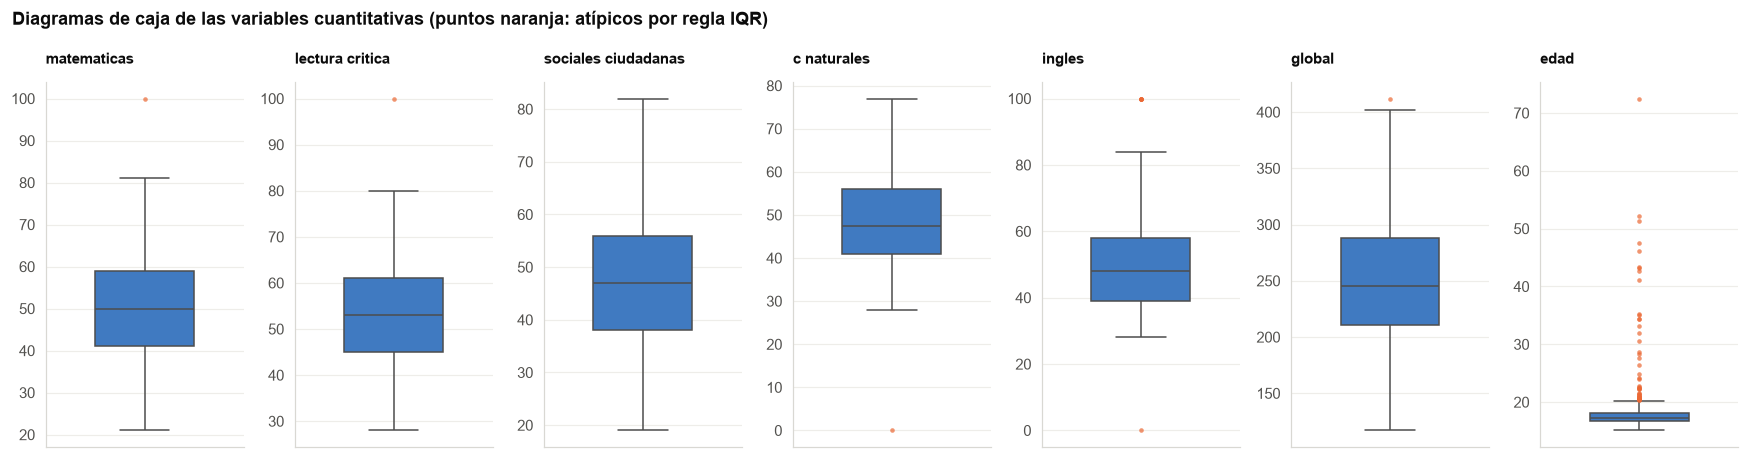

In [11]:
CUANT = SCORE_COLS + ["edad"]
filas = []
for c in CUANT:
    s = df[c].dropna().astype(float)
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    filas.append({"variable": c, "n": len(s), "Q1": q1, "Q3": q3, "límite inferior": lo, "límite superior": hi,
                  "atípicos bajos": int((s < lo).sum()), "atípicos altos": int((s > hi).sum()),
                  "% atípicos (IQR)": ((s < lo) | (s > hi)).mean() * 100,
                  "|z| > 3": int((z.abs() > 3).sum()), "% |z| > 3": (z.abs() > 3).mean() * 100,
                  "mínimo": s.min(), "máximo": s.max(), "percentil 1": s.quantile(0.01), "percentil 99": s.quantile(0.99)})
atipicos = pd.DataFrame(filas).set_index("variable")
display(atipicos.round(2).T)

fig, axes = plt.subplots(1, len(CUANT), figsize=(16, 4.2))
for ax, c in zip(axes, CUANT):
    sns.boxplot(y=df[c].astype(float), ax=ax, color=C_BASE, width=0.5, fliersize=3,
                flierprops={"markerfacecolor": C_ACCENT, "markeredgecolor": "none", "alpha": 0.7})
    ax.set_title(c.replace("punt_", "").replace("_", " "), fontsize=10); ax.set_ylabel("")
fig.suptitle("Diagramas de caja de las variables cuantitativas (puntos naranja: atípicos por regla IQR)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "outliers_boxplots")
plt.show()

Los **puntajes** tienen muy pocos valores atípicos: entre 0 y 6 estudiantes por prueba (0 % a 0,6 %), y el puntaje global solo 1 por la regla IQR (412, por encima del límite de 403,5) y 2 por Z. Son casos reales: puntajes de 100 en matemáticas, lectura e inglés, y un estudiante con 0 en ciencias naturales y en inglés (puntaje global de 117) que parece una prueba parcialmente diligenciada. El **inglés** es la prueba con más atípicos (6) porque su distribución es la más asimétrica.

La **edad** es la excepción: 45 estudiantes (4,5 %) quedan por encima del límite de 20,2 años por la regla IQR y 16 (1,6 %) a más de 3 desviaciones estándar. No son errores, son estudiantes adultos de jornadas nocturnas o sabatinas, hasta de 72 años. Como el rango intercuartílico es de solo 1,4 años, la regla IQR marca como atípico a cualquier estudiante mayor de 20, lo que sobreestima el problema; el puntaje Z subestima la cola porque la propia desviación está inflada por los extremos. El tratamiento razonado para la fase 2 es conservar a los adultos (son información, con un puntaje 50 a 80 puntos menor) pero acotar su influencia con **winsorización en el percentil 99 (35 años)** o una transformación logarítmica de la edad, y mantener un indicador de **extraedad**.

### 4.6 Coherencia e incongruencias

La última verificación de calidad busca **incoherencias**: combinaciones de valores que no deberían ocurrir o que merecen explicación. Cada regla se aplica sobre la muestra y la tabla reporta cuántos registros la incumplen y qué se hará con ellos. No todas son errores: un colegio de calendario B que presenta en un periodo del calendario A es un caso legítimo pero raro, y por eso se documenta en lugar de corregirse.

In [12]:
areas = SCORE_COLS[:-1]
filas = []
def chequeo(nombre, mascara, tratamiento):
    filas.append({"verificación": nombre, "registros": int(mascara.sum()), "%": mascara.mean() * 100, "tratamiento propuesto": tratamiento})

chequeo("Puntaje por área fuera de [0, 100]", ((df[areas] < 0) | (df[areas] > 100)).any(axis=1), "Ninguno: la escala se respeta")
chequeo("Puntaje global fuera de [0, 500]", (df["punt_global"] < 0) | (df["punt_global"] > 500), "Ninguno: la escala se respeta")
calc = ((3 * df["punt_lectura_critica"] + 3 * df["punt_matematicas"] + 3 * df["punt_sociales_ciudadanas"]
         + 3 * df["punt_c_naturales"] + df["punt_ingles"]) / 13 * 5).round()
chequeo("Puntaje global distinto de la fórmula ponderada del ICFES", calc.notna() & (df["punt_global"] != calc), "Ninguno: el global es función de las áreas")
dep, mun = df["cole_cod_depto_ubicacion"].astype(str), df["cole_cod_mcpio_ubicacion"].astype(str)
chequeo("Código de municipio del colegio que no inicia con el código de su departamento", dep.notna() & (mun.str[:2] != dep), "Ninguno: la codificación DIVIPOLA es consistente")
chequeo("Fecha de nacimiento no interpretable", fecha_nac.isna(), "Marcar la edad como faltante")
chequeo("Edad fuera de [13, 80] años", fuera_rango, "Marcar la edad como faltante")
chequeo("Menores de 16 años en jornada nocturna o sabatina", (df["edad"] < 16) & df["cole_jornada"].isin(["NOCHE", "SABATINA"]), "Conservar y revisar: jornada para adultos")
chequeo("Colegio de calendario B u OTRO en un periodo del calendario A", df["cole_calendario"] != "A", "Conservar: caso legítimo pero poco frecuente")
chequeo("Al menos un puntaje por área igual a 0", (df[areas] == 0).any(axis=1), "Conservar y revisar: posible prueba no diligenciada")
chequeo("Estudiante sin puntaje de inglés", df["punt_ingles"].isna(), "Conservar: el puntaje global se reporta igual")
chequeo("Estudiante privado de la libertad", df["estu_privado_libertad"] == "S", "Conservar: variable casi constante, se descarta del modelo")
chequeo("Documento distinto de tarjeta de identidad o cédula de ciudadanía", ~df["estu_tipodocumento"].isin(["TI", "CC"]), "Conservar: redundante con la edad")
coherencia = pd.DataFrame(filas).set_index("verificación")
with pd.option_context("display.max_colwidth", 90, "display.width", 220):
    display(coherencia.round(2))

,registros,%,tratamiento propuesto
verificación,,,
"Puntaje por área fuera de [0, 100]",0,0.00,Ninguno: la escala se respeta
"Puntaje global fuera de [0, 500]",0,0.00,Ninguno: la escala se respeta
Puntaje global distinto de la fórmula ponderada del ICFES,0,0.00,Ninguno: el global es función de las áreas
Código de municipio del colegio que no inicia con el código de su departamento,0,0.00,Ninguno: la codificación DIVIPOLA es consistente
Fecha de nacimiento no interpretable,0,0.00,Marcar la edad como faltante
"Edad fuera de [13, 80] años",0,0.00,Marcar la edad como faltante
Menores de 16 años en jornada nocturna o sabatina,0,0.00,Conservar y revisar: jornada para adultos
Colegio de calendario B u OTRO en un periodo del calendario A,3,0.30,Conservar: caso legítimo pero poco frecuente
Al menos un puntaje por área igual a 0,1,0.10,Conservar y revisar: posible prueba no diligenciada


Los datos son coherentes: **0 incumplimientos** en las reglas de escala (puntajes por área en [0, 100] y global en [0, 500]), en la fórmula del puntaje global (se verifica con detalle en la sección 5.2), en la correspondencia entre el código del municipio y el del departamento, en las fechas de nacimiento y en la edad plausible. Tampoco hay menores de 16 años en jornadas nocturnas o sabatinas ni estudiantes privados de la libertad. Cuatro casos merecen una nota pero no una corrección: **22 estudiantes (2,2 %)** con documento distinto de tarjeta de identidad o cédula (extranjeros o de otras categorías, redundante con la edad), **4** sin puntaje de inglés (el global se reporta igual), **3** de colegios de calendario B u otro en un periodo del calendario A, y **1** con un puntaje por área igual a 0, el mismo estudiante que la sección 4.5 identificó como posible prueba parcial. Se conservan todos.

## 5. La variable objetivo: `punt_global`

### 5.1 Distribución

El puntaje global se reporta en una escala de 0 a 500. Se examina su distribución con las estadísticas descriptivas, un histograma y un diagrama de caja, para conocer su centro, su dispersión, su simetría y la presencia de valores extremos, que condicionan la elección de la métrica de error y la necesidad de transformar la variable.

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
punt_global,"1,000.00",249.20,50.50,117.00,211.00,245.00,288.00,412.00,0.22,-0.58


Figura guardada: assets\images\data\target_distribution.png


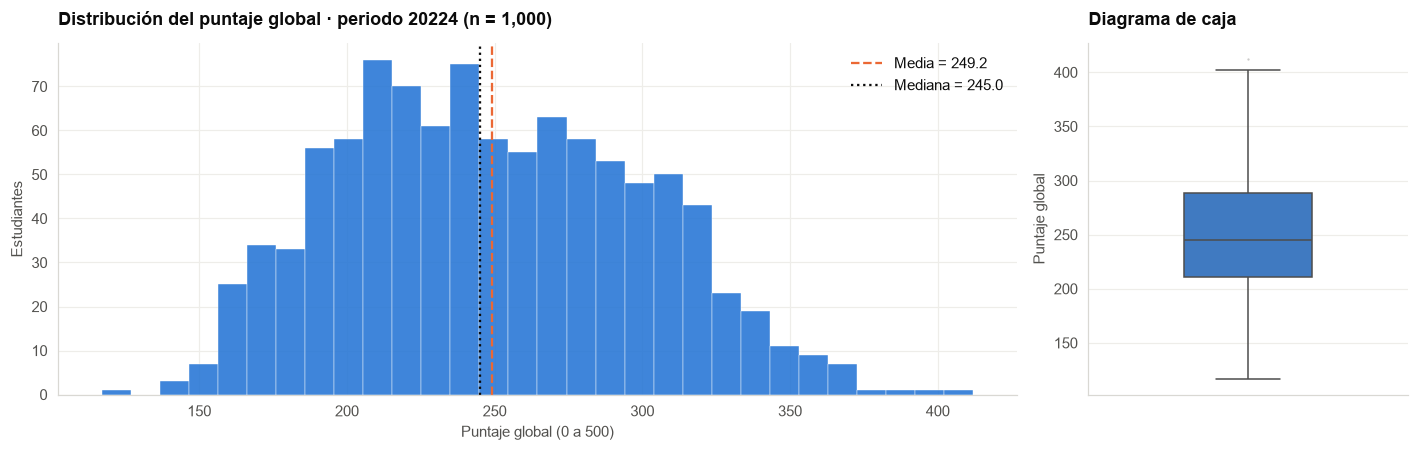

Percentiles 1, 5, 25, 50, 75, 95, 99: [156. 172. 211. 245. 288. 333. 364.]


In [13]:
y = df["punt_global"]
desc = y.describe().round(1)
desc["asimetría"] = round(y.skew(), 3)
desc["curtosis"] = round(y.kurt(), 3)
display(desc.to_frame("punt_global").T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 1]})
axes[0].hist(y.dropna(), bins=30, color=C_BASE, alpha=0.9, edgecolor="white", linewidth=0.3)
axes[0].axvline(y.mean(), color=C_ACCENT, linestyle="--", linewidth=1.5, label=f"Media = {y.mean():.1f}")
axes[0].axvline(y.median(), color=TINTA, linestyle=":", linewidth=1.5, label=f"Mediana = {y.median():.1f}")
axes[0].set_title(f"Distribución del puntaje global · periodo {PERIODO} (n = {y.notna().sum():,})")
axes[0].set_xlabel("Puntaje global (0 a 500)")
axes[0].set_ylabel("Estudiantes")
axes[0].legend(frameon=False)

sns.boxplot(y=y, ax=axes[1], color=C_BASE, width=0.4, fliersize=1.5,
            flierprops={"markerfacecolor": GRIS, "markeredgecolor": "none", "alpha": 0.3})
axes[1].set_title("Diagrama de caja")
axes[1].set_ylabel("Puntaje global")
fig.tight_layout()
save_fig(fig, "target_distribution")
plt.show()

p = np.percentile(y.dropna(), [1, 5, 25, 50, 75, 95, 99])
print("Percentiles 1, 5, 25, 50, 75, 95, 99:", np.round(p, 1))

El puntaje global tiene **media de 249,2, mediana de 245 y desviación de 50,5 puntos**, con un rango de 117 a 412; la mitad central de los estudiantes queda entre 211 y 288, el 1 % inferior por debajo de 156 y el 1 % superior por encima de 364. La asimetría de 0,22 y la curtosis de −0,58 describen una distribución **casi simétrica, con una leve cola derecha y colas más ligeras que la normal**, igual a la de la población (media 250,1, desviación 51,8, asimetría 0,28), lo que confirma que la muestra reproduce la variable objetivo. Para el modelado esto es favorable: no hace falta transformar la variable y las métricas de error se leen directamente en puntos de la escala.

### 5.2 Relación con los puntajes por área (verificación de la fuga de información)

Según la guía de orientación del ICFES, el puntaje global es un **promedio ponderado** de las cinco pruebas: lectura crítica, matemáticas, sociales y ciudadanas y ciencias naturales pesan 3 cada una e inglés pesa 1, y el resultado se escala a 500 puntos:

$$
\text{punt\_global} = \text{round}\left( \frac{3\,LC + 3\,MAT + 3\,SOC + 3\,CN + 1\,ING}{13} \times 5 \right)
$$

Se verifica esa fórmula sobre los datos y se calcula la correlación de cada área con el puntaje global. Si la fórmula se cumple, los puntajes por área **no son variables explicativas** sino componentes de la respuesta, y deben excluirse del modelo.

In [14]:
calc = ((3 * df["punt_lectura_critica"] + 3 * df["punt_matematicas"] + 3 * df["punt_sociales_ciudadanas"]
         + 3 * df["punt_c_naturales"] + 1 * df["punt_ingles"]) / 13 * 5)
diff = (df["punt_global"] - calc.round()).abs()
completos = calc.notna()
print(f"Registros con las cinco pruebas    : {completos.sum():,} de {len(df):,}")
print(f"Coinciden exactamente con la fórmula: {(diff[completos] == 0).mean() * 100:.2f} %")
print(f"Diferencia absoluta máxima          : {diff[completos].max():.0f} puntos")
print(f"Diferencia absoluta ≤ 1 punto       : {(diff[completos] <= 1).mean() * 100:.2f} %")

corr_areas = df[SCORE_COLS].corr(method="pearson")["punt_global"].drop("punt_global").sort_values(ascending=False)
display(corr_areas.round(3).to_frame("correlación de Pearson con punt_global").T)

Registros con las cinco pruebas    : 996 de 1,000
Coinciden exactamente con la fórmula: 100.00 %
Diferencia absoluta máxima          : 0 puntos
Diferencia absoluta ≤ 1 punto       : 100.00 %


,punt_c_naturales,punt_sociales_ciudadanas,punt_lectura_critica,punt_matematicas,punt_ingles
correlación de Pearson con punt_global,0.92,0.92,0.91,0.91,0.78


La fórmula se cumple en el **100 % de los 996 estudiantes** que tienen las cinco pruebas (los 4 sin inglés no pueden verificarse), con una diferencia máxima de 0 puntos: el puntaje global es exactamente el promedio ponderado de las áreas redondeado. Cada área correlaciona entre 0,91 y 0,92 con el global, e inglés 0,78 (pesa 1 de 13 en lugar de 3). Esto confirma la restricción del planteamiento: cualquier modelo de regresión o de clasificación que incluya los puntajes por área o el nivel de inglés obtendría un error casi nulo sin haber aprendido nada sobre el contexto del estudiante, porque estaría reconstruyendo la respuesta a partir de sus componentes. **Las cinco áreas y `desemp_ingles` quedan excluidas como variables explicativas**; en el problema de clustering sí se usan, porque allí no hay una variable que predecir.

### 5.3 Análisis univariado de las variables cuantitativas

El análisis univariado describe cada variable por separado. Para las siete cuantitativas se calculan medidas de **tendencia central** (media, mediana, moda), de **dispersión** (desviación estándar, coeficiente de variación, rango intercuartílico, mínimo y máximo) y de **forma** (asimetría y curtosis en exceso, donde 0 corresponde a una normal), más la prueba de normalidad de D'Agostino-Pearson, cuya hipótesis nula es que la variable proviene de una distribución normal. La edad es la variable derivada de la fecha de nacimiento (sección 4.4).

,punt_matematicas,punt_lectura_critica,punt_sociales_ciudadanas,punt_c_naturales,punt_ingles,punt_global,edad
n,"1,000.00","1,000.00","1,000.00","1,000.00",996.00,"1,000.00","1,000.00"
media,50.28,52.95,47.38,48.81,49.57,249.16,17.91
mediana,50.00,53.00,47.00,47.50,48.00,245.00,17.20
moda,49.00,58.00,38.00,44.00,39.00,213.00,17.00
desviación estándar,11.91,10.48,11.71,10.06,13.05,50.51,3.60
coef. de variación (%),23.69,19.79,24.72,20.61,26.33,20.27,20.13
mínimo,21.00,28.00,19.00,0.00,0.00,117.00,15.10
Q1,41.00,45.00,38.00,41.00,39.00,211.00,16.70
Q3,59.00,61.00,56.00,56.00,58.00,288.00,18.10
máximo,100.00,100.00,82.00,77.00,100.00,412.00,72.50


Figura guardada: assets\images\data\univariate_quantitative.png


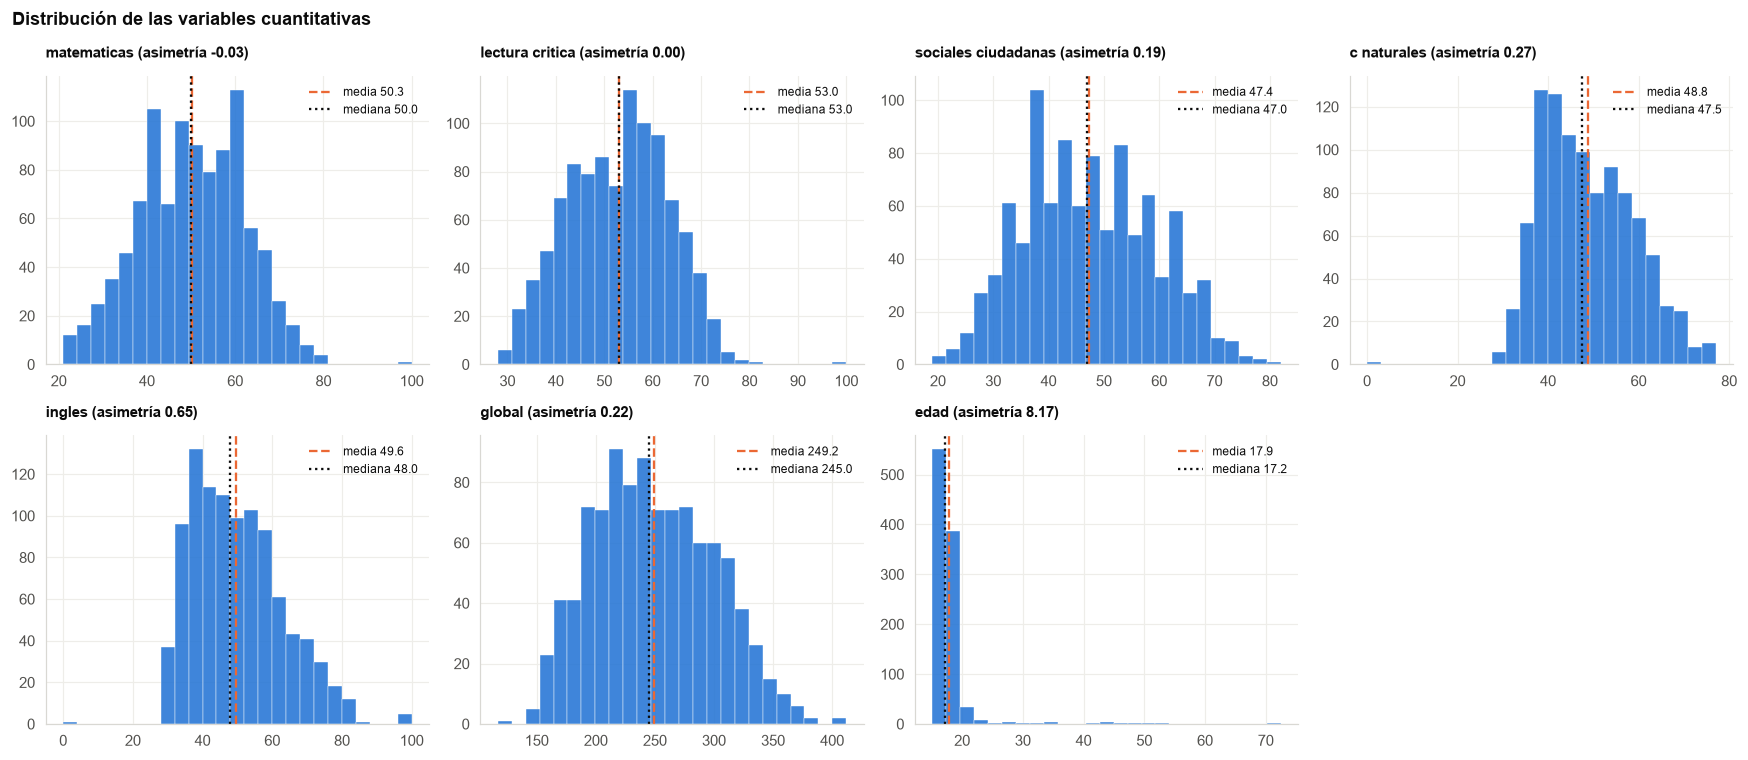

In [15]:
def resumen_cuant(s):
    s = s.dropna().astype(float)
    return {"n": len(s), "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0], "desviación estándar": s.std(),
            "coef. de variación (%)": s.std() / s.mean() * 100, "mínimo": s.min(), "Q1": s.quantile(0.25),
            "Q3": s.quantile(0.75), "máximo": s.max(), "rango intercuartílico": s.quantile(0.75) - s.quantile(0.25),
            "asimetría": s.skew(), "curtosis (exceso)": s.kurt(), "p-valor normalidad": stats.normaltest(s)[1]}

univariado = pd.DataFrame({c: resumen_cuant(df[c]) for c in CUANT})
display(univariado.round(3))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), CUANT):
    s = df[c].dropna().astype(float)
    ax.hist(s, bins=25, color=C_BASE, alpha=0.9, edgecolor="white", linewidth=0.3)
    ax.axvline(s.mean(), color=C_ACCENT, linestyle="--", linewidth=1.5, label=f"media {s.mean():.1f}")
    ax.axvline(s.median(), color=TINTA, linestyle=":", linewidth=1.5, label=f"mediana {s.median():.1f}")
    ax.set_title(f"{c.replace('punt_', '').replace('_', ' ')} (asimetría {s.skew():.2f})", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
axes.ravel()[-1].axis("off")
fig.suptitle("Distribución de las variables cuantitativas", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "univariate_quantitative")
plt.show()

Las seis variables de puntaje tienen **medias entre 47,4 (sociales) y 53,0 (lectura crítica)** en la escala de 0 a 100, desviaciones de 10,1 a 13,1 y coeficientes de variación de 20 % a 26 %: dispersión moderada y comparable entre pruebas. Cuatro de ellas son casi simétricas (asimetría entre −0,03 y 0,27); **inglés** es la más asimétrica (0,65) y la única con colas más pesadas que la normal (curtosis en exceso de 0,45), porque tiene un grupo de estudiantes con niveles bajos de inglés y un extremo de 100 puntos. El puntaje global, promedio de las áreas, es casi simétrico (0,22) con colas ligeras (−0,58). La prueba de normalidad rechaza la hipótesis en las siete variables (p < 0,05), lo esperable con n = 1.000, que detecta desviaciones diminutas; en la práctica solo la edad y, en menor medida, inglés se alejan de forma relevante.

La **edad** es la variable con distribución más extrema: media de 17,9 y mediana de 17,2 años, pero **asimetría de 8,2 y curtosis en exceso de 85,9**, producto de una cola de adultos de hasta 72 años; el uso de la edad en modelos lineales y en clustering requiere por eso una transformación o un escalado robusto. Los histogramas muestran la moda del puntaje global en 213 y una forma suave, mientras que los de las áreas tienen la irregularidad propia de puntajes enteros agrupados en 25 intervalos.

### 5.4 Tablas de frecuencias de las variables cualitativas

Para las variables cualitativas, el análisis univariado es la **tabla de frecuencias**: cuántos estudiantes hay en cada categoría y qué porcentaje representan, con el faltante como categoría propia (*Sin dato*) para ver cuánta información falta. Se incluyen todas las variables con 15 niveles o menos; las de cardinalidad mayor (departamentos, municipios, códigos y nombres) se describen en el diccionario y se analizan agrupadas más adelante. La tabla completa se guarda en `data/processed/frecuencias_cualitativas.csv`.

In [16]:
NIVELES_MAX = 15
cualitativas = [c for c in df.columns
                if str(df[c].dtype) in ("category", "string", "object") and c not in ID_COLS and df[c].nunique() <= NIVELES_MAX]
filas = []
for c in cualitativas:
    vc = df[c].astype(object).fillna("Sin dato").value_counts()
    for categoria, n in vc.items():
        filas.append({"variable": c, "categoría": categoria, "n": int(n), "%": n / len(df) * 100})
frecuencias = pd.DataFrame(filas)
frecuencias.to_csv(PROCESSED_DIR / "frecuencias_cualitativas.csv", index=False, encoding="utf-8")
print(f"Variables cualitativas con ≤ {NIVELES_MAX} niveles: {len(cualitativas)} · filas de la tabla: {len(frecuencias)}")
with pd.option_context("display.max_rows", 400, "display.width", 140):
    display(frecuencias.round(1).set_index(["variable", "categoría"]))

Variables cualitativas con ≤ 15 niveles: 26 · filas de la tabla: 111


n      %
variable                 categoría                                        
periodo                  20224                                 1000 100.00
estu_tipodocumento       TI                                     846  84.60
                         CC                                     132  13.20
                         NES                                      7   0.70
                         CR                                       5   0.50
                         CE                                       4   0.40
                         PEP                                      3   0.30
                         PPT                                      2   0.20
                         RC                                       1   0.10
cole_area_ubicacion      URBANO                                 829  82.90
                         RURAL                                  171  17.10
cole_bilingue            N                                      822  82.20
                         Sin dato                               173  17.30
                         S                                        5   0.50
cole_calendario          A                                      997  99.70
                         OTRO                                     2   0.20
                         B                                        1   0.10
cole_caracter            ACADÉMICO                              492  49.20
                         TÉCNICO/ACADÉMICO                      333  33.30
                         TÉCNICO                                121  12.10
                         Sin dato                                38   3.80
                         NO APLICA                               16   1.60
cole_genero              MIXTO                                  962  96.20
                         FEMENINO                                26   2.60
                         MASCULINO                               12   1.20
cole_jornada             MAÑANA                                 374  37.40
                         UNICA                                  274  27.40
                         COMPLETA                               145  14.50
                         TARDE                                   97   9.70
                         SABATINA                                62   6.20
                         NOCHE                                   48   4.80
cole_naturaleza          OFICIAL                                774  77.40
                         NO OFICIAL                             226  22.60
cole_sede_principal      S                                      932  93.20
                         N                                       68   6.80
estu_estadoinvestigacion PUBLICAR                              1000 100.00
estu_estudiante          ESTUDIANTE                            1000 100.00
estu_genero              F                                      573  57.30
                         M                                      427  42.70
estu_nacionalidad        COLOMBIA                               986  98.60
                         VENEZUELA                               13   1.30
                         CHINA                                    1   0.10
estu_pais_reside         COLOMBIA                               986  98.60
                         VENEZUELA                               13   1.30
                         CHINA                                    1   0.10
estu_privado_libertad    N                                     1000 100.00
fami_cuartoshogar        Tres                                   402  40.20
                         Dos                                    369  36.90
                         Cuatro                                  99   9.90
                         Sin dato                                44   4.40
                         Uno                                     44   4.40
                         Cinco                                   29   2.90
                

Hay **26 variables cualitativas con 15 niveles o menos** y la tabla suma 111 filas. Resume la composición de la muestra: el **77,4 % de los estudiantes estudia en colegios oficiales** (774) y el 22,6 % en privados (226); el **82,9 % en zona urbana**; el 57,3 % son mujeres; el 84,6 % usa tarjeta de identidad (TI) y el 13,2 % cédula de ciudadanía. Por jornada, **mañana 37,4 %, única 27,4 %, completa 14,5 %, tarde 9,7 %, sabatina 6,2 % y noche 4,8 %**: el 11 % de los estudiantes cursó la media en jornadas pensadas para adultos. Por estrato, **el 60,5 % está en los estratos 1 y 2** (25,8 % y 34,7 %) y solo el 5,5 % en los estratos 5 y 6 o sin estrato; el 8,1 % no respondió el estrato.

La tabla también revela variables con muy poca variación: `cole_calendario` (99,7 % calendario A), `cole_bilingue` (solo 5 estudiantes de colegios bilingües, 0,5 %) y las cuatro constantes, que no aportarán información a un modelo. Otras como `estu_nacionalidad` y `estu_pais_reside` tienen tres niveles, casi todo Colombia.

Para las variables cualitativas de **cardinalidad alta** (departamentos, municipios, códigos y nombres) una tabla con todas las categorías no es legible, así que se reportan las **cinco más frecuentes** de cada una, el porcentaje acumulado que cubren y cuántas categorías restantes quedan agrupadas. La columna de cobertura sirve de diagnóstico: si cinco categorías cubren una parte grande de la muestra, la variable está concentrada; si cubren casi nada, la variable es prácticamente un identificador. La tabla completa se guarda en `data/processed/frecuencias_alta_cardinalidad.csv`.

In [17]:
alta_cardinalidad = [c for c in df.columns
                     if str(df[c].dtype) in ("category", "string", "object") and c not in ID_COLS and df[c].nunique() > NIVELES_MAX]
filas = []
for c in alta_cardinalidad:
    vc = df[c].astype(object).fillna("Sin dato").value_counts()
    acumulado = 0.0
    for categoria, n in vc.head(5).items():
        acumulado += n / len(df) * 100
        filas.append({"variable": c, "categoría": str(categoria)[:45], "n": int(n), "%": n / len(df) * 100, "% acumulado": acumulado})
    resto = vc.iloc[5:]
    filas.append({"variable": c, "categoría": f"otras {len(resto)} categorías", "n": int(resto.sum()), "%": resto.sum() / len(df) * 100, "% acumulado": 100.0})
frec_alta = pd.DataFrame(filas)
frec_alta.to_csv(PROCESSED_DIR / "frecuencias_alta_cardinalidad.csv", index=False, encoding="utf-8")
cobertura = (frec_alta[~frec_alta["categoría"].str.startswith("otras")].groupby("variable")["%"].sum()
             .sort_values(ascending=False).round(1).to_frame("% que cubren las 5 categorías más frecuentes"))
print(f"Variables cualitativas con más de {NIVELES_MAX} niveles: {len(alta_cardinalidad)}")
display(cobertura.T)
with pd.option_context("display.max_rows", 400, "display.width", 140):
    display(frec_alta.round(1).set_index(["variable", "categoría"]))

Variables cualitativas con más de 15 niveles: 17


variable,cole_cod_depto_ubicacion,cole_depto_ubicacion,estu_depto_reside,estu_cod_reside_depto,estu_cod_depto_presentacion,estu_depto_presentacion,estu_cod_mcpio_presentacion,estu_mcpio_presentacion,cole_cod_mcpio_ubicacion,cole_mcpio_ubicacion,estu_cod_reside_mcpio,estu_mcpio_reside,cole_nombre_sede,cole_nombre_establecimiento,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_codigo_icfes
% que cubren las 5 categorías más frecuentes,47.80,47.80,47.70,47.70,46.80,46.80,26.60,26.60,26.40,26.40,26.10,26.10,2.10,2.00,1.80,1.80,1.60


n     %  % acumulado
variable                      categoría                                                            
cole_cod_dane_establecimiento 105615000236                                     4  0.40         0.40
                              173001001088                                     4  0.40         0.80
                              308758800002                                     4  0.40         1.20
                              111001024732                                     3  0.30         1.50
                              108758000066                                     3  0.30         1.80
                              otras 899 categorías                           982 98.20       100.00
cole_cod_dane_sede            105615000236                                     4  0.40         0.40
                              173001001088                                     4  0.40         0.80
                              308758800002                                     4  0.40         1.20
                              111001024732                                     3  0.30         1.50
                              108758000066                                     3  0.30         1.80
                              otras 905 categorías                           982 98.20       100.00
cole_cod_depto_ubicacion      05                                             139 13.90        13.90
                              11                                             138 13.80        27.70
                              76                                              76  7.60        35.30
                              25                                              73  7.30        42.60
                              08                                              52  5.20        47.80
                              otras 27 categorías                            522 52.20       100.00
cole_cod_mcpio_ubicacion      11001                                          138 13.80        13.80
                              05001                                           48  4.80        18.60
                              76001                                           32  3.20        21.80
                              13001                                           24  2.40        24.20
                              08758                                           22  2.20        26.40
                              otras 336 categorías                           736 73.60       100.00
cole_codigo_icfes             706101                                           4  0.40         0.40
                              023366                                           3  0.30         0.70
                              717785                                           3  0.30         1.00
                              120014                                           3  0.30         1.30
                              733873                                           3  0.30         1.60
                              otras 922 categorías                           984 98.40       100.00
cole_depto_ubicacion          ANTIOQUIA                                      139 13.90        13.90
                              BOGOTÁ                                         138 13.80        27.70
                              VALLE                                           76  7.60        35.30
                              CUNDINAMARCA                                    73  7.30        42.60
                              ATLANTICO                                       52  5.20        47.80
                              otras 27 categorías                            522 52.20       100.00
cole_mcpio_ubicacion          BOGOTÁ D.C.                                    138 13.80        13.80
                              MEDELLÍN                                        48  4.80        18.60
                              CALI                                            3

Las 17 variables de cardinalidad alta se dividen en dos grupos muy distintos. Las **geográficas por departamento** están concentradas: las cinco categorías más frecuentes (Antioquia 13,9 %, Bogotá 13,8 %, Valle 7,6 %, Cundinamarca 7,3 % y Atlántico 5,2 %) cubren el **47,8 %** de la muestra, y las de municipio el 26 % (Bogotá 13,8 %, Medellín 4,8 %, Cali 3,2 %). En cambio, los **códigos y nombres de colegio** no se concentran en absoluto: sus cinco valores más frecuentes cubren entre el 1,6 % y el 2,1 % de la muestra, porque casi cada estudiante proviene de un colegio distinto (más de 880 colegios para 1.000 estudiantes). Eso confirma, con cifras, que esas seis columnas son identificadores y no variables explicativas, y que la geografía solo es utilizable a nivel de departamento agrupado.

## 6. Variables del estudiante

Se analiza la relación del puntaje global con el **género**, la **edad** y el **tipo de documento** del estudiante. Para cada variable se reporta el tamaño del grupo, la media, la mediana y la desviación del puntaje, y se grafica con diagramas de caja sin valores atípicos (para que la comparación entre grupos no quede dominada por los extremos). La edad se agrupa en tramos porque la relación con el puntaje no tiene por qué ser lineal: los estudiantes mucho mayores que la edad típica de grado once suelen provenir de jornadas nocturnas o de validación.

Figura guardada: assets\images\data\student_variables.png


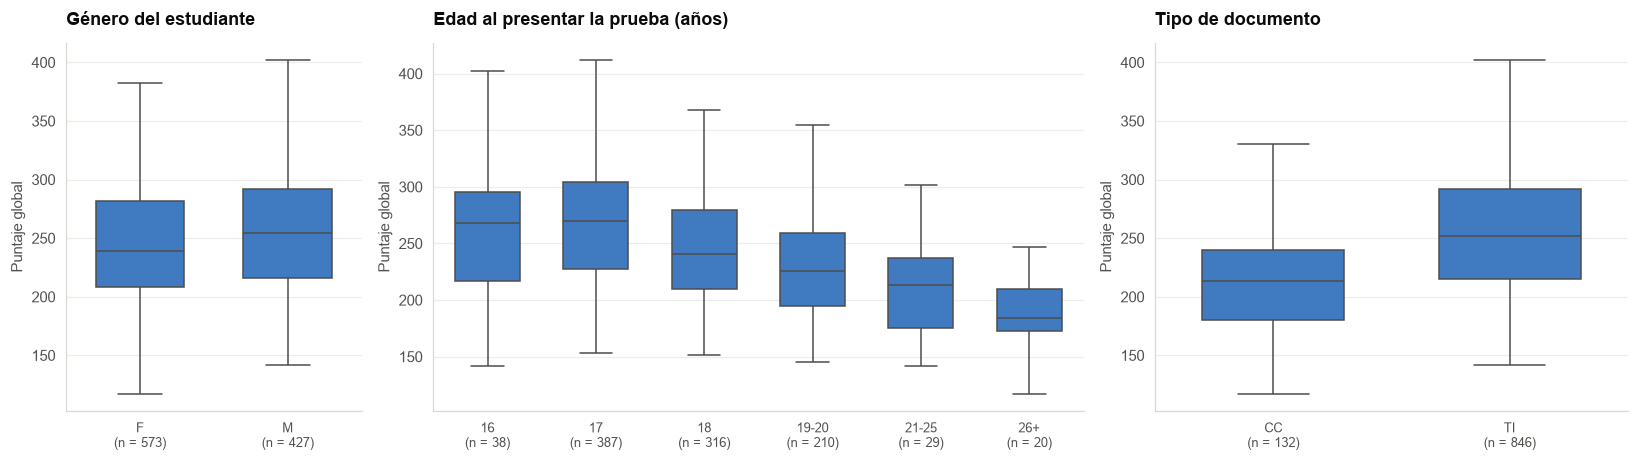

Género:


estu_genero,F,M
n,573.00,427.00
media,245.20,254.50
mediana,239.00,254.00
desv,50.60,49.90


Edad:


edad_grupo,16,17,18,19-20,21-25,26+
n,38.00,387.00,316.00,210.00,29.00,20.00
media,266.60,266.90,244.50,230.90,213.20,189.80
mediana,268.00,270.00,241.00,225.50,213.00,184.50
desv,56.10,49.10,46.70,45.60,40.10,31.80


Tipo de documento (grupos con n ≥ 15):


estu_tipodocumento,CC,TI
n,132.00,846.00
media,217.00,254.40
mediana,213.00,252.00
desv,43.70,49.60


In [18]:
def resumen_por(col, orden=None, min_n=0):
    """Tamaño, media, mediana y desviación del puntaje global por categoría de `col`."""
    tabla = (df.groupby(col, observed=True)["punt_global"]
               .agg(n="size", media="mean", mediana="median", desv="std").round(1))
    if orden is not None:
        tabla = tabla.reindex([o for o in orden if o in tabla.index])
    return tabla[tabla["n"] >= min_n]

def caja_por(ax, col, orden=None, titulo=None, color=C_BASE, rot=0, min_n=0):
    """Diagrama de caja del puntaje global por categoría, con el tamaño de cada grupo en el eje."""
    tabla = resumen_por(col, orden, min_n)
    sns.boxplot(data=df[df[col].isin(tabla.index)], x=col, y="punt_global", order=tabla.index,
                ax=ax, color=color, width=0.6, showfliers=False)
    ax.set_xticklabels([f"{c}\n(n = {n:,})" for c, n in zip(tabla.index, tabla["n"])], rotation=rot,
                       ha="right" if rot else "center", fontsize=8.5)
    ax.set_title(titulo or col)
    ax.set_xlabel("")
    ax.set_ylabel("Puntaje global")
    return tabla

df["edad_grupo"] = pd.cut(df["edad"], bins=[12, 15, 16, 17, 18, 20, 25, 80],
                          labels=["13-15", "16", "17", "18", "19-20", "21-25", "26+"], right=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 2.2, 1.6]})
t_genero = caja_por(axes[0], "estu_genero", ["F", "M"], "Género del estudiante")
t_edad = caja_por(axes[1], "edad_grupo", None, "Edad al presentar la prueba (años)")
t_doc = caja_por(axes[2], "estu_tipodocumento", None, "Tipo de documento", min_n=15)
fig.tight_layout()
save_fig(fig, "student_variables")
plt.show()

print("Género:"); display(t_genero.T)
print("Edad:"); display(t_edad.T)
print("Tipo de documento (grupos con n ≥ 15):"); display(t_doc.T)

Tres patrones del estudiante coinciden con los de la población. **Género**: los hombres promedian 254,5 puntos y las mujeres 245,2, una brecha de 9,3 puntos (7,3 en la población, dentro del error de muestreo). **Edad**: es una de las variables más informativas y su efecto es monótono: **266,6 puntos a los 16 años, 266,9 a los 17, 244,5 a los 18, 230,9 entre 19 y 20, 213,2 entre 21 y 25 y 189,8 de 26 en adelante**, una caída de 77 puntos que marca trayectorias de extraedad y educación de adultos. **Tipo de documento**: la cédula de ciudadanía (adultos) promedia 217,0 frente a 254,4 de la tarjeta de identidad, una diferencia de 37 puntos que redunda con la edad; los demás tipos tienen menos de 15 estudiantes y se omiten del gráfico.

## 7. Variables del hogar

El bloque `fami_*` describe el entorno socioeconómico del estudiante. Se analizan en dos paneles:

*   **Variables ordinales**: estrato de la vivienda y máximo nivel educativo de la madre y del padre. Si la hipótesis H1 es correcta, la mediana del puntaje debería crecer de manera monótona con cada nivel.
*   **Variables binarias y de composición del hogar**: tenencia de internet, computador, automóvil y lavadora, y número de personas y cuartos del hogar. Para estas se compara la media del puntaje entre quienes tienen y no tienen cada bien, con la diferencia en puntos.

Figura guardada: assets\images\data\family_ordinal.png


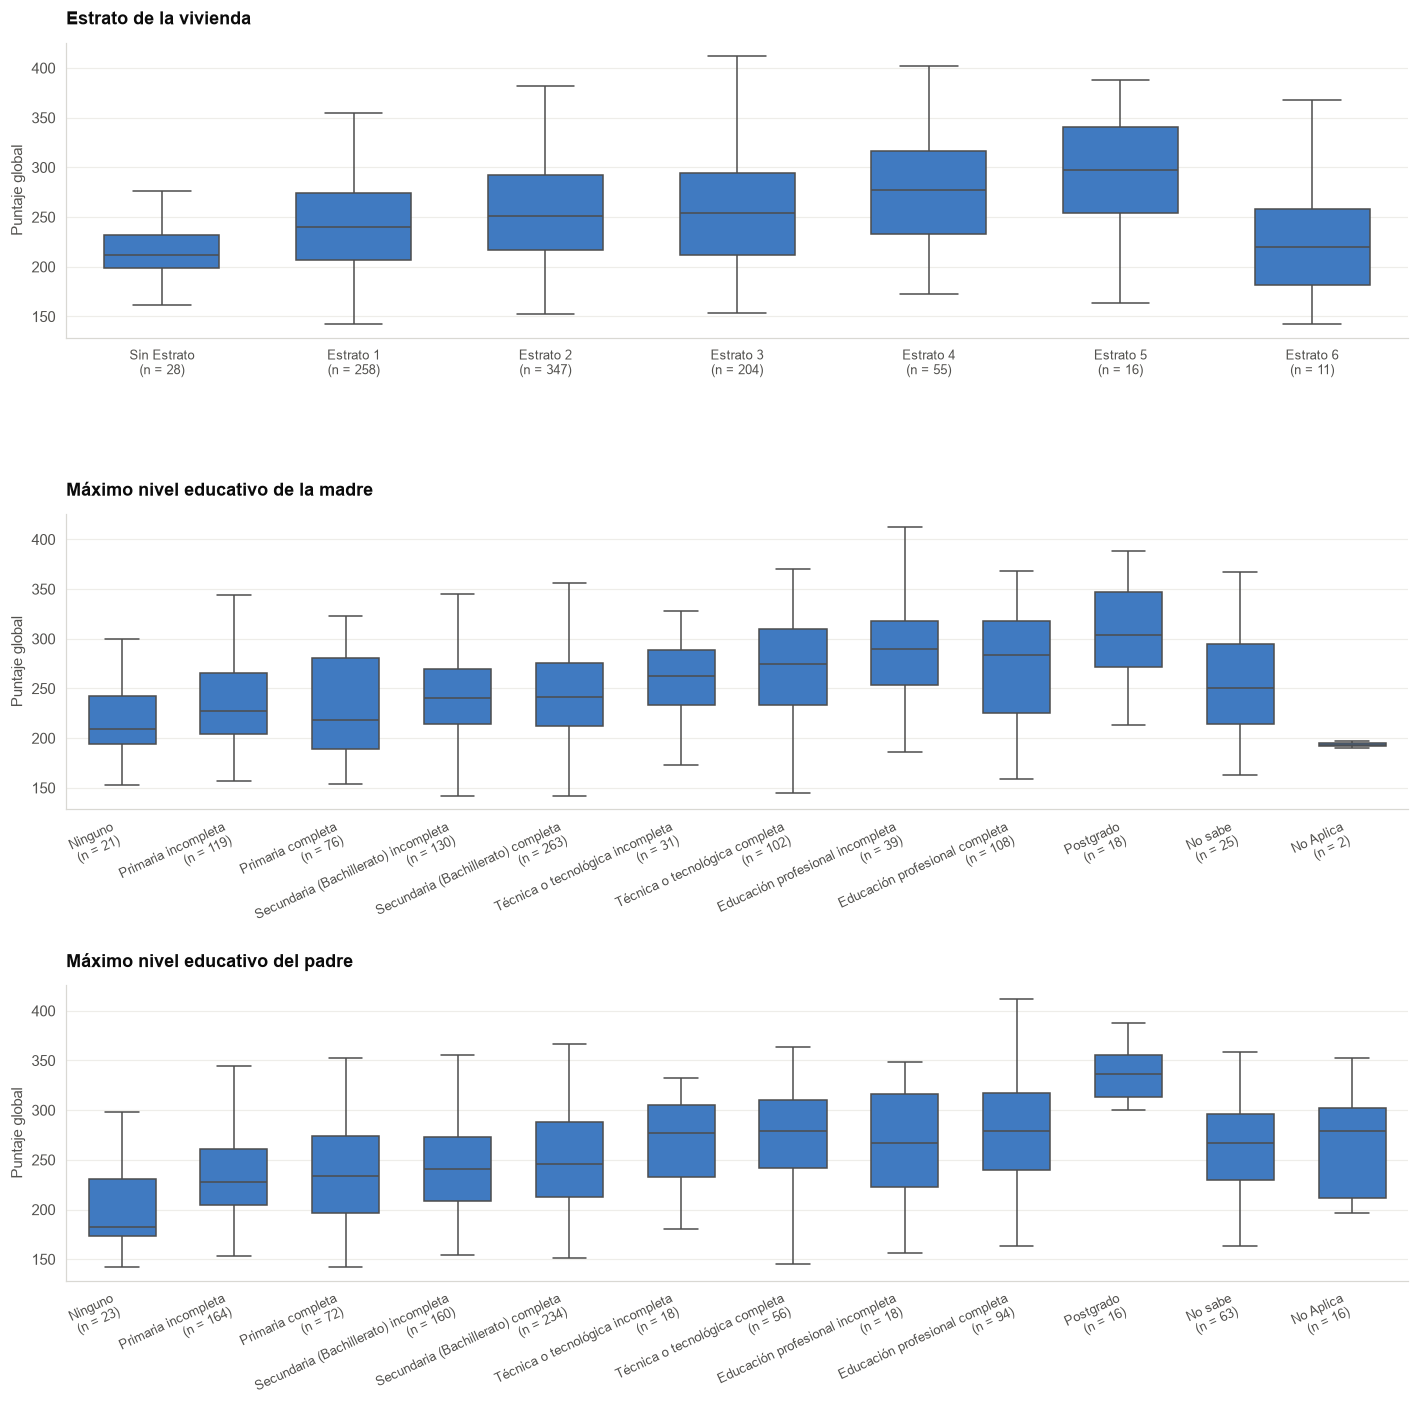

Estrato:


fami_estratovivienda,Sin Estrato,Estrato 1,Estrato 2,Estrato 3,Estrato 4,Estrato 5,Estrato 6
n,28.00,258.00,347.00,204.00,55.00,16.00,11.00
media,222.20,241.60,253.80,254.20,276.50,289.80,230.70
mediana,211.50,240.50,251.00,254.50,277.00,297.00,220.00
desv,44.30,44.60,47.30,53.70,56.90,64.30,75.90


Educación de la madre:


fami_educacionmadre,Ninguno,Primaria incompleta,Primaria completa,Secundaria (Bachillerato) incompleta,Secundaria (Bachillerato) completa,Técnica o tecnológica incompleta,Técnica o tecnológica completa,Educación profesional incompleta,Educación profesional completa,Postgrado,No sabe,No Aplica
n,21.00,119.00,76.00,130.00,263.00,31.00,102.00,39.00,108.00,18.00,25.00,2.00
media,216.60,231.90,230.50,241.00,244.90,259.10,271.40,286.00,275.30,307.00,250.90,193.50
mediana,209.00,227.00,218.00,240.00,241.00,263.00,275.00,290.00,284.00,303.50,250.00,193.50
desv,43.50,43.80,50.70,41.00,45.80,40.50,48.00,49.80,55.20,48.60,54.40,4.90


Educación del padre:


fami_educacionpadre,Ninguno,Primaria incompleta,Primaria completa,Secundaria (Bachillerato) incompleta,Secundaria (Bachillerato) completa,Técnica o tecnológica incompleta,Técnica o tecnológica completa,Educación profesional incompleta,Educación profesional completa,Postgrado,No sabe,No Aplica
n,23.00,164.00,72.00,160.00,234.00,18.00,56.00,18.00,94.00,16.00,63.00,16.00
media,205.70,234.80,235.50,242.70,250.00,268.20,274.10,267.10,275.30,329.20,259.10,268.90
mediana,182.00,228.00,233.50,240.50,246.00,277.50,279.00,267.00,279.50,336.00,267.00,279.50
desv,46.30,41.10,44.40,46.30,49.30,45.90,47.30,55.30,54.60,44.80,46.70,49.90


In [19]:
fig, axes = plt.subplots(3, 1, figsize=(13, 13))
t_estrato = caja_por(axes[0], "fami_estratovivienda", ORDEN["fami_estratovivienda"], "Estrato de la vivienda")
t_madre = caja_por(axes[1], "fami_educacionmadre", ORDEN["fami_educacionmadre"],
                   "Máximo nivel educativo de la madre", rot=25)
t_padre = caja_por(axes[2], "fami_educacionpadre", ORDEN["fami_educacionpadre"],
                   "Máximo nivel educativo del padre", rot=25)
fig.tight_layout()
save_fig(fig, "family_ordinal")
plt.show()

print("Estrato:"); display(t_estrato.T)
print("Educación de la madre:"); display(t_madre.T)
print("Educación del padre:"); display(t_padre.T)

Las variables ordinales del hogar muestran la gradiente socioeconómica de la hipótesis H1, con un matiz: **educación de la madre** sube de 216,6 puntos cuando no tiene ninguno a **307,0 con posgrado** (90 puntos), con escalones desiguales: casi plana entre primaria incompleta y completa (231,9 y 230,5) y con un salto de técnica incompleta (259,1) a técnica completa (271,4) y profesional incompleta (286,0). La **educación del padre** va de 205,7 a **329,2** (123 puntos, aunque con solo 16 estudiantes de posgrado). Las categorías *No sabe* promedian 250,9 (madre) y 259,1 (padre), por encima de la media nacional, de modo que son un nivel propio y no un faltante. El **estrato** sube de 222,2 (sin estrato) y 241,6 (estrato 1) a 276,5 (estrato 4) y **289,8 (estrato 5)**, pero cae a **230,7 en el estrato 6** y con una desviación de 75,9, el valor más alto de la tabla; los estratos 5 y 6 tienen solo 16 y 11 estudiantes, lo que vuelve inestables sus promedios y sugiere agrupar los estratos 4 a 6.

,n_si,n_no,media_si,media_no,diferencia
variable,,,,,
tiene_internet,687,248,259.40,226.60,32.80
tiene_computador,530,426,263.10,233.60,29.50
tiene_automovil,236,716,269.30,244.10,25.30
tiene_lavadora,748,207,254.40,234.60,19.80


Figura guardada: assets\images\data\family_binary.png


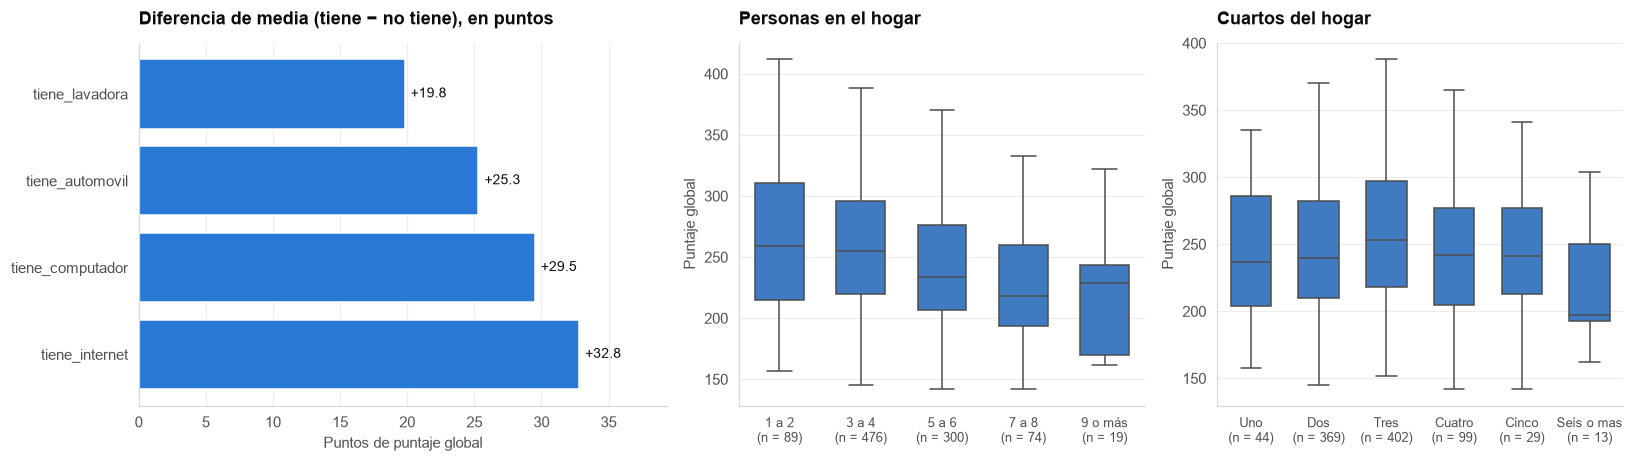

Personas en el hogar:


fami_personashogar,1 a 2,3 a 4,5 a 6,7 a 8,9 o más
n,89.00,476.00,300.00,74.00,19.00
media,260.60,257.50,242.60,226.30,217.50
mediana,259.00,255.00,234.00,218.00,229.00
desv,56.90,48.80,48.50,46.40,44.70


Cuartos del hogar:


fami_cuartoshogar,Uno,Dos,Tres,Cuatro,Cinco,Seis o mas
n,44.00,369.00,402.00,99.00,29.00,13.00
media,246.50,246.40,257.10,242.50,241.90,216.20
mediana,237.00,240.00,253.00,242.00,241.00,197.00
desv,49.20,49.30,50.70,50.70,49.00,47.40


In [20]:
BIENES = ["fami_tieneinternet", "fami_tienecomputador", "fami_tieneautomovil", "fami_tienelavadora"]
filas = []
for col in BIENES:
    g = df.groupby(col, observed=True)["punt_global"].agg(["size", "mean"])
    filas.append({"variable": col.replace("fami_tiene", "tiene_"),
                  "n_si": int(g.loc["Si", "size"]), "n_no": int(g.loc["No", "size"]),
                  "media_si": round(g.loc["Si", "mean"], 1), "media_no": round(g.loc["No", "mean"], 1),
                  "diferencia": round(g.loc["Si", "mean"] - g.loc["No", "mean"], 1)})
bienes = pd.DataFrame(filas).set_index("variable").sort_values("diferencia", ascending=False)
display(bienes)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.3, 1, 1]})
bars = axes[0].barh(bienes.index, bienes["diferencia"], color=C_BASE)
axes[0].bar_label(bars, labels=[f"+{v:.1f}" for v in bienes["diferencia"]], padding=4, fontsize=9)
axes[0].set_title("Diferencia de media (tiene − no tiene), en puntos")
axes[0].set_xlabel("Puntos de puntaje global")
axes[0].set_xlim(0, bienes["diferencia"].max() * 1.2)
axes[0].grid(axis="y", visible=False)
t_personas = caja_por(axes[1], "fami_personashogar", ORDEN["fami_personashogar"], "Personas en el hogar")
t_cuartos = caja_por(axes[2], "fami_cuartoshogar", ORDEN["fami_cuartoshogar"], "Cuartos del hogar")
fig.tight_layout()
save_fig(fig, "family_binary")
plt.show()

print("Personas en el hogar:"); display(t_personas.T)
print("Cuartos del hogar:"); display(t_cuartos.T)

Los cuatro bienes del hogar se asocian con un puntaje mayor, no por igual: **internet (+32,8 puntos) y computador (+29,5)** marcan una diferencia superior a la del automóvil (+25,3) y la lavadora (+19,8), una jerarquía idéntica a la de la población y coherente con que los dos primeros son herramientas de estudio además de indicadores de ingreso. En la composición del hogar, el puntaje **desciende a medida que crece el hogar**: 260,6 con una a dos personas, 257,5 con tres a cuatro, 242,6 con cinco a seis, 226,3 con siete a ocho y 217,5 con nueve o más. Con los cuartos la relación no es monótona: 246,5 con un cuarto, 257,1 con tres y 216,2 con seis o más (solo 13 estudiantes). Ninguna de las dos debe entrar al modelo como un simple número: la razón **personas por cuarto**, una medida de hacinamiento, es la variable derivada natural.

## 8. Variables del colegio

Las variables `cole_*` describen la institución donde el estudiante cursó la media. Se comparan el puntaje global según la **naturaleza** (oficial o no oficial), el **área** (urbana o rural), la **jornada**, el **calendario**, el **carácter** (académico, técnico o ambos), si es **bilingüe** y el **género** de la población que atiende. Son las variables que ponen a prueba la hipótesis H2. Las categorías con menos de 15 estudiantes se omiten de las gráficas pero se cuentan en las tablas.

Figura guardada: assets\images\data\school_variables.png


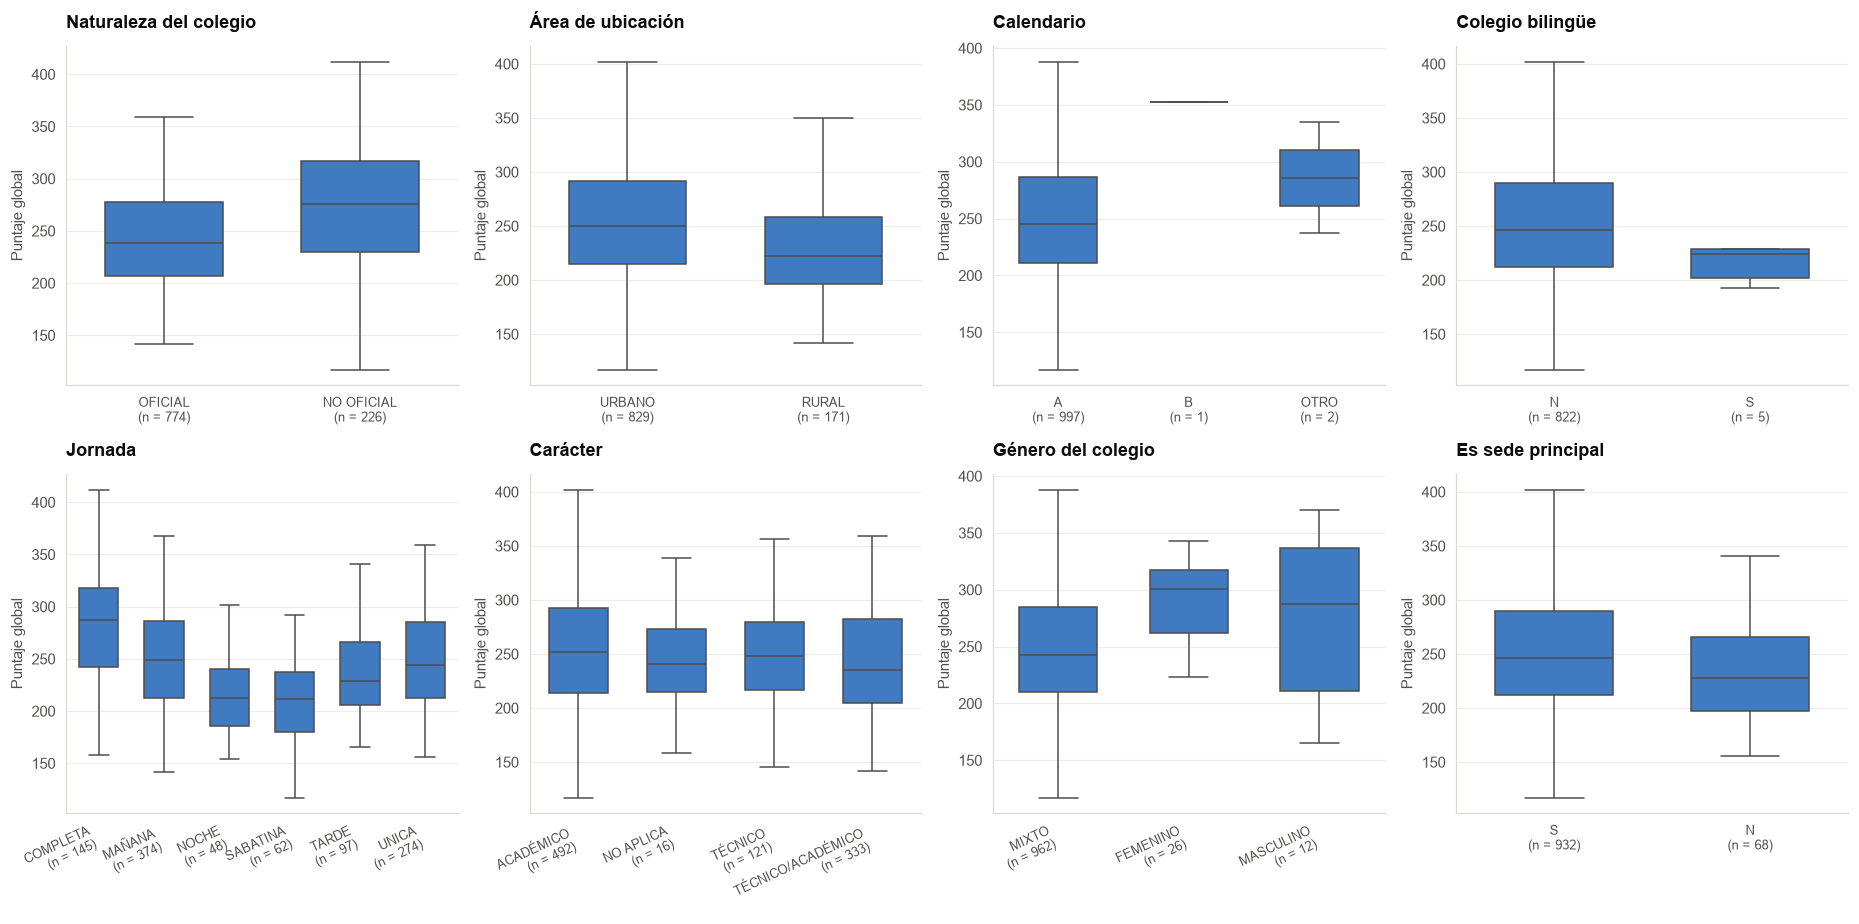

Naturaleza:


cole_naturaleza,OFICIAL,NO OFICIAL
n,774.00,226.00
media,241.80,274.30
mediana,238.50,276.00
desv,46.30,56.10


Área:


cole_area_ubicacion,URBANO,RURAL
n,829.00,171.00
media,253.30,229.10
mediana,250.00,222.00
desv,50.00,48.10


Calendario:


...

cole_jornada,COMPLETA,MAÑANA,NOCHE,SABATINA,TARDE,UNICA
n,145.00,374.00,48.00,62.00,97.00,274.00
media,280.80,250.90,215.50,213.10,238.80,247.80
mediana,287.00,248.50,212.50,211.50,229.00,244.00
desv,54.10,48.90,42.30,40.10,42.40,46.40


Carácter:


cole_caracter,ACADÉMICO,NO APLICA,TÉCNICO,TÉCNICO/ACADÉMICO
n,492.00,16.00,121.00,333.00
media,254.20,249.60,248.10,242.70
mediana,252.00,241.00,248.00,235.00
desv,51.90,54.70,44.80,48.70


Género del colegio:


cole_genero,MIXTO,FEMENINO,MASCULINO
n,962.00,26.00,12.00
media,247.70,291.50,275.00
mediana,243.00,301.00,287.50
desv,50.00,36.80,71.90


In [21]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.5))
axes = axes.ravel()
t_nat = caja_por(axes[0], "cole_naturaleza", ["OFICIAL", "NO OFICIAL"], "Naturaleza del colegio")
t_area = caja_por(axes[1], "cole_area_ubicacion", ["URBANO", "RURAL"], "Área de ubicación")
t_cal = caja_por(axes[2], "cole_calendario", ["A", "B", "OTRO"], "Calendario")
t_bil = caja_por(axes[3], "cole_bilingue", ["N", "S"], "Colegio bilingüe")
t_jor = caja_por(axes[4], "cole_jornada", None, "Jornada", rot=25, min_n=15)
t_car = caja_por(axes[5], "cole_caracter", None, "Carácter", rot=25, min_n=15)
t_gen = caja_por(axes[6], "cole_genero", ["MIXTO", "FEMENINO", "MASCULINO"], "Género del colegio", rot=25)
t_sede = caja_por(axes[7], "cole_sede_principal", ["S", "N"], "Es sede principal")
fig.tight_layout()
save_fig(fig, "school_variables")
plt.show()

for nombre, tabla in [("Naturaleza", t_nat), ("Área", t_area), ("Calendario", t_cal), ("Bilingüe", t_bil),
                      ("Jornada", t_jor), ("Carácter", t_car), ("Género del colegio", t_gen)]:
    print(f"{nombre}:"); display(tabla.T)

Las variables del colegio replican las brechas de la población. La **naturaleza** separa 32,5 puntos (no oficial 274,3, oficial 241,8) y el **área** 24,2 (urbano 253,3, rural 229,1). La **jornada** es la de mayor rango: **completa 280,8**, mañana 250,9, única 247,8, tarde 238,8, nocturna 215,5 y **sabatina 213,1**, 67,7 puntos entre extremos, que se explican en parte por la edad de quienes asisten a jornadas para adultos. El carácter académico (254,2) supera levemente al técnico/académico (242,7), y el género del colegio muestra que los femeninos (291,5, n = 26) y masculinos (275,0, n = 12) superan a los mixtos (247,7), pero son grupos muy pequeños, que mezclan colegios oficiales y privados.

Dos variables no son interpretables con 1.000 estudiantes: el **calendario** (solo 1 estudiante de calendario B y 2 de otro) y el **bilingüismo** (5 estudiantes de colegios bilingües, que promedian 224,2, frente a 250,1 de los no bilingües). Con grupos tan pequeños sus diferencias son ruido, y confirman la decisión de descartarlas o agruparlas en la fase 2.

Naturaleza y área se cruzan a menudo: la mayoría de colegios rurales son oficiales. Para separar ambos efectos se tabula el puntaje medio en las cuatro combinaciones, junto con la cantidad de estudiantes de cada una.

In [22]:
cruce = df.pivot_table(index="cole_naturaleza", columns="cole_area_ubicacion", values="punt_global",
                       aggfunc=["mean", "size"], observed=True)
cruce.columns = [f"{a}_{b}" for a, b in cruce.columns]
display(cruce.round(1))

,mean_RURAL,mean_URBANO,size_RURAL,size_URBANO
cole_naturaleza,,,,
NO OFICIAL,314.90,272.40,10,216
OFICIAL,223.80,246.60,161,613


El cruce entre naturaleza y área separa ambos efectos y reproduce la inversión de la población: entre los colegios oficiales, la brecha urbano-rural es de 22,8 puntos (246,6 frente a 223,8) pero entre los **no oficiales se invierte**: los privados rurales promedian **314,9**, el valor más alto de las cuatro celdas, aunque con solo 10 estudiantes. El orden completo es privado rural (314,9) > privado urbano (272,4) > oficial urbano (246,6) > oficial rural (223,8). Para un modelo lineal esto exige un término de interacción naturaleza × área, y la celda de los privados rurales, con n = 10, habrá que agruparla o validarla con la población antes de confiar en ella.

## 9. Variables geográficas

El departamento donde se ubica el colegio resume condiciones que las variables anteriores no capturan del todo: oferta educativa, ruralidad, conflicto, inversión pública. Se calcula el puntaje medio y la cantidad de estudiantes por departamento, se ordena y se grafica, para evaluar la hipótesis H3 y decidir cómo codificar esta variable de 33 niveles en la fase 2.

cole_depto_ubicacion,BOYACA,CALDAS,SANTANDER,CUNDINAMARCA,BOGOTÁ,GUAVIARE,PUTUMAYO,NARIÑO,HUILA,NORTE SANTANDER,CASANARE,ANTIOQUIA,ARAUCA,TOLIMA,QUINDIO,META,RISARALDA,VALLE,ATLANTICO,CAQUETA,CORDOBA,CESAR,SUCRE,BOLIVAR,MAGDALENA,LA GUAJIRA,SAN ANDRES,CAUCA,AMAZONAS,CHOCO,GUAINIA,VAUPES
n,33.00,14.00,44.00,73.00,138.00,3.00,6.00,21.00,29.00,30.00,15.00,139.00,6.00,36.00,11.00,24.00,26.00,76.00,52.00,7.00,44.00,29.00,14.00,44.00,35.00,19.00,3.00,22.00,1.00,4.00,1.00,1.00
media,276.30,270.90,267.40,266.50,266.00,261.30,256.50,255.80,253.80,252.20,251.30,247.50,247.30,246.90,245.40,244.40,244.00,241.10,240.10,239.90,237.40,236.50,235.40,232.30,228.10,220.50,220.00,219.00,213.00,186.20,174.00,154.00
mediana,280.00,272.50,267.50,270.00,263.50,276.00,255.50,248.00,256.00,240.50,261.00,238.00,236.50,241.00,266.00,245.00,242.00,238.50,229.50,259.00,234.00,232.00,228.00,229.50,228.00,214.00,193.00,212.50,213.00,179.50,174.00,154.00
desv,45.70,57.80,56.60,52.10,47.00,25.40,59.30,40.40,49.50,53.50,53.30,51.40,32.90,50.90,58.20,46.60,42.20,49.40,48.60,51.20,44.50,47.70,41.40,44.50,45.20,46.10,78.10,42.70,NaN,38.00,NaN,NaN


Figura guardada: assets\images\data\geography.png


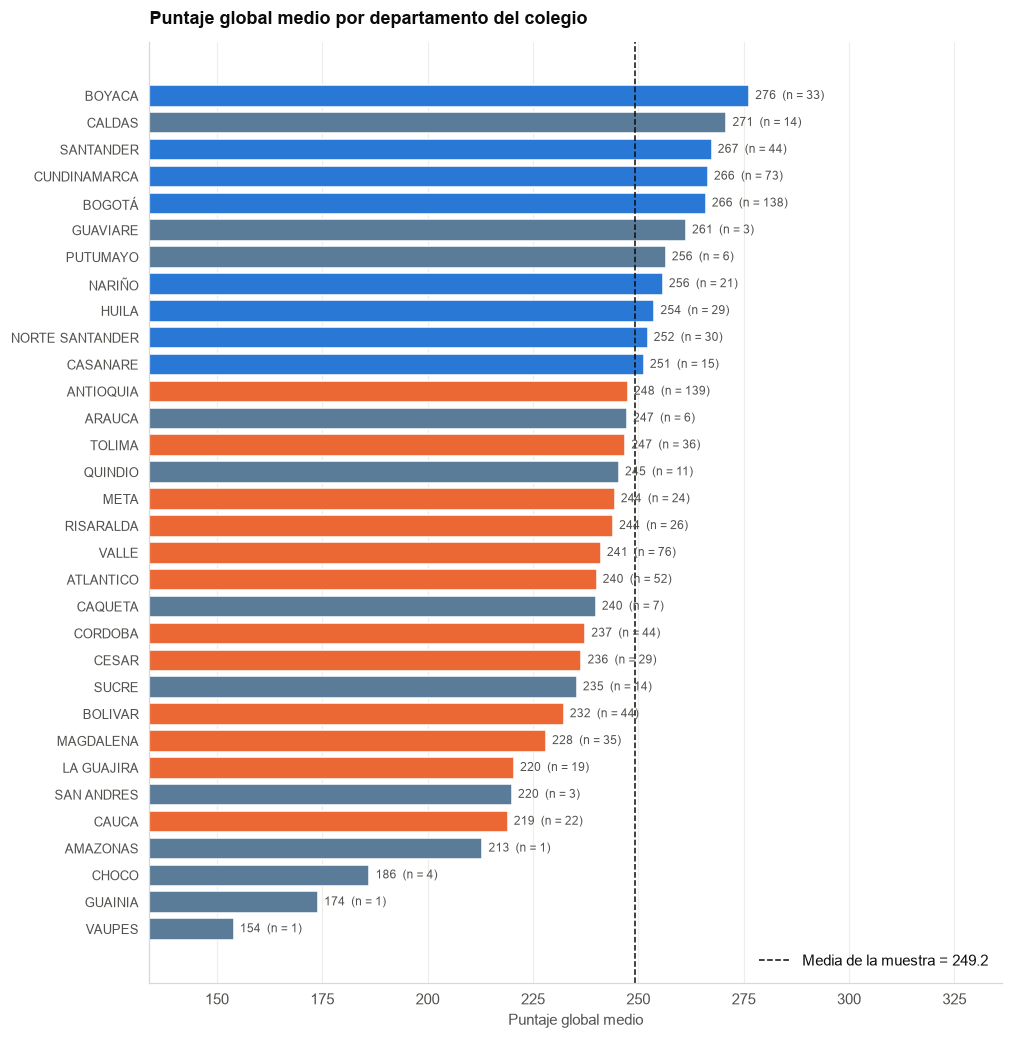

Departamentos con al menos 15 estudiantes: 20 de 32 (en gris los de menos de 15)
Brecha entre el departamento con mayor y menor media (n ≥ 15): 57.3 puntos (BOYACA vs. CAUCA)


In [23]:
geo = (df.groupby("cole_depto_ubicacion", observed=True)["punt_global"]
         .agg(n="size", media="mean", mediana="median", desv="std").round(1)
         .sort_values("media", ascending=True))
display(geo.sort_values("media", ascending=False).T)

fig, ax = plt.subplots(figsize=(10, 0.3 * len(geo) + 1.5))
colores = [C_NEU if n < 15 else (C_ACCENT if m < df["punt_global"].mean() else C_BASE) for m, n in zip(geo["media"], geo["n"])]
bars = ax.barh(geo.index, geo["media"], color=colores)
ax.bar_label(bars, labels=[f"{m:.0f}  (n = {n:,})" for m, n in zip(geo["media"], geo["n"])],
             padding=4, fontsize=8, color=GRIS)
ax.axvline(df["punt_global"].mean(), color=TINTA, linestyle="--", linewidth=1,
           label=f"Media de la muestra = {df['punt_global'].mean():.1f}")
ax.set_xlim(geo["media"].min() - 20, geo["media"].max() + 60)
ax.set_title("Puntaje global medio por departamento del colegio")
ax.set_xlabel("Puntaje global medio")
ax.tick_params(axis="y", labelsize=8.5)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save_fig(fig, "geography")
plt.show()

geo_ok = geo[geo["n"] >= 15]
print(f"Departamentos con al menos 15 estudiantes: {len(geo_ok)} de {len(geo)} (en gris los de menos de 15)")
print(f"Brecha entre el departamento con mayor y menor media (n ≥ 15): "
      f"{geo_ok['media'].max() - geo_ok['media'].min():.1f} puntos "
      f"({geo_ok['media'].idxmax()} vs. {geo_ok['media'].idxmin()})")

Los 1.000 estudiantes cubren **32 de los 33 departamentos** (falta Vichada), pero solo **20 tienen 15 estudiantes o más**; los otros 12 están en gris y no permiten sacar conclusiones, como Vaupés, Guainía y Amazonas con un único estudiante cada uno o Chocó con cuatro. Entre los 20 con tamaño suficiente, la brecha es de **57,3 puntos**, entre Boyacá (276,3, n = 33) y Cauca (219,0, n = 22), y el orden replica el de la población: encabezan Boyacá, Santander (267,4), Cundinamarca (266,5) y Bogotá (266,0, n = 138), y cierran Cauca, La Guajira (220,5), Magdalena (228,1) y Bolívar (232,3). La hipótesis H3 queda respaldada en la dirección, pero con 1.000 estudiantes la geografía fina es inviable: el municipio (332 niveles) no sirve como variable y el departamento tendrá que agruparse en regiones (Andina, Caribe, Pacífica, Orinoquía y Amazonía, y Bogotá) para que cada categoría tenga suficientes estudiantes.

## 10. Correlaciones, dispersión e independencia

### 10.1 Matriz de correlación de Spearman

Para medir conjuntamente la asociación de todas las variables candidatas con el puntaje global, las variables ordinales se codifican con enteros que respetan su orden (estrato 0 a 6, nivel educativo 0 a 9, personas y cuartos por tramo), las binarias con 0 y 1, y se calcula la **correlación de Spearman**, apropiada para variables ordinales y robusta a la no linealidad. Las categorías *No sabe* y *No Aplica* de educación de los padres se tratan como faltantes en esta codificación. La matriz incluye también los puntajes por área, para que quede documentado el contraste entre una variable explicativa legítima y una que forma parte de la respuesta.

Correlación de Spearman con punt_global (ordenada por magnitud):


variable,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_matematicas,punt_ingles,educ_madre,edad,educ_padre,tiene_computador,tiene_internet,colegio_no_oficial,tiene_automovil,personas_hogar,colegio_urbano,jornada_completa_unica,tiene_lavadora,estrato,genero_F,calendario_B,colegio_bilingue,cuartos_hogar
rho,0.92,0.91,0.91,0.91,0.77,0.35,-0.33,0.32,0.29,0.29,0.25,0.21,-0.20,0.19,0.16,0.16,0.16,-0.10,0.05,-0.04,0.02
p-valor,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.10,0.21,0.59
n,"1,000.00","1,000.00","1,000.00","1,000.00",996.00,907.00,"1,000.00",855.00,956.00,935.00,"1,000.00",952.00,958.00,"1,000.00","1,000.00",955.00,919.00,"1,000.00","1,000.00",827.00,956.00


Figura guardada: assets\images\data\correlation_matrix.png


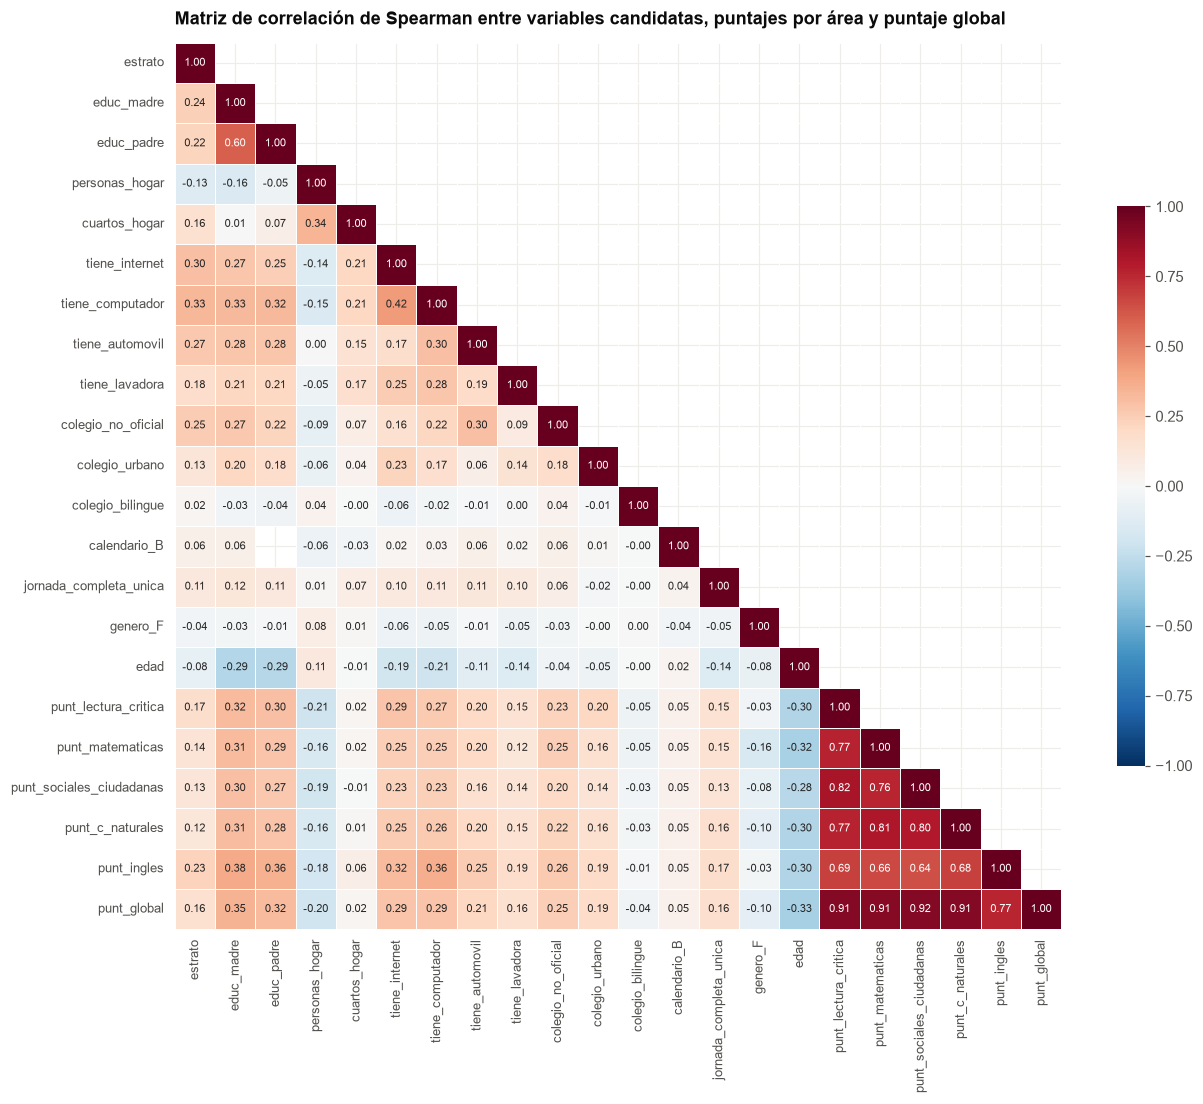

In [24]:
EDU_NIVEL = {"Ninguno": 0, "Primaria incompleta": 1, "Primaria completa": 2,
             "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
             "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
             "Educación profesional incompleta": 7, "Educación profesional completa": 8, "Postgrado": 9}
ESTRATO_NIVEL = {"Sin Estrato": 0, **{f"Estrato {i}": i for i in range(1, 7)}}
PERSONAS_NIVEL = {"1 a 2": 1, "3 a 4": 2, "5 a 6": 3, "7 a 8": 4, "9 o más": 5}
CUARTOS_NIVEL = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6}

def binaria(col, positivo):
    return df[col].map(lambda v: np.nan if pd.isna(v) else float(v == positivo))

num = pd.DataFrame({
    "estrato": df["fami_estratovivienda"].astype(object).map(ESTRATO_NIVEL),
    "educ_madre": df["fami_educacionmadre"].astype(object).map(EDU_NIVEL),
    "educ_padre": df["fami_educacionpadre"].astype(object).map(EDU_NIVEL),
    "personas_hogar": df["fami_personashogar"].astype(object).map(PERSONAS_NIVEL),
    "cuartos_hogar": df["fami_cuartoshogar"].astype(object).map(CUARTOS_NIVEL),
    "tiene_internet": binaria("fami_tieneinternet", "Si"),
    "tiene_computador": binaria("fami_tienecomputador", "Si"),
    "tiene_automovil": binaria("fami_tieneautomovil", "Si"),
    "tiene_lavadora": binaria("fami_tienelavadora", "Si"),
    "colegio_no_oficial": binaria("cole_naturaleza", "NO OFICIAL"),
    "colegio_urbano": binaria("cole_area_ubicacion", "URBANO"),
    "colegio_bilingue": binaria("cole_bilingue", "S"),
    "calendario_B": binaria("cole_calendario", "B"),
    "jornada_completa_unica": df["cole_jornada"].isin(["COMPLETA", "UNICA"]).astype(float),
    "genero_F": binaria("estu_genero", "F"),
    "edad": df["edad"],
    "punt_lectura_critica": df["punt_lectura_critica"],
    "punt_matematicas": df["punt_matematicas"],
    "punt_sociales_ciudadanas": df["punt_sociales_ciudadanas"],
    "punt_c_naturales": df["punt_c_naturales"],
    "punt_ingles": df["punt_ingles"],
    "punt_global": df["punt_global"],
})

corr = num.corr(method="spearman")
ranking = corr["punt_global"].drop("punt_global").sort_values(key=np.abs, ascending=False)
filas_rho = []
for v in ranking.index:
    d = num[[v, "punt_global"]].dropna()
    rho, p = stats.spearmanr(d[v], d["punt_global"])
    filas_rho.append({"variable": v, "rho": rho, "p-valor": p, "n": len(d)})
print("Correlación de Spearman con punt_global (ordenada por magnitud):")
display(pd.DataFrame(filas_rho).set_index("variable").round(4).T)

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, linewidths=0.4, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Matriz de correlación de Spearman entre variables candidatas, puntajes por área y puntaje global")
ax.tick_params(axis="both", labelsize=8.5)
save_fig(fig, "correlation_matrix")
plt.show()

La matriz y la tabla de Spearman con sus p-valores confirman el contraste buscado: los puntajes por área correlacionan entre **0,91 y 0,92** con el global (0,77 el inglés), mientras que **ninguna variable de contexto supera 0,35**. El orden de las variables legítimas es el de la población: educación de la madre (0,35), edad (−0,33), educación del padre (0,32), computador e internet (0,29 cada uno), colegio no oficial (0,25), automóvil (0,21), personas en el hogar (−0,20), colegio urbano (0,19), jornada completa o única, lavadora y estrato (0,16 cada una) y género femenino (−0,10). Con n = 1.000 todas son significativas (p < 0,01), salvo **calendario B (p = 0,10), bilingüismo (p = 0,21) y cuartos del hogar (p = 0,59)**, que no tienen asociación monótona detectable. La matriz también muestra que las variables del hogar están correlacionadas entre sí (educación de la madre y del padre, estrato y bienes miden el mismo nivel socioeconómico), un riesgo de multicolinealidad para un modelo lineal.

### 10.2 Diagramas de dispersión

La matriz de correlación resume cada relación en un número; el diagrama de dispersión muestra su **forma**. Se grafica el puntaje global contra cada puntaje por área y contra la edad, con la recta de mínimos cuadrados y los coeficientes de Pearson (relación lineal) y Spearman (relación monótona). La distancia entre ambos coeficientes avisa de relaciones no lineales o de valores influyentes. Los puntajes por área se incluyen para documentar la fuga de información: el puntaje global se calcula a partir de ellos y la nube lo muestra.

Figura guardada: assets\images\data\scatter_plots.png


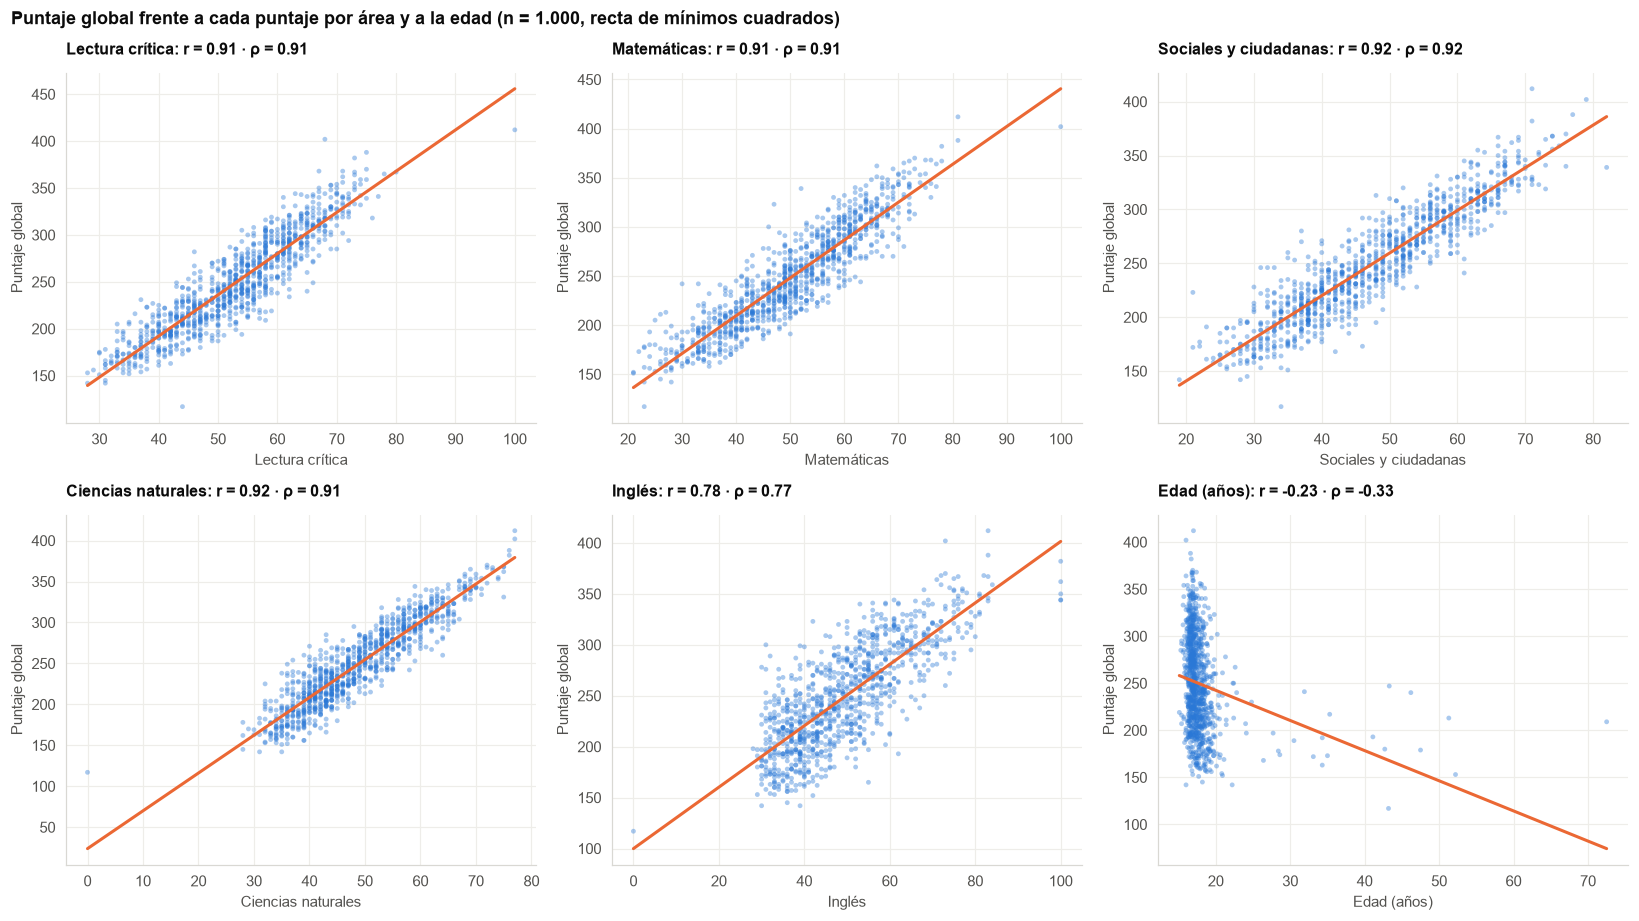

,n,Pearson r,Spearman ρ,pendiente (puntos globales por unidad)
variable,,,,
punt_lectura_critica,1000,0.91,0.91,4.39
punt_matematicas,1000,0.91,0.91,3.85
punt_sociales_ciudadanas,1000,0.92,0.92,3.96
punt_c_naturales,1000,0.92,0.92,4.62
punt_ingles,996,0.78,0.77,3.02
edad,1000,-0.23,-0.33,-3.20


In [25]:
VARS_DISP = [("punt_lectura_critica", "Lectura crítica"), ("punt_matematicas", "Matemáticas"),
             ("punt_sociales_ciudadanas", "Sociales y ciudadanas"), ("punt_c_naturales", "Ciencias naturales"),
             ("punt_ingles", "Inglés"), ("edad", "Edad (años)")]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
filas = []
for ax, (c, nombre) in zip(axes.ravel(), VARS_DISP):
    d = df[[c, "punt_global"]].dropna().astype(float)
    ax.scatter(d[c], d["punt_global"], s=10, alpha=0.4, color=C_BASE, edgecolors="none")
    m, b = np.polyfit(d[c], d["punt_global"], 1)
    xs = np.linspace(d[c].min(), d[c].max(), 50)
    ax.plot(xs, m * xs + b, color=C_ACCENT, linewidth=2)
    r, rho = d.corr().iloc[0, 1], d.corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{nombre}: r = {r:.2f} · ρ = {rho:.2f}", fontsize=10.5)
    ax.set_xlabel(nombre); ax.set_ylabel("Puntaje global")
    filas.append({"variable": c, "n": len(d), "Pearson r": r, "Spearman ρ": rho, "pendiente (puntos globales por unidad)": m})
fig.suptitle("Puntaje global frente a cada puntaje por área y a la edad (n = 1.000, recta de mínimos cuadrados)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "scatter_plots")
plt.show()
display(pd.DataFrame(filas).set_index("variable").round(3))

Los diagramas de dispersión muestran las relaciones con el puntaje global. Con los **cuatro puntajes por área de mayor peso** la nube es una franja estrecha alrededor de la recta (r = 0,91 a 0,92, con Pearson y Spearman prácticamente iguales, de modo que la relación es lineal), y con **inglés** la franja es más ancha (r = 0,78), porque pesa menos en el promedio. Es la evidencia visual de la fuga de información. En los paneles de ciencias naturales e inglés se ve un punto aislado en el cero que corresponde a un único estudiante con 0 en ambas pruebas y puntaje global 117, un caso influyente que arrastra la recta de ciencias naturales hasta cruzar el eje vertical en 25.

En el panel de la **edad**, la relación es distinta: Pearson (−0,23) es menor que Spearman (−0,33) porque unos pocos adultos de hasta 72 años dominan la recta lineal mientras que la relación monótona es más fuerte y se concentra entre los 16 y los 22 años, donde el puntaje cae con la edad. Una relación así se captura mejor con tramos de edad, el logaritmo de la edad o un modelo no lineal que con una recta.

### 10.3 Pruebas de independencia χ²

La prueba χ² contrasta, para dos variables cualitativas, la hipótesis nula de que son **independientes**. Se aplica entre cada variable cualitativa del conjunto y el **nivel de desempeño** (bajo, medio o alto), una variable de clasificación derivada que se construye con los **terciles del puntaje global**. La elección de terciles tiene una ventaja metodológica: produce tres clases balanceadas, de modo que no hará falta rebalancear (SMOTE o `class_weight`) en la fase de clasificación. El nivel de desempeño depende solo de `punt_global`; las variables explicativas siguen sin incluir ningún puntaje por área.

Con 1.000 observaciones la prueba es informativa, pero exige cuidado: se agrupan en *Otras* las categorías con menos de 20 estudiantes, se reporta el porcentaje de celdas con frecuencia esperada menor que 5 (por encima de 20 % la aproximación χ² pierde validez) y se ajustan los p-valores por la multiplicidad de pruebas con el procedimiento de Benjamini-Hochberg, que controla la tasa de falsos descubrimientos. Como un p-valor solo dice si hay asociación y no su tamaño, se agrega el **V de Cramér corregido por sesgo**, que va de 0 (independencia) a 1 (asociación perfecta). Las variables de identificación y las de cardinalidad mayor a 40 no se prueban. `desemp_ingles` se incluye solo para documentar que está asociada al desempeño porque se deriva de `punt_ingles`, y por eso no puede usarse como predictora.

Nivel de desempeño por terciles del puntaje global: Bajo ≤ 222.0 < Medio ≤ 273.0 < Alto


nivel_desempeno,Bajo,Medio,Alto
estudiantes,335.00,335.00,330.00
%,33.50,33.50,33.00


,niveles,χ²,gl,p-valor,p ajustado (BH),V de Cramér,V corregido,% celdas con esperado < 5,"asociada (p ajustado < 0,05)"
variable,,,,,,,,,
desemp_ingles,6,530.27,10,0.00,0.00,0.51,0.51,16.67,True
fami_educacionmadre,12,135.70,22,0.00,0.00,0.26,0.24,0.00,True
edad_grupo,6,116.96,10,0.00,0.00,0.24,0.23,0.00,True
cole_jornada,6,102.69,10,0.00,0.00,0.23,0.22,0.00,True
fami_educacionpadre,10,110.41,18,0.00,0.00,0.23,0.22,0.00,True
cole_naturaleza,2,45.59,2,0.00,0.00,0.21,0.21,0.00,True
fami_tienecomputador,3,70.12,4,0.00,0.00,0.19,0.18,0.00,True
fami_tieneinternet,3,66.73,4,0.00,0.00,0.18,0.18,0.00,True
cole_area_ubicacion,2,32.80,2,0.00,0.00,0.18,0.18,0.00,True


Variables probadas: 26 · asociadas al nivel de desempeño tras el ajuste: 20 · con más de 20 % de celdas de esperado < 5: 5


,niveles,χ²,gl,p-valor,V de Cramér,V corregido,% celdas con esperado < 5
par de variables,,,,,,,
fami_estratovivienda × fami_educacionmadre,7,890.83,66,0.00,0.39,0.37,42.86
fami_tieneinternet × fami_tienecomputador,3,417.95,4,0.00,0.46,0.46,11.11
cole_naturaleza × cole_area_ubicacion,2,31.95,1,0.00,0.18,0.18,0.00
cole_jornada × edad_grupo,6,344.80,25,0.00,0.26,0.25,30.56
fami_educacionmadre × fami_educacionpadre,12,"1,722.63",99,0.00,0.44,0.43,47.50


Figura guardada: assets\images\data\chi_square_cramers_v.png


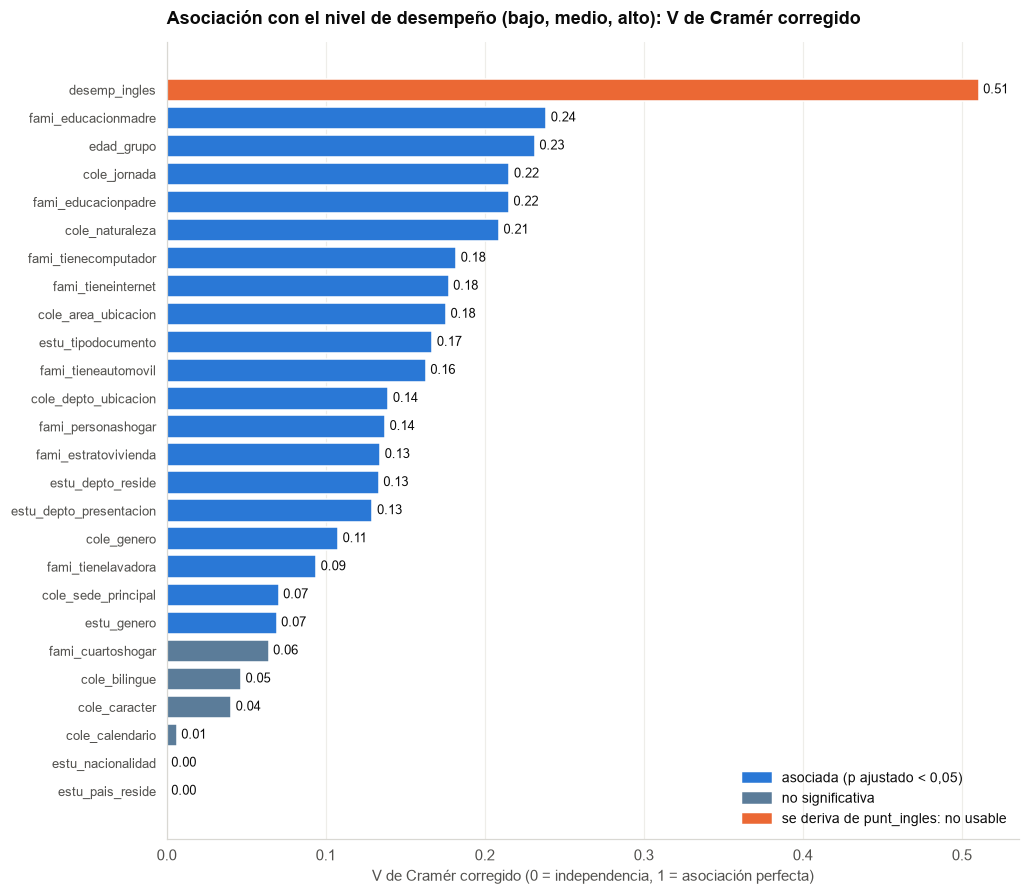

In [26]:
df["nivel_desempeno"] = pd.qcut(df["punt_global"], 3, labels=["Bajo", "Medio", "Alto"])
cortes = df["punt_global"].quantile([1 / 3, 2 / 3]).round(1).tolist()
print(f"Nivel de desempeño por terciles del puntaje global: Bajo ≤ {cortes[0]} < Medio ≤ {cortes[1]} < Alto")
display(df["nivel_desempeno"].value_counts().sort_index().to_frame("estudiantes").assign(**{"%": lambda d: d["estudiantes"] / len(df) * 100}).round(1).T)

NO_PROBAR = set(ID_COLS) | {"periodo", "estu_estudiante", "nivel_desempeno", "estu_estadoinvestigacion"}
candidatas = [c for c in df.columns
              if str(df[c].dtype) in ("category", "string", "object") and c not in NO_PROBAR
              and not c.startswith(("cole_cod_", "cole_nombre_", "estu_cod_")) and c not in ("cole_codigo_icfes", "cole_mcpio_ubicacion",
              "estu_mcpio_presentacion", "estu_mcpio_reside") and 2 <= df[c].nunique() <= 40]
filas = []
for c in candidatas:
    res = chi2_v(colapsar(df[c]), df["nivel_desempeno"])
    if res:
        filas.append({"variable": c, **res})
chi = pd.DataFrame(filas).set_index("variable")

# Ajuste de Benjamini-Hochberg
orden = chi["p-valor"].sort_values()
m = len(orden)
bh = (orden * m / np.arange(1, m + 1))[::-1].cummin()[::-1].clip(upper=1)
chi["p ajustado (BH)"] = bh.reindex(chi.index)
chi["asociada (p ajustado < 0,05)"] = chi["p ajustado (BH)"] < 0.05
chi = chi.sort_values("V corregido", ascending=False)
with pd.option_context("display.width", 220):
    display(chi[["niveles", "χ²", "gl", "p-valor", "p ajustado (BH)", "V de Cramér", "V corregido", "% celdas con esperado < 5", "asociada (p ajustado < 0,05)"]].round(4))
print(f"Variables probadas: {len(chi)} · asociadas al nivel de desempeño tras el ajuste: {int(chi['asociada (p ajustado < 0,05)'].sum())} · "
      f"con más de 20 % de celdas de esperado < 5: {int((chi['% celdas con esperado < 5'] > 20).sum())}")

pares = [("fami_estratovivienda", "fami_educacionmadre"), ("fami_tieneinternet", "fami_tienecomputador"),
         ("cole_naturaleza", "cole_area_ubicacion"), ("cole_jornada", "edad_grupo"), ("fami_educacionmadre", "fami_educacionpadre")]
filas = []
for a, b in pares:
    res = chi2_v(colapsar(df[a]), colapsar(df[b]))
    filas.append({"par de variables": f"{a} × {b}", **res})
display(pd.DataFrame(filas).set_index("par de variables").round(4))

fig, ax = plt.subplots(figsize=(10, 0.3 * len(chi) + 1.6))
orden_plot = chi["V corregido"].sort_values()
colores = [C_ACCENT if v == "desemp_ingles" else (C_BASE if chi.loc[v, "asociada (p ajustado < 0,05)"] else C_NEU) for v in orden_plot.index]
bars = ax.barh(orden_plot.index, orden_plot.values, color=colores)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in orden_plot.values], padding=3, fontsize=8.5)
ax.set_title("Asociación con el nivel de desempeño (bajo, medio, alto): V de Cramér corregido")
ax.set_xlabel("V de Cramér corregido (0 = independencia, 1 = asociación perfecta)")
ax.tick_params(axis="y", labelsize=8.5); ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=C_BASE, label="asociada (p ajustado < 0,05)"), Patch(color=C_NEU, label="no significativa"),
                   Patch(color=C_ACCENT, label="se deriva de punt_ingles: no usable")], frameon=False, loc="lower right", fontsize=9)
save_fig(fig, "chi_square_cramers_v")
plt.show()

**El nivel de desempeño queda definido por terciles** del puntaje global (Bajo hasta 222, Medio hasta 273 y Alto por encima), con **335, 335 y 330 estudiantes**: tres clases balanceadas (razón de desbalance 1,02), de modo que la clasificación no necesita SMOTE ni ajuste de `class_weight`.

De las **26 variables probadas, 20 están asociadas con el nivel de desempeño** tras el ajuste de Benjamini-Hochberg. Las más fuertes, excluida `desemp_ingles` (V = 0,51, que se deriva de `punt_ingles` y no es utilizable), son la **educación de la madre (V = 0,24)**, la **edad (0,23)**, la **jornada (0,22)**, la **educación del padre (0,22)**, la **naturaleza del colegio (0,21)**, el computador y el internet (0,18 cada uno) y el área (0,18); le siguen el tipo de documento, el automóvil y el departamento (0,14 a 0,17). No hay evidencia de asociación en los cuartos del hogar (p ajustado = 0,08), el bilingüismo, el carácter, el calendario, la nacionalidad ni el país de residencia. Todas las asociaciones son **pequeñas o moderadas** (V ≤ 0,24), coherentes con un R² lineal cercano a 0,25: el contexto ayuda a clasificar pero no determina el resultado.

Una limitación de validez: 5 pruebas tienen más del 20 % de celdas con frecuencia esperada menor que 5 (género del colegio, bilingüismo, calendario, nacionalidad y país), de modo que su conclusión es frágil; la más relevante, el género del colegio (V = 0,11), debe leerse con cautela. Los pares de variables del hogar confirman la **redundancia interna**: internet y computador (V = 0,46), educación de la madre y del padre (0,43), estrato y educación de la madre (0,37) y jornada y edad (0,25). Eso justifica la regularización o un índice socioeconómico compuesto en la fase 2.

### 10.4 Ajuste lineal exploratorio

Las variables del hogar están correlacionadas entre sí (estrato, educación de los padres y tenencia de bienes miden facetas del mismo nivel socioeconómico). Para tener una primera idea de cuánta varianza del puntaje explica el conjunto de variables candidatas, se ajusta una **regresión lineal exploratoria** sobre las variables codificadas, excluyendo los puntajes por área. Con 1.000 filas no hay holgura para reservar un conjunto de prueba grande, así que el desempeño se estima con **validación cruzada de 5 pliegues**: cada estudiante se predice con un modelo que no lo vio. No es el modelo de referencia de la fase 2, que se construirá con la limpieza completa y la partición definitiva; es una cota rápida de lo que la fase 1 deja sobre la mesa y de que el objetivo de mejorar el error de la media es alcanzable.

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, r2_score

PREDICTORAS = [c for c in num.columns if not c.startswith("punt_")]
completos = num[PREDICTORAS + ["punt_global"]].dropna()
X, y = completos[PREDICTORAS], completos["punt_global"]
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pred = pd.Series(np.nan, index=y.index); pred_media = pd.Series(np.nan, index=y.index); r2_pliegues = []
for tr, te in kf.split(X):
    modelo = LinearRegression().fit(X.iloc[tr], y.iloc[tr])
    pred.iloc[te] = modelo.predict(X.iloc[te])
    pred_media.iloc[te] = y.iloc[tr].mean()
    r2_pliegues.append(r2_score(y.iloc[te], pred.iloc[te]))
mae_lineal, mae_media = mean_absolute_error(y, pred), mean_absolute_error(y, pred_media)
print(f"Filas completas usadas: {len(completos):,} de {len(df):,} · {len(PREDICTORAS)} variables · validación cruzada de 5 pliegues")
print(f"R² (validación cruzada) : {r2_score(y, pred):.3f}  (por pliegue: {', '.join(f'{r:.2f}' for r in r2_pliegues)}; media {np.mean(r2_pliegues):.3f} ± {np.std(r2_pliegues):.3f})")
print(f"MAE (validación cruzada): {mae_lineal:.1f} puntos · MAE de predecir la media: {mae_media:.1f} · mejora: {(1 - mae_lineal / mae_media) * 100:.1f} %")

coefs = pd.Series(LinearRegression().fit(X, y).coef_, index=PREDICTORAS).sort_values(key=np.abs, ascending=False)
display(coefs.round(2).to_frame("coeficiente (puntos por unidad)").T)

Filas completas usadas: 654 de 1,000 · 16 variables · validación cruzada de 5 pliegues
R² (validación cruzada) : 0.247  (por pliegue: 0.38, 0.15, 0.26, 0.26, 0.19; media 0.247 ± 0.080)
MAE (validación cruzada): 35.9 puntos · MAE de predecir la media: 41.9 · mejora: 14.3 %


,colegio_no_oficial,tiene_internet,colegio_bilingue,tiene_computador,tiene_automovil,genero_F,jornada_completa_unica,colegio_urbano,personas_hogar,educ_padre,tiene_lavadora,cuartos_hogar,estrato,educ_madre,edad,calendario_B
coeficiente (puntos por unidad),20.36,19.36,-13.93,8.62,7.63,-7.26,6.72,6.36,-6.05,3.59,3.53,-3.46,-2.92,2.08,-1.59,0.00


Con las 654 filas que no tienen ningún faltante (el 65 % de la muestra) y 16 variables codificadas, la regresión lineal alcanza un **R² de 0,247 en validación cruzada y un MAE de 35,9 puntos**, frente a 41,9 de predecir siempre la media: una reducción del error del **14,3 %**. El R² por pliegue va de 0,15 a 0,38 (media 0,247, desviación 0,080), una variación que muestra el costo de trabajar con 1.000 estudiantes: cualquier cifra de rendimiento debe acompañarse de su dispersión entre pliegues. Los coeficientes ratifican los resultados bivariados: colegio no oficial (+20,4 puntos), internet (+19,4), computador (+8,6), automóvil (+7,6), jornada completa o única (+6,7) y colegio urbano (+6,4), mientras la edad resta 1,6 por año y las personas en el hogar 6,1 por tramo. El coeficiente del bilingüismo (−13,9) se apoya en 5 estudiantes y no es confiable.

Este ajuste es una cota conservadora, porque descarta el 35 % de la muestra y usa solo relaciones lineales. Con la imputación o el indicador de faltantes, la edad transformada y modelos no lineales debería superar el 15 % de reducción del error fijado como meta del objetivo general.

## 11. Idoneidad del dataset para regresión, clasificación y clustering

La guía exige que el dataset permita extraer, a la vez, **una variable continua para regresión**, **una variable categórica (o derivada) para clasificación** y **varias variables cuantitativas para clustering**. Esta sección lo comprueba con datos, no con una declaración:

*   **Regresión**: `punt_global`, cuantitativa con una distribución casi simétrica (sección 5).
*   **Clasificación**: `nivel_desempeno` (bajo, medio, alto), derivada de los terciles de `punt_global`. Se verifica que las clases estén balanceadas y que su asociación con el contexto no sea trivial (sección 10.3).
*   **Clustering**: los cinco puntajes por área y la edad. Se comprueba con tres pruebas rápidas que la estructura es segmentable: la proporción de varianza que captura un análisis de componentes principales de dos dimensiones, el **método del codo** (inercia de K-means según K) y el **coeficiente de silueta** (de −1 a 1, donde, según la regla de Kaufman y Rousseeuw, 0,26 a 0,50 indica una estructura débil pero real y más de 0,50 una estructura razonable). Es una verificación de viabilidad, no el análisis final de clustering, que se hace en la fase 3 con dos algoritmos y la interpretación de los perfiles.

Al final, una tabla compara cada requisito de la guía con lo que muestran los datos.

Perfil de los 3 clústeres de K-means (verificación de viabilidad):


,estudiantes,edad,lectura,matematicas,sociales,naturales,ingles,global_
clúster 0,432,17.10,61.80,60.50,57.70,57.80,59.90,297.40
clúster 1,552,17.80,46.30,42.70,39.50,42.10,42.00,213.00
clúster 2,16,42.20,41.80,35.60,40.70,37.40,33.90,192.40


Varianza explicada por 2 componentes principales: 83.0 % (1.º: 67.4 %)
Silueta por K: K=2: 0.418 · K=3: 0.434 · K=4: 0.314 · K=5: 0.248 · K=6: 0.223 · K=7: 0.218 · K=8: 0.189  → mayor silueta en K = 3
Clases del nivel de desempeño: Bajo: 335 · Medio: 335 · Alto: 330 · razón de desbalance (mayor/menor): 1.02


Figura guardada: assets\images\data\versatility_check.png


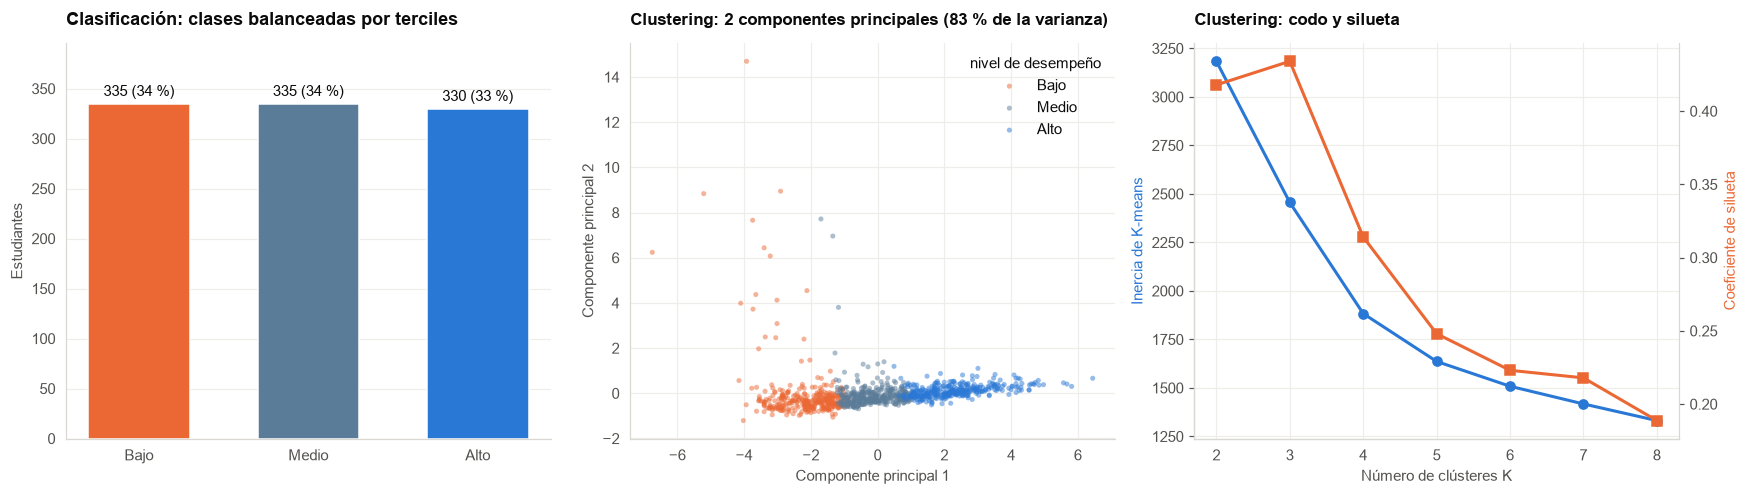

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

CLUSTER_VARS = ["punt_lectura_critica", "punt_matematicas", "punt_sociales_ciudadanas", "punt_c_naturales", "punt_ingles", "edad"]
Xc = df[CLUSTER_VARS].astype(float)
Xc = Xc.fillna(Xc.median())
Z = StandardScaler().fit_transform(Xc)

pca = PCA(n_components=len(CLUSTER_VARS), random_state=RANDOM_STATE).fit(Z)
var_acum = pca.explained_variance_ratio_.cumsum()
ks = list(range(2, 9))
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inercia.append(km.inertia_); silueta.append(silhouette_score(Z, km.labels_))
k_mejor = ks[int(np.argmax(silueta))]
km_mejor = KMeans(n_clusters=k_mejor, n_init=10, random_state=RANDOM_STATE).fit(Z)
perfil = (Xc.assign(punt_global=df["punt_global"].to_numpy(), cluster=km_mejor.labels_).groupby("cluster")
            .agg(estudiantes=("edad", "size"), edad=("edad", "mean"), lectura=("punt_lectura_critica", "mean"),
                 matematicas=("punt_matematicas", "mean"), sociales=("punt_sociales_ciudadanas", "mean"),
                 naturales=("punt_c_naturales", "mean"), ingles=("punt_ingles", "mean"), global_=("punt_global", "mean")))
perfil.index = [f"clúster {i}" for i in perfil.index]
print(f"Perfil de los {k_mejor} clústeres de K-means (verificación de viabilidad):")
display(perfil.round(1))
print(f"Varianza explicada por 2 componentes principales: {var_acum[1] * 100:.1f} % (1.º: {pca.explained_variance_ratio_[0] * 100:.1f} %)")
print(f"Silueta por K: " + " · ".join(f"K={k}: {s:.3f}" for k, s in zip(ks, silueta)) + f"  → mayor silueta en K = {k_mejor}")
print(f"Clases del nivel de desempeño: " + " · ".join(f"{k}: {v}" for k, v in df['nivel_desempeno'].value_counts().sort_index().items()) +
      f" · razón de desbalance (mayor/menor): {df['nivel_desempeno'].value_counts().max() / df['nivel_desempeno'].value_counts().min():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
conteo = df["nivel_desempeno"].value_counts().sort_index()
bars = axes[0].bar(conteo.index.astype(str), conteo.values, color=[C_ACCENT, C_NEU, C_BASE], width=0.6)
axes[0].bar_label(bars, labels=[f"{v} ({v / len(df) * 100:.0f} %)" for v in conteo.values], padding=3, fontsize=9.5)
axes[0].set_title("Clasificación: clases balanceadas por terciles"); axes[0].set_ylabel("Estudiantes"); axes[0].set_ylim(0, conteo.max() * 1.18)
axes[0].grid(axis="x", visible=False)

pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z)
for nivel, color in zip(["Bajo", "Medio", "Alto"], [C_ACCENT, C_NEU, C_BASE]):
    m = (df["nivel_desempeno"] == nivel).to_numpy()
    axes[1].scatter(pcs[m, 0], pcs[m, 1], s=11, alpha=0.5, color=color, edgecolors="none", label=nivel)
axes[1].set_title(f"Clustering: 2 componentes principales ({var_acum[1] * 100:.0f} % de la varianza)", fontsize=11)
axes[1].set_xlabel("Componente principal 1"); axes[1].set_ylabel("Componente principal 2"); axes[1].legend(frameon=False, title="nivel de desempeño")

axes[2].plot(ks, inercia, marker="o", color=C_BASE, linewidth=2, label="inercia (codo)")
axes[2].set_xlabel("Número de clústeres K"); axes[2].set_ylabel("Inercia de K-means", color=C_BASE)
ax2 = axes[2].twinx()
ax2.plot(ks, silueta, marker="s", color=C_ACCENT, linewidth=2, label="silueta")
ax2.set_ylabel("Coeficiente de silueta", color=C_ACCENT); ax2.grid(False); ax2.spines["right"].set_visible(True)
axes[2].set_title("Clustering: codo y silueta", fontsize=11); axes[2].set_xticks(ks)
fig.tight_layout()
save_fig(fig, "versatility_check")
plt.show()

La verificación muestra que el dataset **sí permite los tres problemas, con matices**:

*   **Clasificación**: las tres clases por terciles están balanceadas (335, 335 y 330), la condición más favorable para clasificar.
*   **Clustering**: dos componentes principales capturan el **83,0 %** de la varianza (el primero, el 67,4 %): los cinco puntajes y la edad se resumen casi en una sola dimensión, el **nivel general de desempeño**. La silueta de K-means sube de 0,418 con K = 2 a **0,434 con K = 3** y luego baja (0,314 con K = 4 y 0,189 con K = 8); el codo es poco marcado. Estas cifras son una estructura débil pero real según la regla de Kaufman y Rousseeuw (0,26 a 0,50).
*   **Lo que revela el perfil de los clústeres con K = 3**: dos de ellos son los estudiantes de **alto desempeño** (432 estudiantes, 297 puntos globales, edad 17,1) y de **bajo desempeño** (552, 213 puntos), y el tercero son apenas **16 estudiantes adultos** (edad media 42,2 años, 192 puntos). La silueta máxima se debe en parte a esos adultos, que forman un grupo aparte por su edad y no por su perfil académico. En la fase 3 conviene aplicar un escalado robusto o el logaritmo de la edad, probar K de 2 a 5 y usar DBSCAN para aislar a los adultos como ruido en lugar de dejarlos formar un clúster.

Un resultado honesto: el clustering sobre los puntajes por área encuentra sobre todo *niveles* de desempeño, no *perfiles* (por ejemplo, fuertes en matemáticas y débiles en lectura), porque las áreas están muy correlacionadas (0,7 a 0,8). Una estrategia complementaria para la fase 3 es segmentar sobre las diferencias entre áreas respecto del promedio del estudiante, que sí separan perfiles.

In [29]:
n_cuant = int(dicc["tipo de variable"].str.startswith("Cuantitativa").sum())
n_cual = int(dicc["tipo de variable"].str.startswith("Cualitativa").sum())
n_clases = df["nivel_desempeno"].nunique()
desbalance = df["nivel_desempeno"].value_counts().max() / df["nivel_desempeno"].value_counts().min()
requisitos = pd.DataFrame([
    ("Repositorio público permitido", "datos.gov.co (portal oficial de datos abiertos) y Kaggle, licencia CC BY-SA 4.0", True),
    ("No es un dataset didáctico prohibido", "Datos administrativos reales del ICFES; no es un conjunto de enseñanza", True),
    ("Al menos 600 registros", f"{len(df):,} registros únicos", len(df) >= 600),
    ("Al menos 5 variables de tipos mixtos", f"{n_cuant} cuantitativas y {n_cual} cualitativas ({len(dicc)} columnas)", len(dicc) >= 5 and n_cuant > 0 and n_cual > 0),
    ("Una variable continua para regresión", f"punt_global ({df['punt_global'].nunique()} valores distintos, asimetría {df['punt_global'].skew():.2f})", df["punt_global"].nunique() > 20),
    ("Una variable categórica para clasificación", f"nivel_desempeno ({n_clases} clases, razón de desbalance {desbalance:.2f})", n_clases >= 2 and desbalance < 1.5),
    ("Varias variables cuantitativas para clustering", f"{len(CLUSTER_VARS)} variables; silueta máxima {max(silueta):.2f} en K = {k_mejor}", len(CLUSTER_VARS) >= 2),
], columns=["requisito de la guía", "evidencia", "cumple"]).set_index("requisito de la guía")
requisitos["cumple"] = requisitos["cumple"].map({True: "Sí", False: "No"})
with pd.option_context("display.max_colwidth", 120, "display.width", 200):
    display(requisitos)
assert (requisitos["cumple"] == "Sí").all()

,evidencia,cumple
requisito de la guía,,
Repositorio público permitido,"datos.gov.co (portal oficial de datos abiertos) y Kaggle, licencia CC BY-SA 4.0",Sí
No es un dataset didáctico prohibido,Datos administrativos reales del ICFES; no es un conjunto de enseñanza,Sí
Al menos 600 registros,"1,000 registros únicos",Sí
Al menos 5 variables de tipos mixtos,7 cuantitativas y 44 cualitativas (51 columnas),Sí
Una variable continua para regresión,"punt_global (212 valores distintos, asimetría 0.22)",Sí
Una variable categórica para clasificación,"nivel_desempeno (3 clases, razón de desbalance 1.02)",Sí
Varias variables cuantitativas para clustering,6 variables; silueta máxima 0.43 en K = 3,Sí


Los siete requisitos de la guía se cumplen con evidencia calculada: repositorio permitido y licencia libre, dataset real y no didáctico, **1.000 registros únicos** (el mínimo es 600), **51 columnas de tipos mixtos** (7 cuantitativas y 44 cualitativas), una variable continua para regresión (`punt_global`, 212 valores distintos y asimetría 0,22), una variable categórica para clasificación (`nivel_desempeno`, 3 clases con razón de desbalance de 1,02) y 6 variables cuantitativas para clustering con silueta máxima de 0,43. La aserción final detiene el cuaderno si alguno dejara de cumplirse.

## 12. Hallazgos y decisiones para la fase 2

El análisis exploratorio deja un conjunto de hallazgos que se traducen directamente en decisiones de preparación de datos, ingeniería de variables y diseño de los modelos. Se resumen en la tabla, junto con la evidencia que las sustenta.

| # | Hallazgo | Evidencia | Decisión para la fase 2 |
|---|---|---|---|
| 1 | La muestra representa a la población. | Diferencia máxima de 3,0 puntos porcentuales; 0 de 11 pruebas χ² significativas; medias de los puntajes a menos de un error estándar. | Trabajar con los 1.000 estudiantes; reportar siempre la dispersión entre pliegues de validación cruzada. |
| 2 | La población duplica cada registro; la muestra no tiene duplicados. | 0 filas repetidas, 1.000 identificadores únicos. | Mantener `drop_duplicates` como control antes de cualquier partición. |
| 3 | El puntaje global es una función exacta de los puntajes por área. | Fórmula verificada en el 100 % de los 996 casos; correlaciones de 0,91 a 0,92. | Excluir las cinco áreas y `desemp_ingles` de la regresión y la clasificación; usar las áreas solo en el clustering. |
| 4 | Los faltantes no son MCAR. | Cuestionario incompleto: −24,6 puntos y dependencia de jornada y departamento; bilingüismo: faltante estructural asociado al carácter (V = 0,50). | No eliminar filas ni imputar con la media; categoría *No respondió* con indicador de cuestionario incompleto; `cole_bilingue` como *No reportado* o descartada. |
| 5 | La edad tiene una cola extrema de adultos. | Asimetría 8,2; 45 atípicos por IQR (4,5 %); máximo de 72,5 años. | Conservar a los adultos; winsorizar la edad en el percentil 99 (35 años) o usar su logaritmo; crear el indicador de extraedad (19 años o más). |
| 6 | Los atípicos de puntaje son pocos y reales. | De 0 a 6 por prueba (0 % a 0,6 %); un estudiante con 0 en naturales e inglés. | Conservarlos; el caso del cero se revisa como posible prueba parcial. |
| 7 | Hay columnas sin información, redundantes o inviables. | 4 constantes; 12 identificadores; municipio con 332 niveles en 1.000 filas; calendario 99,7 % A; bilingüismo con 5 casos. | Descartar constantes, identificadores, nombres, municipio, calendario y bilingüismo; conservar el departamento agrupado en regiones. |
| 8 | La educación de los padres y el acceso a internet y computador son las variables del hogar más asociadas. | ρ = 0,35 y 0,32 (educación), 0,29 (internet y computador); V = 0,24 y 0,22. | Educación de los padres como ordinal con un indicador de *No sabe*; bienes como binarias. |
| 9 | Las variables del hogar son redundantes entre sí. | V = 0,46 (internet × computador), 0,43 (educación de los padres), 0,37 (estrato × educación). | Regularización (Ridge, Lasso) y un índice socioeconómico compuesto; ensambles de árboles como alternativa. |
| 10 | El estrato es inestable en los niveles altos. | Estratos 5 y 6 con 16 y 11 estudiantes y desviaciones de 64 y 76 puntos. | Agrupar los estratos 4 a 6 o tratarlo como nominal. |
| 11 | La jornada y la combinación naturaleza × área separan mucho el puntaje. | Completa 280,8 frente a sabatina 213,1; privado rural 314,9 (n = 10) frente a oficial rural 223,8. | Jornada, naturaleza y área como nominales, más la interacción naturaleza × área con categorías raras agrupadas. |
| 12 | El tamaño del hogar cae con el puntaje y el hacinamiento es una medida natural. | Puntaje de 260,6 con 1 a 2 personas a 217,5 con 9 o más; cuartos no monótono. | Crear *personas por cuarto*; personas y cuartos como categóricas. |
| 13 | La geografía fina es inviable con 1.000 estudiantes. | 12 de 32 departamentos con menos de 15 estudiantes; falta Vichada. | Agrupar el departamento en regiones; descartar el municipio. |
| 14 | Las clases de desempeño están balanceadas y la asociación con el contexto es moderada. | 335 / 335 / 330; V ≤ 0,24 en las variables legítimas. | Partición estratificada por clase; sin SMOTE; F1 macro como métrica principal. |
| 15 | El clustering encuentra niveles de desempeño más que perfiles, y la edad crea un clúster artificial. | PCA: 83 % en 2 componentes; con K = 3, un clúster de 16 adultos; silueta 0,43. | Escalado robusto o log de la edad; K de 2 a 5; DBSCAN para aislar ruido; considerar segmentar sobre las diferencias entre áreas. |
| 16 | El contexto explica cerca de un cuarto de la varianza de forma lineal. | R² de 0,247 en validación cruzada (0,15 a 0,38 por pliegue); MAE 35,9 frente a 41,9. | Línea base: regresión lineal regularizada con todas las filas (indicadores en lugar de eliminar faltantes); meta: MAE al menos 15 % menor que el de la media. |
| 17 | Con 1.000 filas la varianza de las estimaciones es alta. | Desviación de 0,08 en el R² entre pliegues. | Partición 70/15/15 (700, 150 y 150 estudiantes) para el modelo final y validación cruzada repetida de 5 pliegues para comparar modelos. |

Con estas decisiones, el conjunto de trabajo para la fase 2 queda en **1.000 registros** y entre **20 y 25 variables explicativas** (4 numéricas, algunas binarias de indicador, y nominales de baja cardinalidad), con `punt_global` como objetivo de regresión, `nivel_desempeno` como objetivo de clasificación y los cinco puntajes por área más la edad transformada como variables de segmentación.

## 13. Conclusiones

*   **El dataset es idóneo y cumple la guía.** *Resultados únicos Saber 11* es público, con licencia abierta y no es un conjunto didáctico; la muestra estratificada de 1.000 estudiantes (el máximo que permite el docente) tiene 51 columnas de tipos mixtos, y la verificación calculada confirma los tres tipos de problema: regresión sobre `punt_global` (media 249,2, desviación 50,5, asimetría 0,22), clasificación sobre un nivel de desempeño con clases balanceadas (335, 335, 330) y clustering sobre seis variables cuantitativas.

*   **La muestra reproduce a la población.** La diferencia máxima en las 11 variables de control es de 3,0 puntos porcentuales y ninguna prueba χ² de bondad de ajuste resulta significativa; los puntajes difieren en menos de un error estándar. Por tanto, los hallazgos del cuaderno (brechas de 90 puntos por la educación de la madre, 68 por la jornada y 57 entre departamentos) coinciden en dirección y orden con los de los 532.792 estudiantes.

*   **La calidad de los datos define el tratamiento.** El puntaje global es una función exacta de los puntajes por área (fuga de información); los faltantes **no son MCAR** (quienes dejan el cuestionario incompleto promedian 24,6 puntos menos y dependen de la jornada y del departamento), de modo que no se eliminan ni se imputan con la media; la edad tiene una cola de adultos (asimetría de 8,2) que exige winsorización o transformación; y los demás indicadores de coherencia están limpios (0 incumplimientos de escala, fórmula, codificación geográfica y fechas).

*   **El contexto pesa, pero no determina el resultado.** Las pruebas de independencia asocian con el nivel de desempeño a 20 de 26 variables, con tamaños de efecto pequeños o moderados (V de Cramér de hasta 0,24), y el ajuste lineal exploratorio explica el 24,7 % de la varianza con un MAE de 35,9 puntos, un 14,3 % menos que predecir la media. Las variables decisivas son la educación de los padres, la edad, la jornada, la naturaleza del colegio y el acceso a internet y computador, con un hogar redundante entre sí que pedirá regularización.

*   **Las limitaciones de 1.000 estudiantes son concretas.** El municipio y buena parte de los departamentos son inviables (12 de 32 con menos de 15 estudiantes), el calendario y el bilingüismo no son interpretables, el R² varía entre 0,15 y 0,38 según el pliegue y el clustering encuentra sobre todo niveles de desempeño y un grupo artificial de 16 adultos. Cada una está documentada y tiene una decisión asociada para la fase 2, que parte del conjunto limpio, una partición 70/15/15 y un modelo de referencia a superar.